# Mobile App Update Impact and Failure Detection — Final Notebook (Units 1–3)

**23CSE452 Business Analytics · Team 10 · Review 2: Text Mining, Time-Series Analysis, Dashboard and Recommendations**

| # | Name | Register number | Stage |
|---|---|---|---|
| 1 | Aditya Monish Kumar K | CB.SC.U4CSE23103 | Stage 1: data preparation for both methods, dashboard skeleton (#131, #132, #133) |
| 2 | Regella Krishna Saketh | CB.SC.U4CSE23649 | Stage 2: text mining — topic modelling, evaluation and interpretation (#134, #136) |
| 3 | Akshay KS | CB.SC.U4CSE23104 | Stage 3: ARIMA forecasting, text-mining dashboard page (#135, #139) |
| 4 | Harshini Vennela | CB.SC.U4CSE23455 | Stage 4: forecast evaluation and residual checks, check-a-review page, forecast write-up (#137, #146, #142) |
| 5 | Kanishka D | CB.SC.U4CSE23155 | Stage 5: update impact, combined insights, forecasting / update-impact / recommendations pages, this notebook (#138, #141, #140, #143) |

This notebook brings the whole project together (the validated dataset, the Unit 1 and Unit 2 results, and the two Unit 3 methods in full) and runs end to end on our own Play Store data (1,137,987 reviews of 11 Indian apps in three domains, 1 Apr – 20 Sep 2026):

0. **Final dataset, validation, Unit 1 (EDA) and Unit 2 (predictive model)**
1. Data used in Review 2
2. **Method 1 — Text mining**: preparation, NMF topic models, sentiment per topic, evaluation
3. **Method 2 — Time-series analysis**: daily series and patterns, ARIMA forecasting with a rolling backtest, forecast evaluation and unusual days
4. **Update impact**: did a new app version make things worse?
5. **Combined insights and recommendations**: one priority table per app
6. Interactive dashboard
7. Conclusions and where to find everything

The scripts in `scripts/` produce every table and chart. This notebook reads their outputs, **recomputes the key evaluation numbers** from the raw forecast and review tables to check them, and **re-runs the update-impact and combined-insights analysis in memory** and compares it with the saved files. Full write-ups: `TEXT_MINING.md`, `TIME_SERIES.md`, `COMBINED_INSIGHTS.md`, `dashboard/README.md`.

In [1]:
import sys, json, time, importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "scripts"))
from apps import APP_NAMES, DOMAINS, APP_DOMAIN, APP_COLORS

DATA, TS, TM = REPO / "data", REPO / "data" / "timeseries", REPO / "data" / "textmining"
CH = DATA / "charts"
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def load_json(name):
    return json.loads((DATA / name).read_text())

def show(path, width=900):
    display(Image(filename=str(CH / path), width=width))

def load_script(filename, name):
    # The stage scripts start with a number, so they are imported by path.
    spec = importlib.util.spec_from_file_location(name, REPO / "scripts" / filename)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

T0 = time.time()
print("Repository:", REPO.name, "| apps:", len(APP_NAMES), "| domains:", ", ".join(DOMAINS))

Repository: topic1_app_review_dataset | apps: 11 | domains: Food & Grocery, Shopping, Payments


## 0. Final dataset, validation, Unit 1 and Unit 2

**Final validated dataset:** `data/tagged/<app>.csv.gz`, 11 files with 1,137,987 reviews × 29 variables, every English/India Play Store review of 11 apps from 1 Apr to 20 Sep 2026, collected by us (`DATA_SOURCES.md`). The data dictionary is `DATA_DICTIONARY.md`, a 110-row sample is `data/sample/final_dataset_sample.csv`, and the validation summary is `DATA_VALIDATION.md`. All are produced by `scripts/24_dataset_documentation.py`, which re-checks the final file.

In [2]:
val = load_json("dataset_validation.json")
print(f"{val['rows']:,} reviews × {val['columns']} variables · all checks passed: {val['all_checks_passed']}")
display(pd.DataFrame(list(val["raw_to_final"].items()), columns=["Step", "Reviews"]))
pd.DataFrame(val["checks"])[["check", "passed", "detail"]]

1,137,987 reviews × 29 variables · all checks passed: True


,Step,Reviews
0,Raw reviews collected,1202729
1,Duplicates removed,0
2,Empty or under 3 characters removed,47533
3,No letters (emoji or punctuation only) removed,7420
4,Non-English removed,9789
5,Final validated reviews,1137987


,check,passed,detail
0,Row count matches the cleaning log,True,"1,137,987 tagged rows, 1,137,987 cleaned rows, 1,137,987 in cleaning_results.json"
1,Same reviews in the cleaned and tagged files,True,review_id sets are identical
2,No duplicate reviews,True,0 duplicate review_id
3,No missing values outside app_version,True,0 missing in the other 28 columns
4,app_version missing share is as documented,True,"152,017 missing (13.4%); kept, not used as a model input"
5,Ratings are 1–5,True,"min 1, max 5"
6,Helpful votes are not negative,True,"min 0, max 11,165"
7,Every review is inside 1 Apr – 20 Sep 2026,True,01 Apr 2026 00:01 to 20 Sep 2026 23:59
8,month agrees with review_date,True,all rows
9,review_length is the word count of content,True,all rows


In [3]:
sample = pd.read_csv(DATA / "sample" / "final_dataset_sample.csv")
print(f"Sample: {len(sample)} rows (10 per app), {sample.shape[1]} columns")
sample[["app_name", "domain", "score", "content", "review_date", "app_version", "primary_issue",
        "sentiment_compound"]].head(8)

Sample: 110 rows (10 per app), 29 columns


,app_name,domain,score,content,review_date,app_version,primary_issue,sentiment_compound
0,Blinkit,Food & Grocery,1,not received an item. trying to reach out .not reachable,2026-04-01 11:10:26,17.87.0,none,0.0258
1,Blinkit,Food & Grocery,5,very nice,2026-04-02 11:28:05,17.87.0,none,0.4754
2,Blinkit,Food & Grocery,5,nice app of last time 😀 👍👍👍👍👍,2026-04-10 21:51:53,17.87.0,none,0.4215
3,Blinkit,Food & Grocery,5,good,2026-04-16 08:30:07,17.89.0,none,0.4404
4,Blinkit,Food & Grocery,5,Very Useful App💕,2026-06-18 11:28:59,17.91.0,none,0.4927
5,Blinkit,Food & Grocery,4,good,2026-07-10 19:41:03,18.7.0,none,0.4404
6,Blinkit,Food & Grocery,1,ghatiya app order hi ni rah he na to cash on delivery ka option he or nahi hi online p...,2026-07-11 18:40:31,18.9.2,none,0.0000
7,Blinkit,Food & Grocery,5,such a good app,2026-08-08 09:46:16,18.15.0,none,0.4404


In [4]:
pd.DataFrame(list(val["unit_suitability"].items()), columns=["Unit", "Records and variables used"])

,Unit,Records and variables used
0,Unit 1 (EDA),"all 1,137,987 reviews, 29 columns, 11 apps, 173 days"
1,Unit 2 (classifier),"target is_problematic = score ≤ 2: 221,581 positives (19.5%); inputs: content, 9 issue..."
2,"Unit 3, text mining","content of the 221,581 1–2★ reviews (167,357 with ≥ 3 content words) and 871,380 4–5★ ..."
3,"Unit 3, time series",review_date + score: daily 1–2★ counts for 11 apps × 173 days; app_version for release...


### 0.1 Unit 1: preprocessing and exploratory analysis

Cleaning removed empty, emoji-only and non-English reviews; Review 1 then added 9 keyword issue flags and VADER sentiment (`EDA.md`, 15 charts). Two findings drive the later units:

* apps differ widely even within a domain (54% of Amazon's reviews are 1–2★ against 10% for Myntra);
* 91% of the 1–2★ reviews that name an issue describe a service problem, not an app fault.

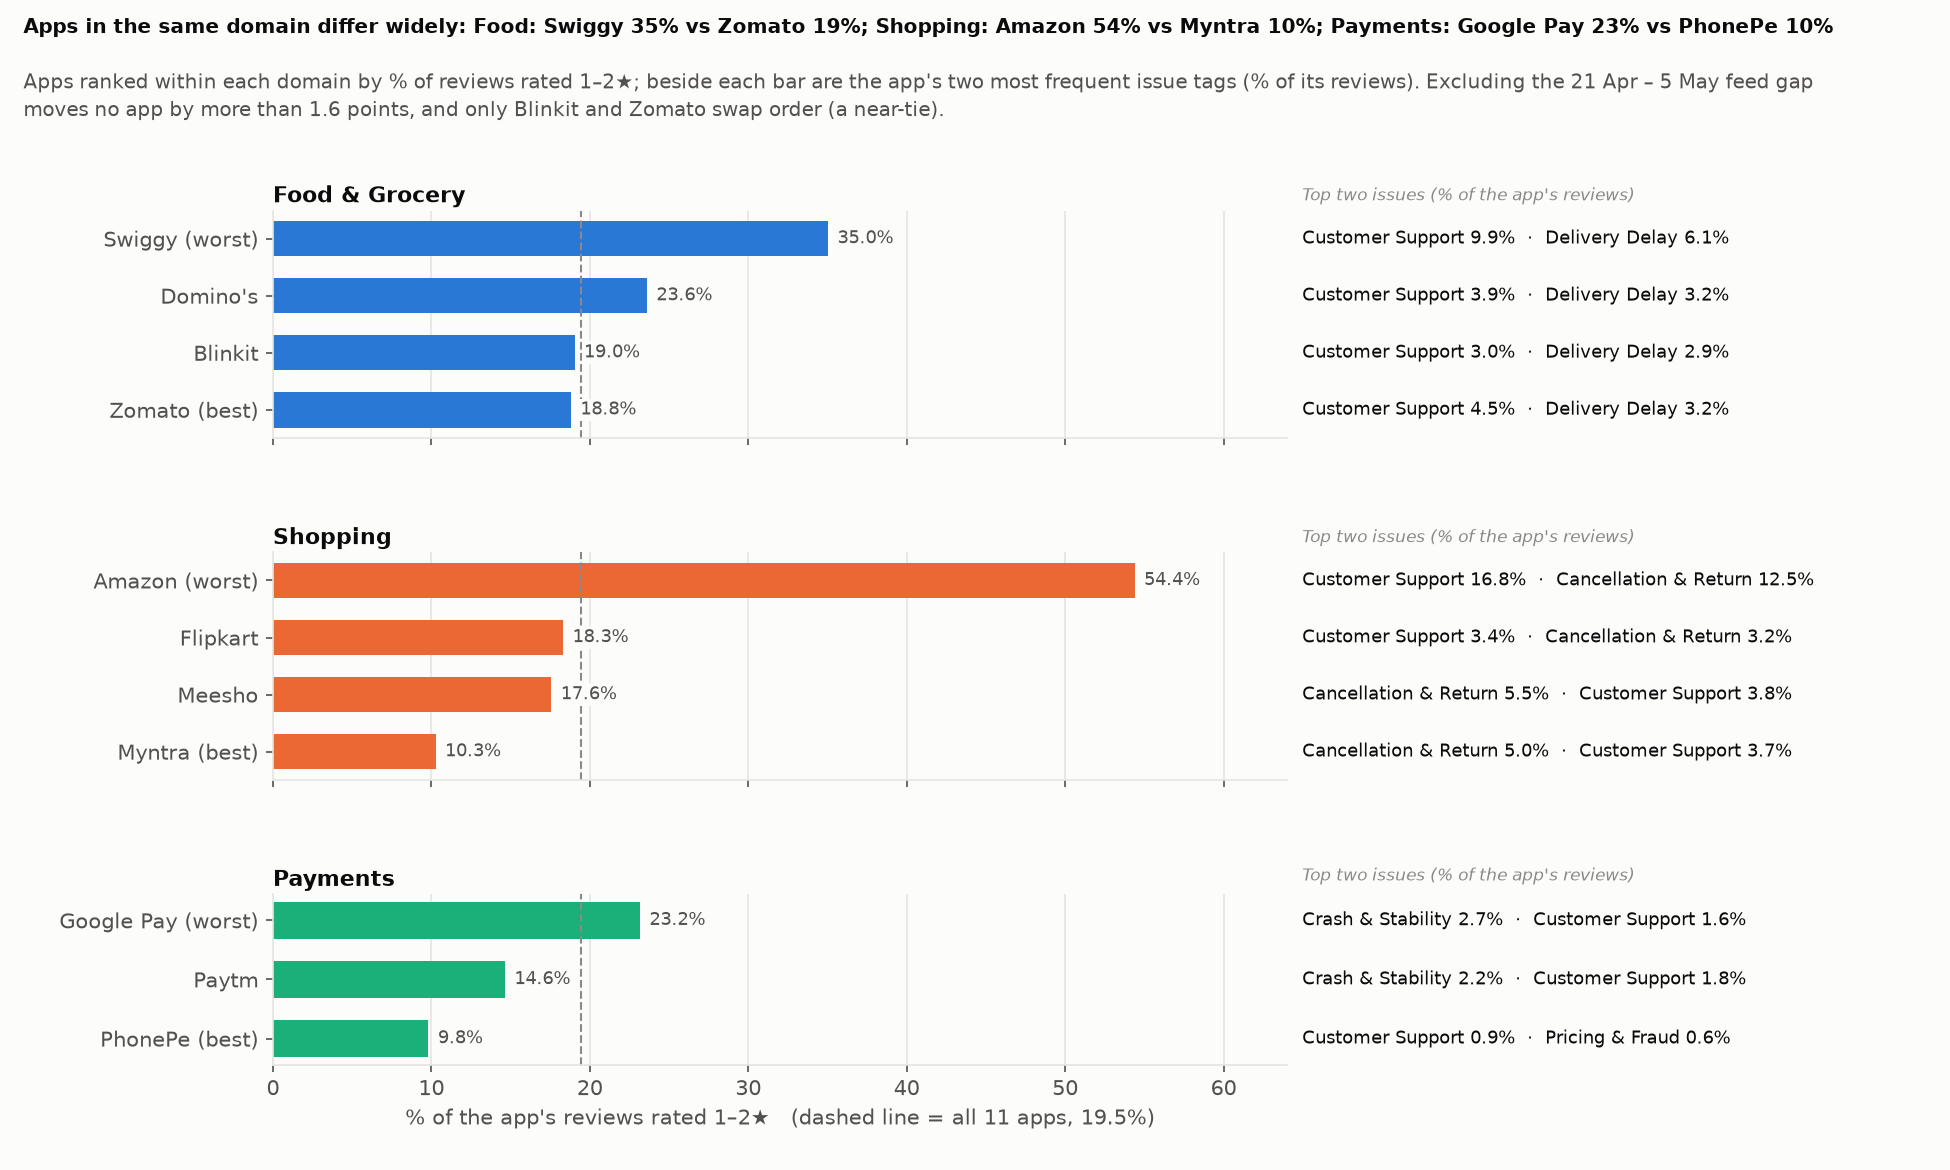

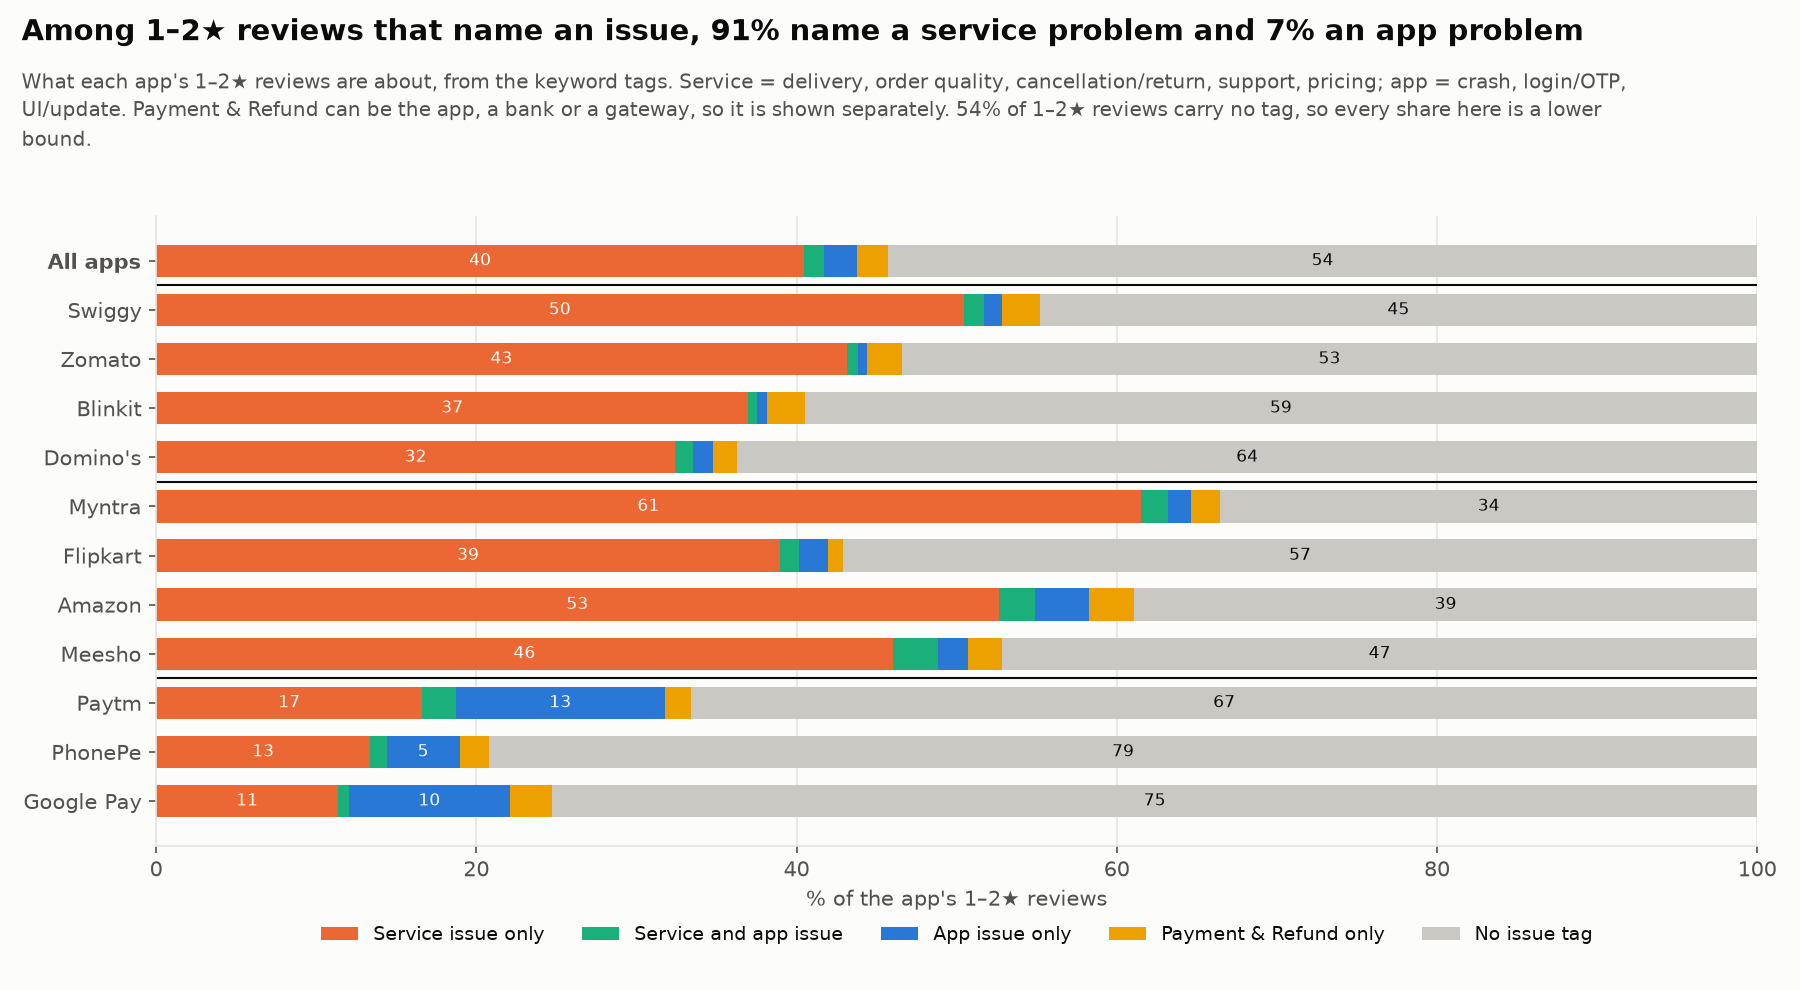

In [5]:
show("eda/eda_14_within_domain.png", 800)
show("eda/eda_15_complaint_attribution.png", 800)

### 0.2 Unit 2: predictive model (held-out test set)

Target `is_problematic` = a 1–2★ rating (19.5%). The inputs are 200 SVD components of TF-IDF text features plus 15 structural features (issue flags, VADER scores, length, upvotes). The split is a stratified 80/20 split: 910,389 training reviews and 227,598 held-out test reviews (`MODEL_EVALUATION.md`).

Review 1 fitted TF-IDF, SVD and the scaler on all rows. `scripts/25_train_only_preprocessing_check.py` refits them on the training rows only; the table compares both setups on the same test reviews.

In [6]:
pre = pd.read_csv(DATA / "model_train_only_preprocessing.csv")
base = pd.read_csv(DATA / "baseline_results.csv")
display(base[["model", "accuracy", "precision", "recall", "f1_score", "pr_auc"]].round(4))
display(pre)
diff = (pre.set_index(["model", "preprocessing"]).groupby(level=0).diff().abs().max().max())
print(f"Largest change in any metric between the two setups: {diff:.4f}")
oot = pd.read_csv(DATA / "model_results_out_of_time.csv")
print("Out-of-time test (train Apr–Aug, test 1–20 Sep):")
oot[["model", "n_train", "n_test", "precision", "recall", "f1_score", "pr_auc"]].round(4)

,model,accuracy,precision,recall,f1_score,pr_auc
0,majority_class_baseline (always 0),0.8053,0.0,0.0,0.0,0.1947


,model,preprocessing,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,logistic_regression,fitted on all rows (Review 1),0.9216,0.7672,0.8579,0.8100,0.9400,0.8710
1,logistic_regression,fitted on training rows only,0.9223,0.7698,0.8575,0.8113,0.9402,0.8711
2,random_forest,fitted on all rows (Review 1),0.9143,0.7372,0.8701,0.7982,0.9411,0.8735
3,random_forest,fitted on training rows only,0.9141,0.7364,0.8703,0.7978,0.9410,0.8739


Largest change in any metric between the two setups: 0.0026
Out-of-time test (train Apr–Aug, test 1–20 Sep):


,model,n_train,n_test,precision,recall,f1_score,pr_auc
0,logistic_regression,1008932,129055,0.7481,0.8493,0.7955,0.8617
1,random_forest,1008932,129055,0.7207,0.8617,0.7849,0.8660


## 1. Data used in Review 2

Review 1 collected, cleaned and tagged the reviews (`data/tagged/`). Stage 1 of Review 2 (#131, #132) turned them into the two inputs of this review:

* **Daily series per app** (`data/timeseries/daily_app.csv`): reviews, 1–2★ reviews, mean rating and the nine keyword issue counts per app per day — the input of the time-series method.
* **Two text corpora**: 1–2★ complaints and 4–5★ praise, cleaned and lemmatised, with document-term matrices per domain — the input of the text-mining method.

**Known data issue — the feed gap.** From 21 Apr to 5 May the Play Store "newest" feed returned too few reviews for Swiggy, Blinkit, Domino's, Flipkart and Amazon, and those it returned were mostly negative. These app-days are flagged (`feed_gap`) and handled in every stage: a dummy input in ARIMA, excluded from shares in the combined insights, and noted for every release that falls in it.

In [7]:
daily = pd.read_csv(TS / "daily_app.csv", parse_dates=["day"])
ts_sum = load_json("timeseries_summary.json")
per_app = (daily.groupby(["domain", "app_name"])
           .agg(days=("day", "nunique"), reviews=("reviews", "sum"), neg_reviews=("neg_reviews", "sum"),
                feed_gap_days=("feed_gap", "sum"))
           .assign(neg_share_pct=lambda d: (100 * d.neg_reviews / d.reviews).round(1))
           .reset_index())
print(f"{daily.day.min():%d %b %Y} – {daily.day.max():%d %b %Y}: {per_app.reviews.sum():,} reviews, "
      f"{per_app.neg_reviews.sum():,} rated 1–2★ ({100*per_app.neg_reviews.sum()/per_app.reviews.sum():.1f}%)")
print("Feed gap:", ts_sum["feed_gap"]["window"], "for", ", ".join(ts_sum["feed_gap"]["apps"]))
per_app

01 Apr 2026 – 20 Sep 2026: 1,137,987 reviews, 221,581 rated 1–2★ (19.5%)
Feed gap: ['2026-04-21', '2026-05-05'] for Swiggy, Blinkit, Domino's, Flipkart, Amazon


,domain,app_name,days,reviews,neg_reviews,feed_gap_days,neg_share_pct
0,Food & Grocery,Blinkit,173,228446,43480,15,19.0
1,Food & Grocery,Domino's,173,43629,10298,15,23.6
2,Food & Grocery,Swiggy,173,74768,26193,15,35.0
3,Food & Grocery,Zomato,173,150560,28309,0,18.8
4,Payments,Google Pay,173,20320,4706,0,23.2
5,Payments,Paytm,173,44658,6539,0,14.6
6,Payments,PhonePe,173,88535,8689,0,9.8
7,Shopping,Amazon,173,32753,17811,15,54.4
8,Shopping,Flipkart,173,266285,48761,15,18.3
9,Shopping,Meesho,173,102686,18042,0,17.6


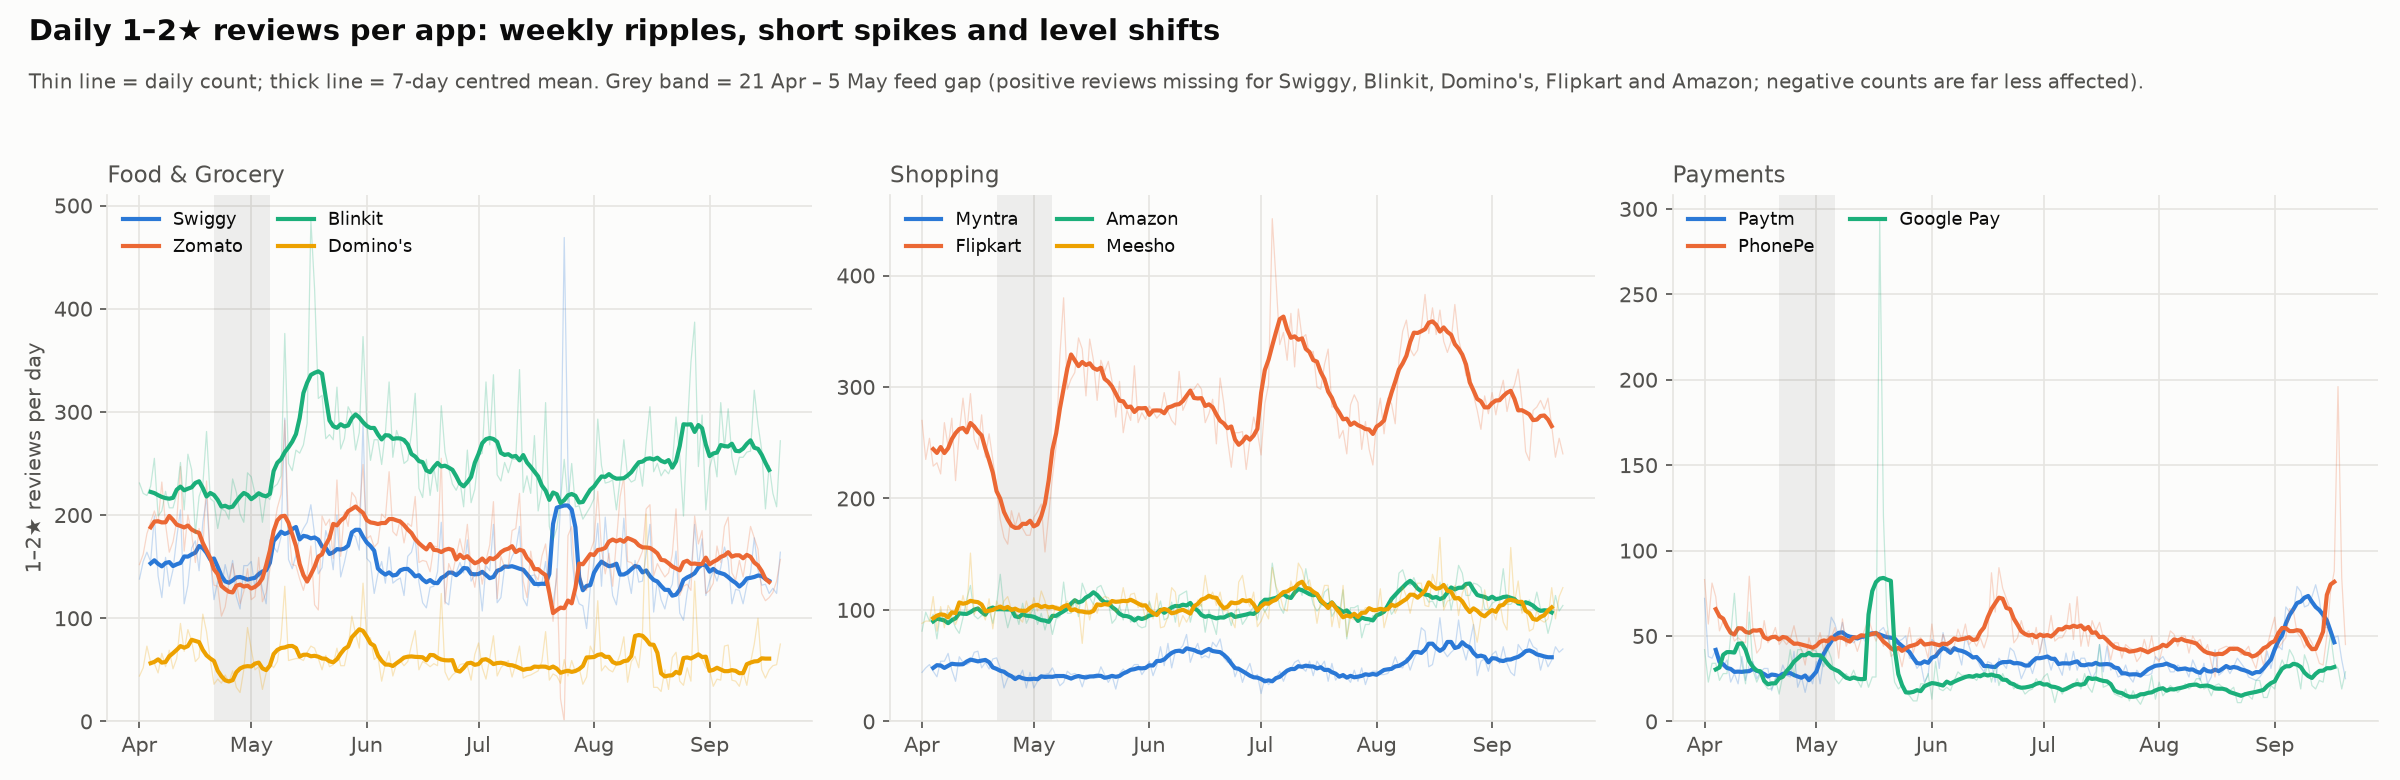

In [8]:
show("timeseries/ts_01_daily_negative_reviews.png")

## 2. Method 1 — Text mining (Stage 1 #132, Stage 2 #134 and #136)

**Question:** what are users actually complaining about in each app, and how negative is each complaint theme?

### 2.1 Preparation (#132)

Two corpora are built: complaints (1–2★) and praise (4–5★). A review is kept if it has at least three content words after cleaning (lowercase, links and brand phrases removed, contractions expanded, negations such as "not" kept, common Hinglish words mapped, WordNet lemmatisation).

In [9]:
tm = load_json("textmining_summary.json")
display(pd.DataFrame(tm["selection"]).T if isinstance(tm["selection"], dict) else pd.DataFrame(tm["selection"]))
print("Median content words kept:", tm["median_tokens_kept"])
print("\nCleaning example:")
ex = tm["cleaning_examples"][0]
for k, v in (ex.items() if isinstance(ex, dict) else enumerate(ex)):
    print(f"  {k}: {str(v)[:160]}")

,reviews,kept,dropped_too_short,kept_pct
complaint,221581.0,167357.0,54224.0,75.5
praise,871380.0,166929.0,704451.0,19.2


Median content words kept: {'complaint': 11.0, 'praise': 4.0}

Cleaning example:
  app_name: Blinkit
  content: PLEASE STOP CHEATING US BY CHARGING DELIVERY CHARGES FOR ORDERS ABOVE 100. YOU PEOPLE ARE NUMBER 1 FRAUDS.
  clean_text: stop cheat charge delivery charge order people number fraud
  kept: True


### 2.2 Topic models and sentiment (#134)

One **NMF model on TF-IDF** per domain (Food & Grocery K = 6, Shopping K = 6, Payments K = 5) on the complaint corpus. Each review gets its dominant topic, and each topic's severity is the mean VADER sentiment of its reviews.

In [10]:
topics = pd.read_csv(TM / "topics.csv")
comp = topics[topics["group"] == "complaint"].copy()
comp["top_terms"] = comp["top_terms"].str.split("; ").str[:8].str.join(", ")
comp[["domain", "topic_id", "topic_label", "top_terms"]]

,domain,topic_id,topic_label,top_terms
0,Food & Grocery,1,Order Cancellation & Refund,"order, not, cancel, deliver, refund, get, cancel order, food"
1,Food & Grocery,2,Customer Support & Bot Loop,"customer, worst, service, support, customer service, worst customer, customer support, no"
2,Food & Grocery,3,Excessive Delivery & Handling Charges,"charge, high, delivery charge, charge high, extra, price, delivery, much"
3,Food & Grocery,4,Poor Food Quality & Stale Items,"bad, good, not good, not, service, bad experience, bad service, experience"
4,Food & Grocery,5,Delivery Delays & Rider Tracking,"delivery, time, late, partner, delivery partner, late delivery, delivery time, boy"
5,Food & Grocery,6,COD & Payment Option Failures,"cash, cash delivery, available, not available, not, delivery not, delivery, option"
6,Shopping,1,Return Rejection & Defective Products,"product, return, refund, product not, buy, quality, good, wrong"
7,Shopping,2,Customer Service & Escalation Failure,"customer, support, service, care, customer care, customer service, customer support, no"
8,Shopping,3,Courier Delays & Delivery Agent Issues,"delivery, delivery service, delivery not, late, cash, cash delivery, time, worst delivery"
9,Shopping,4,Poor Shopping Experience & Fabric Quality,"bad, service, bad experience, bad service, experience, service bad, bad delivery, bad not"


In [11]:
# Recompute topic sizes and sentiment from the per-review topic assignment and compare with the saved table.
rt = pd.read_csv(TM / "review_topics.csv.gz")
rt = rt[rt["group"] == "complaint"]
recomputed = (rt.groupby(["domain", "dominant_topic_label"])
              .agg(reviews=("review_id", "size"), mean_sentiment=("sentiment_compound", "mean"),
                   pct_strongly_neg=("sentiment_compound", lambda s: 100 * (s <= -0.5).mean()))
              .reset_index())
recomputed["share_of_domain_pct"] = 100 * recomputed["reviews"] / recomputed.groupby("domain")["reviews"].transform("sum")
saved = pd.read_csv(TM / "topic_sentiment.csv")
check = recomputed.merge(saved, left_on=["domain", "dominant_topic_label"], right_on=["domain", "dominant_topic_label"],
                         suffixes=("", "_saved"))
print(f"{len(rt):,} complaint reviews with a topic; "
      f"counts match saved table: {(check.reviews == check.reviews_saved).all()}; "
      f"max sentiment difference: {(check.mean_sentiment - check.mean_sentiment_saved).abs().max():.4f}")
(recomputed.sort_values(["domain", "mean_sentiment"])
 .round({"mean_sentiment": 3, "pct_strongly_neg": 1, "share_of_domain_pct": 1}))

167,357 complaint reviews with a topic; counts match saved table: True; max sentiment difference: 0.0000


,domain,dominant_topic_label,reviews,mean_sentiment,pct_strongly_neg,share_of_domain_pct
5,Food & Grocery,Poor Food Quality & Stale Items,10412,-0.437,58.8,12.6
1,Food & Grocery,Customer Support & Bot Loop,15640,-0.402,55.6,18.9
2,Food & Grocery,Delivery Delays & Rider Tracking,14856,-0.294,39.1,18.0
4,Food & Grocery,Order Cancellation & Refund,28656,-0.271,36.2,34.7
3,Food & Grocery,Excessive Delivery & Handling Charges,8730,-0.214,24.4,10.6
0,Food & Grocery,COD & Payment Option Failures,4309,-0.116,17.6,5.2
8,Payments,Customer Support Unresponsiveness,2404,-0.225,40.0,18.0
10,Payments,Failed Transfers & Debited Amounts,6909,-0.154,27.4,51.8
6,Payments,Account Blocking & AutoPay Issues,1379,-0.130,21.1,10.3
9,Payments,Device Environment & Security Scan Errors,1382,-0.114,18.0,10.4


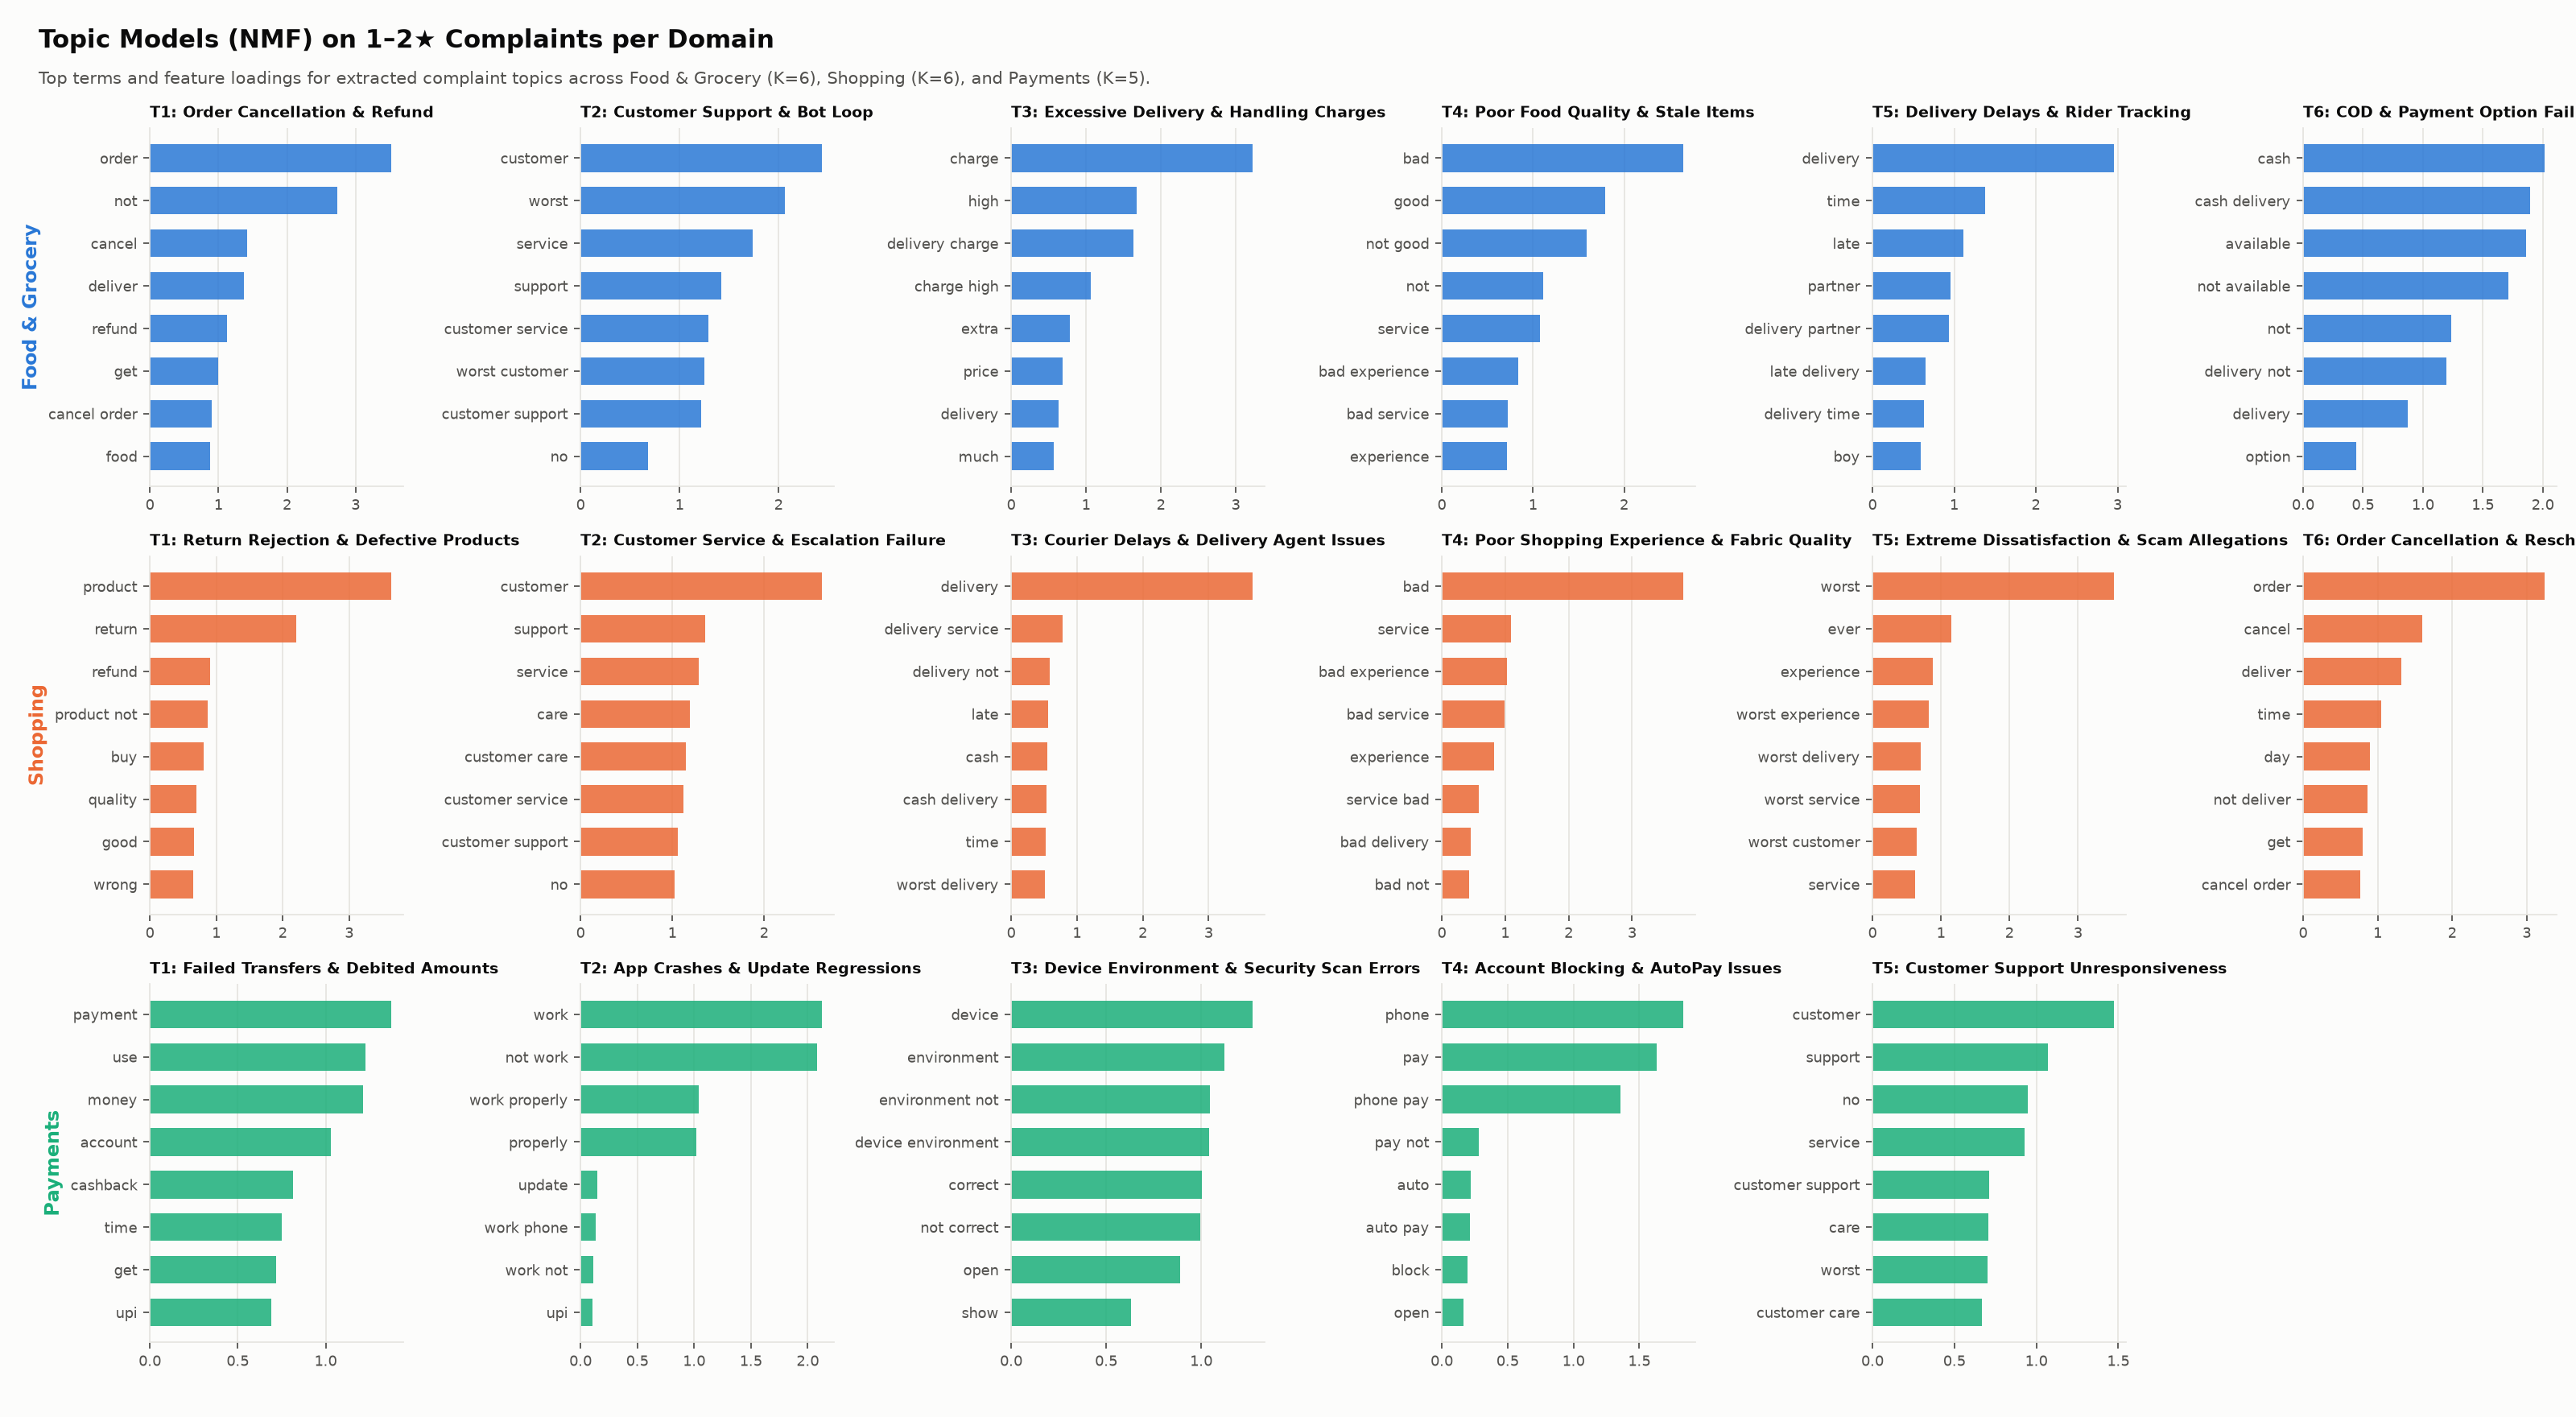

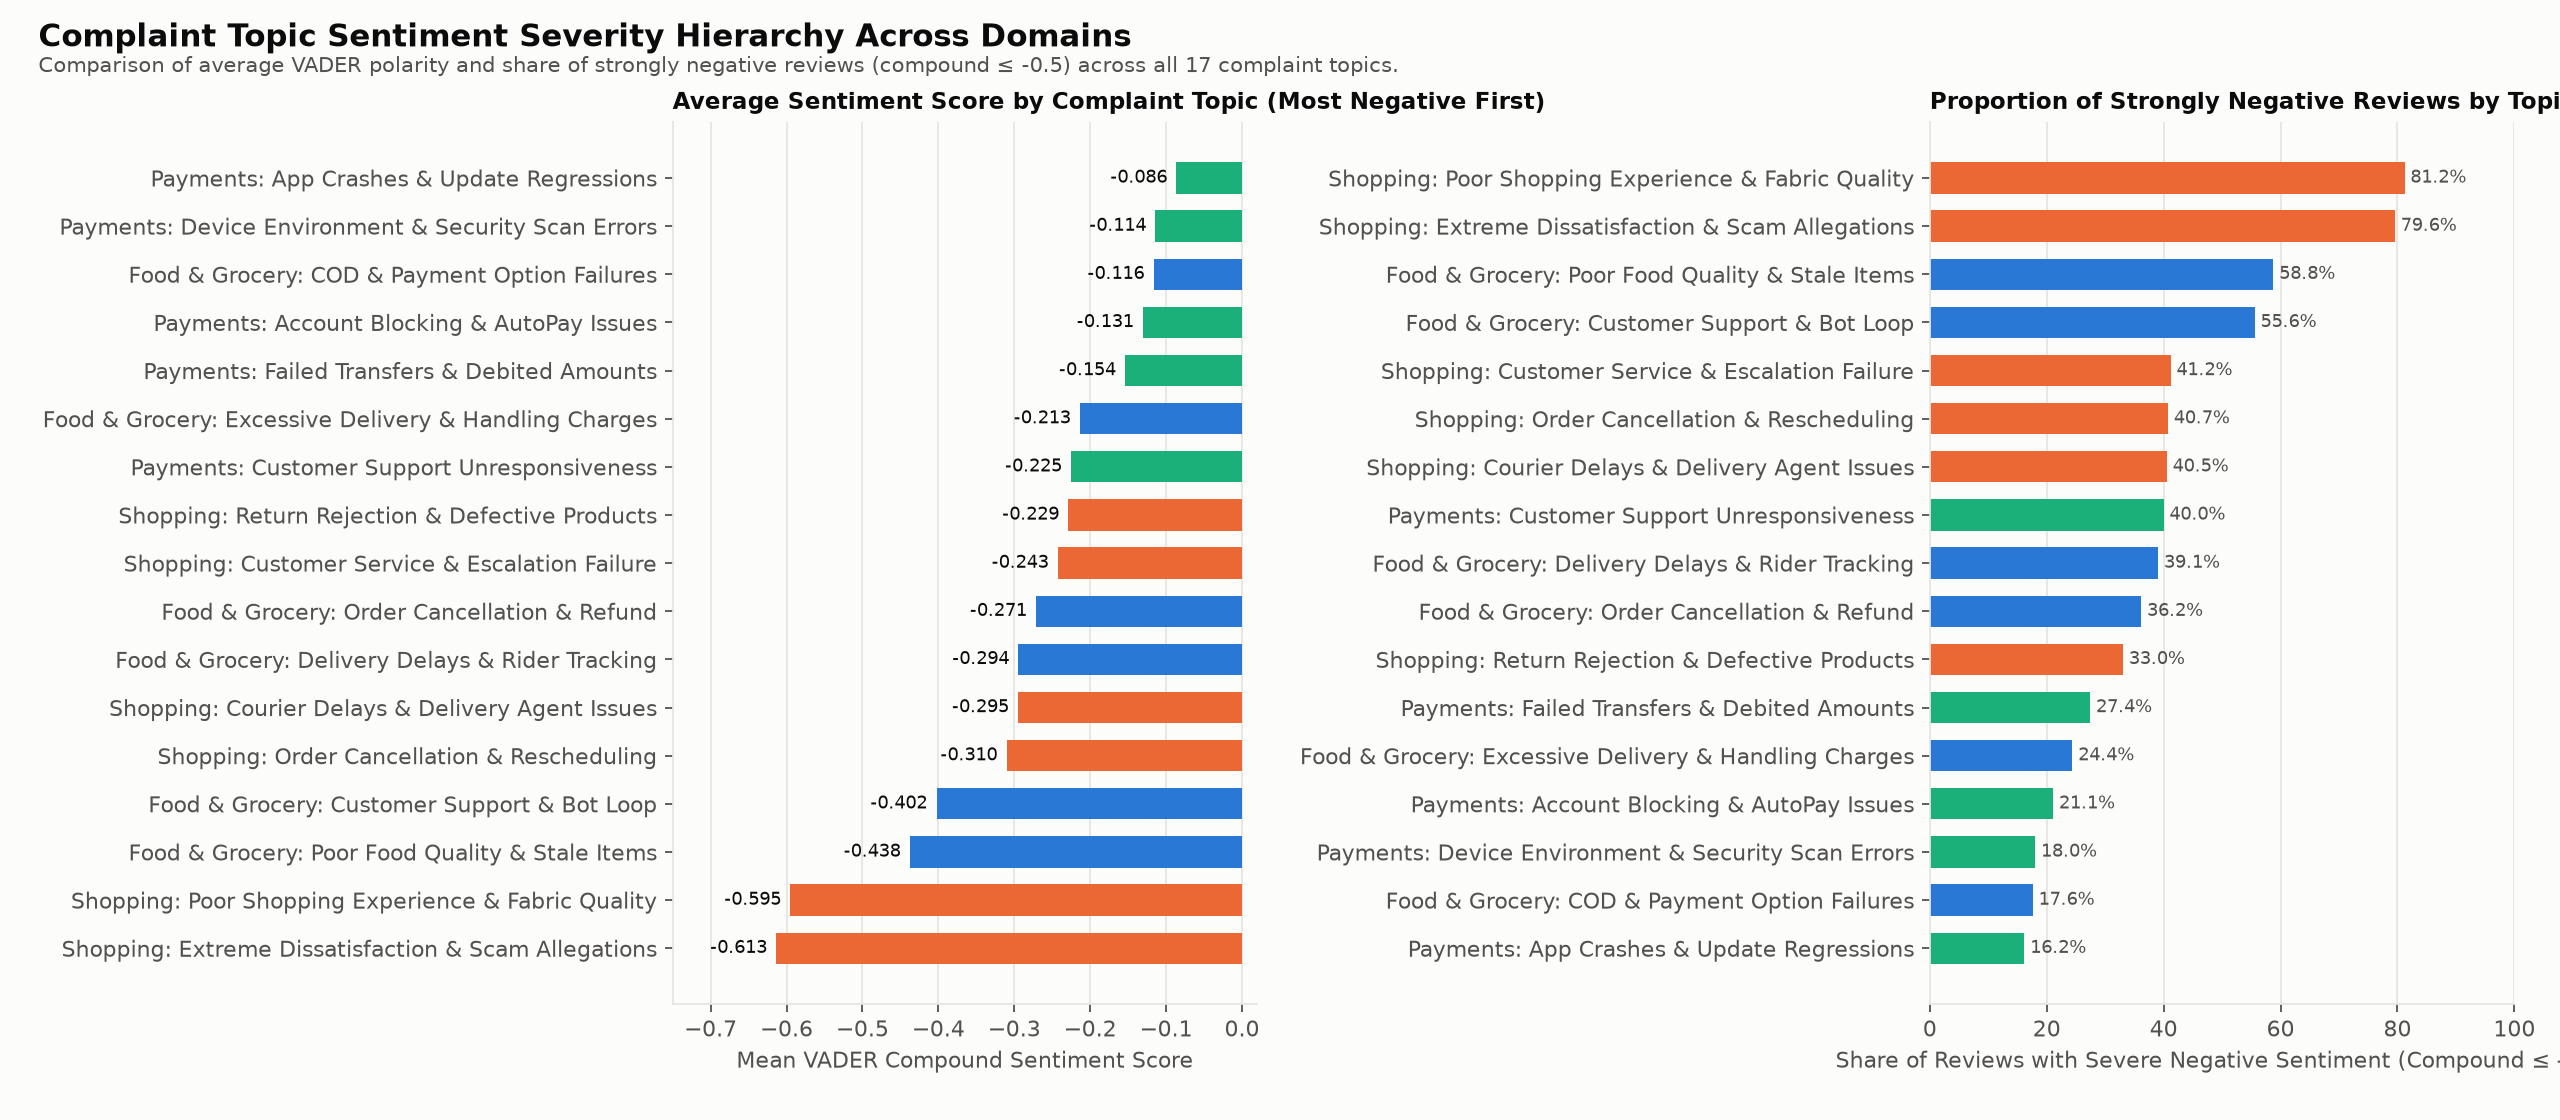

In [12]:
show("textmining/tm_02_complaint_topics.png")
show("textmining/tm_05_topic_sentiment.png")

### 2.3 Evaluation and interpretation (#136)

* **Number of topics** chosen per domain from topic coherence (UMass and NPMI) over K = 3 … 10.
* **Comparison with the nine keyword issue tags** from Review 1: topics recover the tagged issues and also explain many reviews the keywords missed.

,domain,k,is_chosen,mean_umass,mean_npmi
0,Food & Grocery,6,True,-2.2859,0.1949
1,Shopping,6,True,-2.5537,0.1673
2,Payments,5,True,-2.4020,0.2016


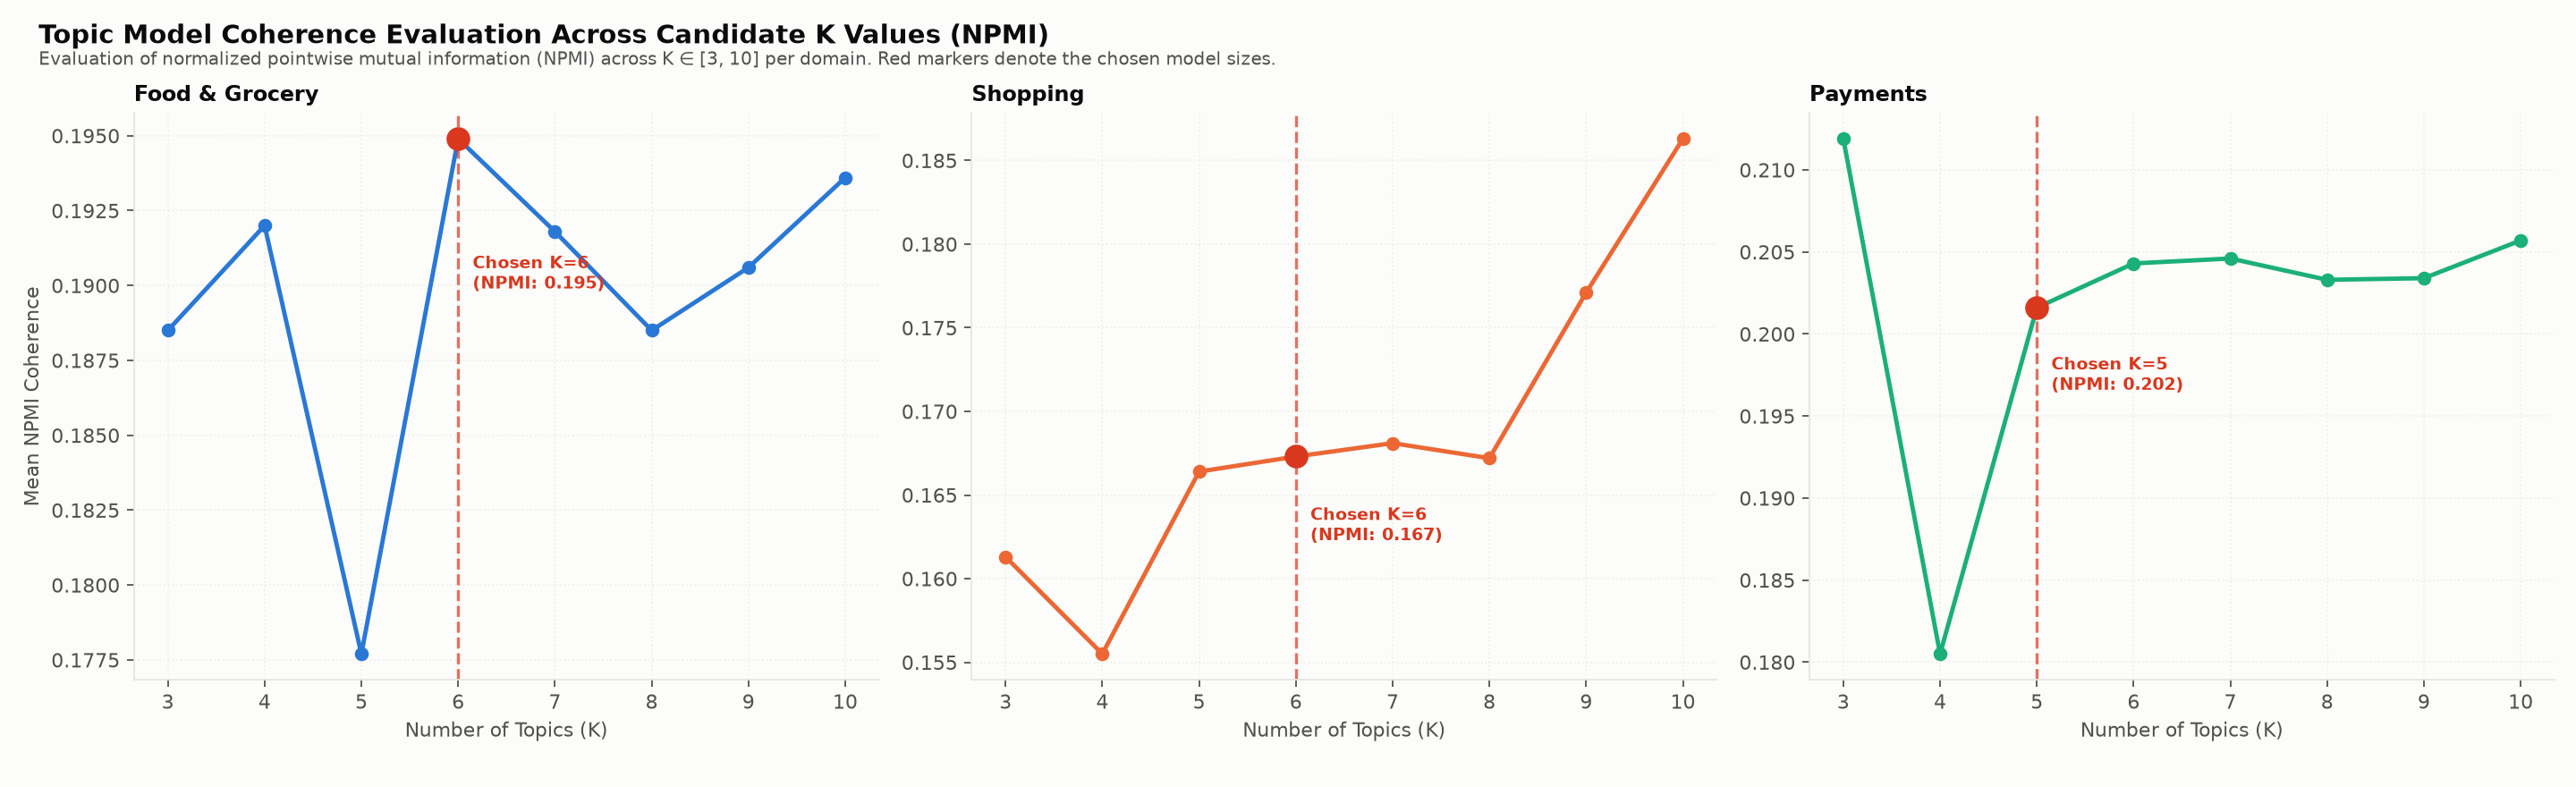

In [13]:
coh = pd.read_csv(TM / "coherence_scores.csv")
display(coh[coh["is_chosen"]].reset_index(drop=True))
show("textmining/tm_06_coherence_evaluation.png", 800)

In [14]:
ov = pd.read_csv(TM / "topic_keyword_overlap.csv")
ov[["domain", "topic_label", "reviews", "Untagged_Pct"]].rename(columns={"Untagged_Pct": "no keyword tag %"})

,domain,topic_label,reviews,no keyword tag %
0,Food & Grocery,Order Cancellation & Refund,28656,45.6
1,Food & Grocery,Customer Support & Bot Loop,15640,23.0
2,Food & Grocery,Excessive Delivery & Handling Charges,8730,60.2
3,Food & Grocery,Poor Food Quality & Stale Items,10412,58.5
4,Food & Grocery,Delivery Delays & Rider Tracking,14856,39.4
5,Food & Grocery,COD & Payment Option Failures,4309,79.9
6,Payments,Failed Transfers & Debited Amounts,6909,71.9
7,Payments,App Crashes & Update Regressions,1267,77.4
8,Payments,Device Environment & Security Scan Errors,1382,48.7
9,Payments,Account Blocking & AutoPay Issues,1379,76.6


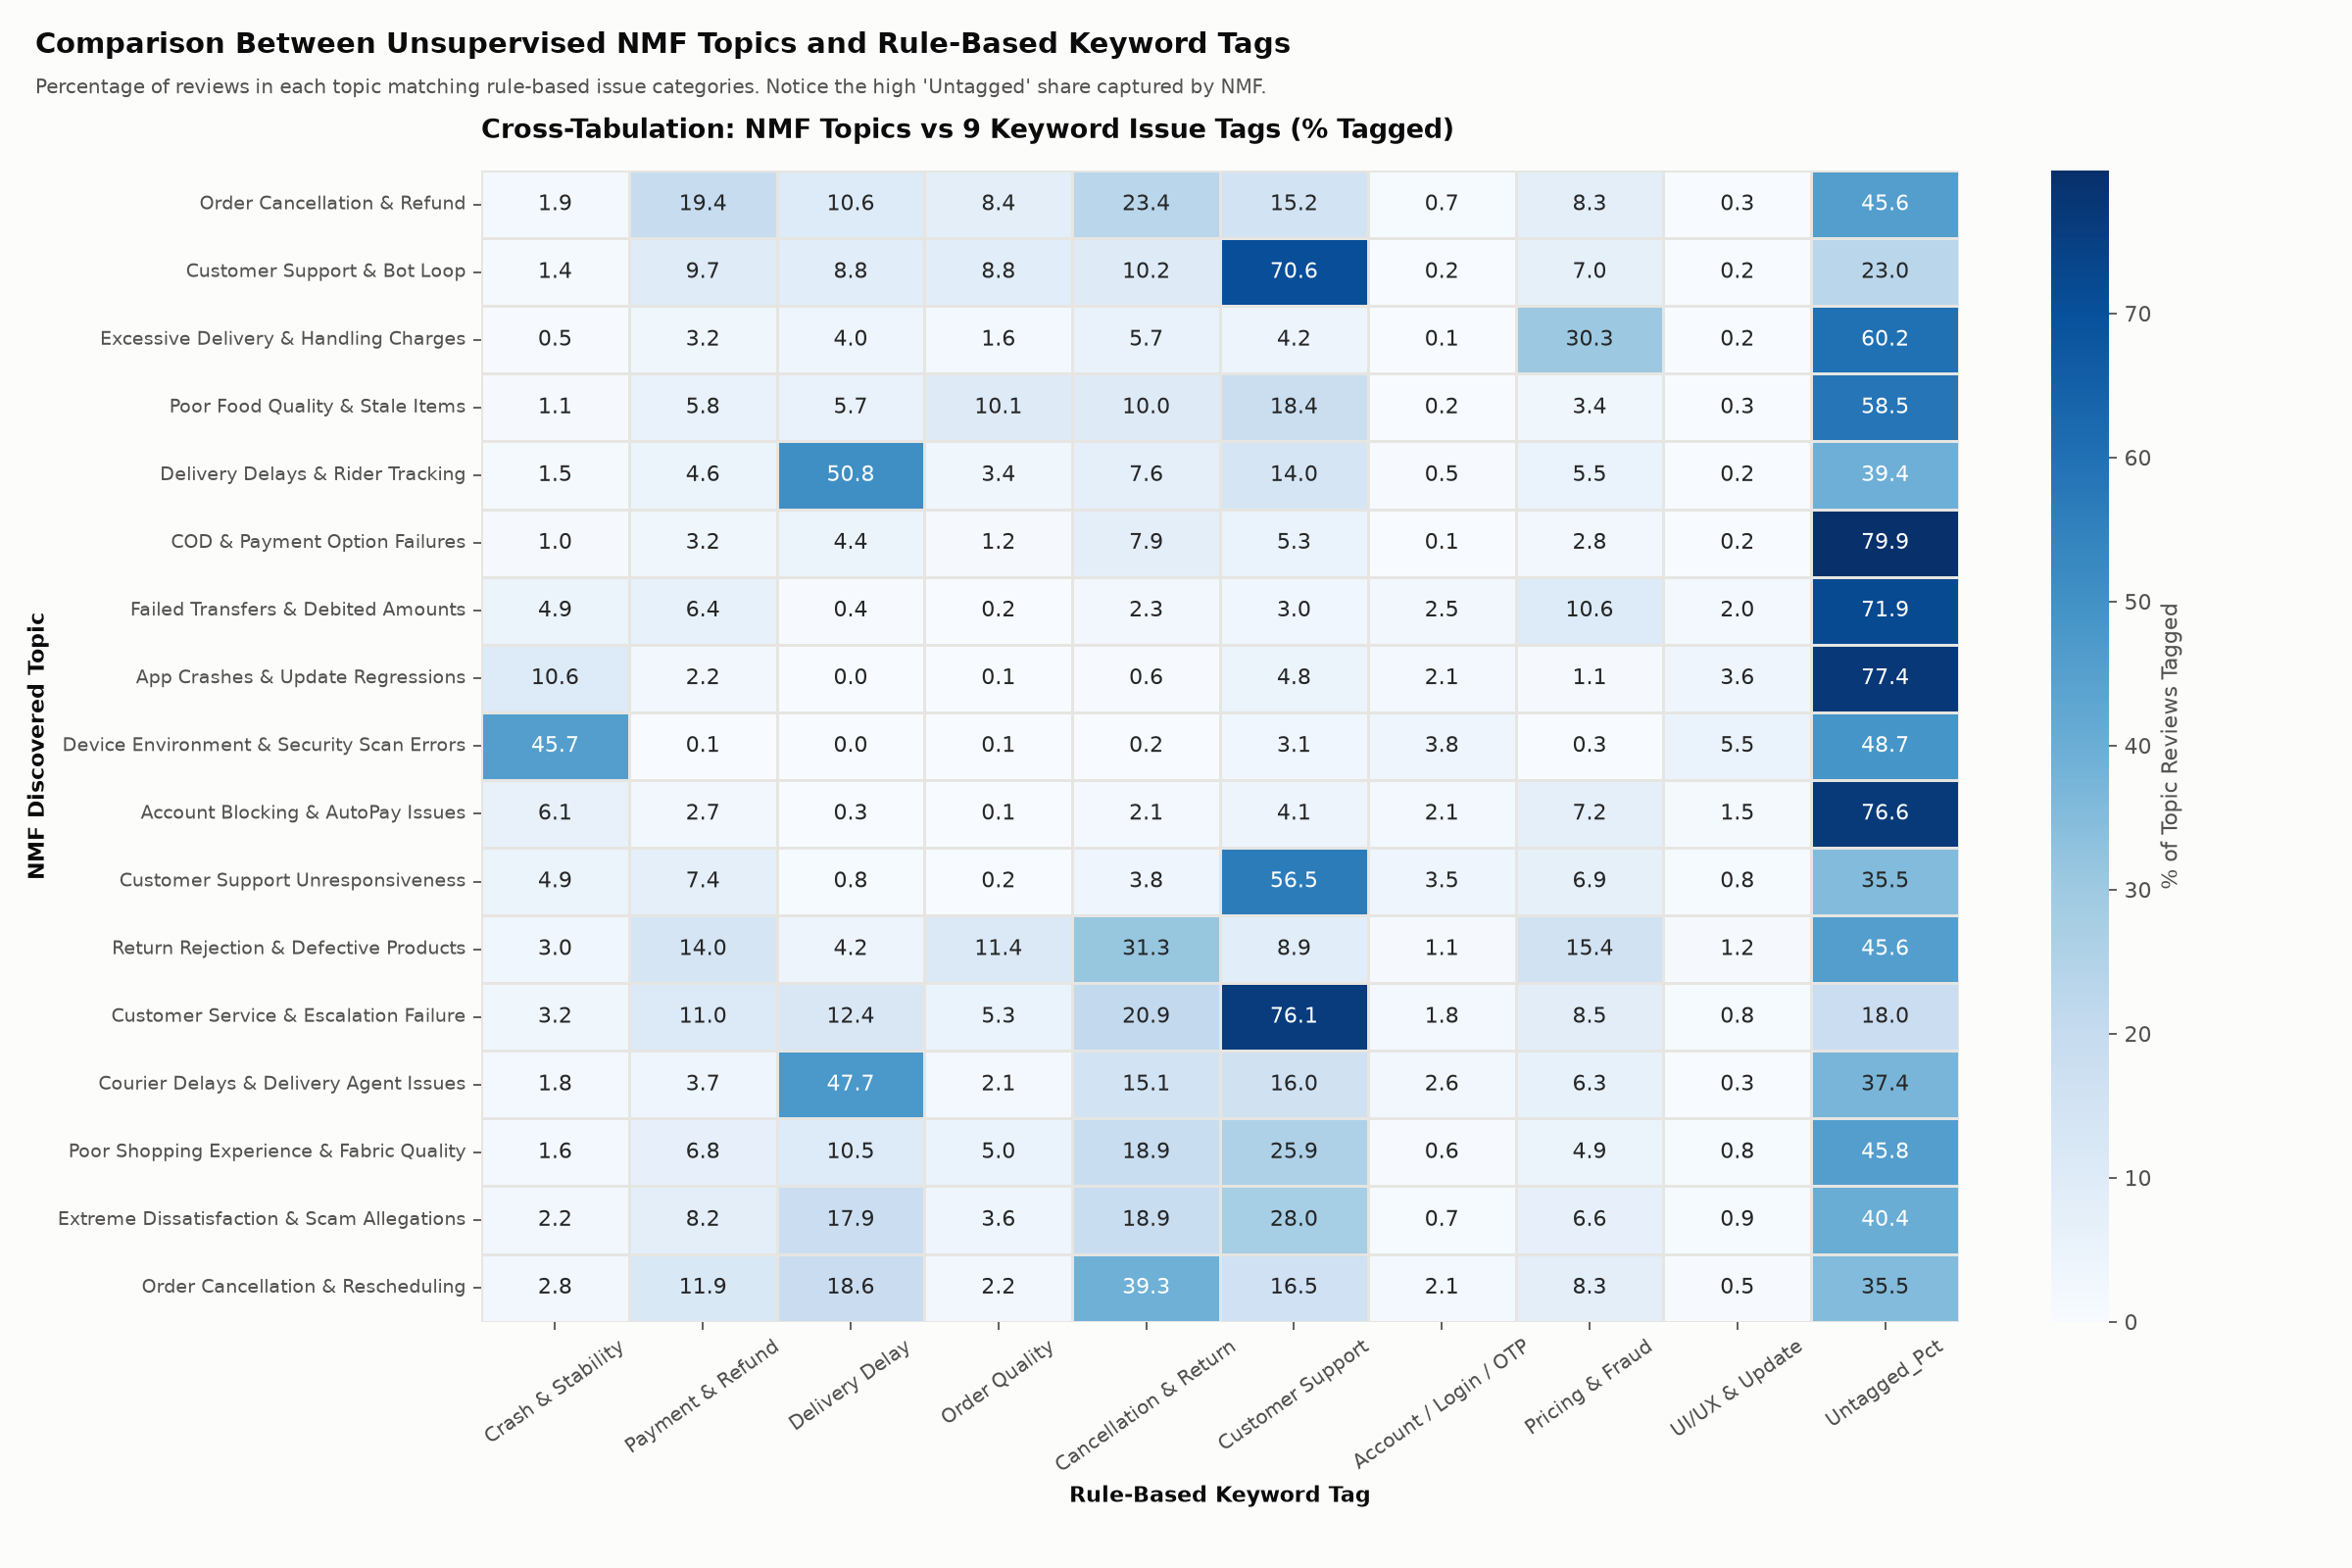

In [15]:
show("textmining/tm_07_topic_vs_keyword_tags.png", 800)

**NMF compared with LDA.** The two models get the same document-term matrix and the same K for each domain. Each is fitted on 80% of the domain's complaints and scored on the unseen 20% (`scripts/23_topic_model_comparison.py`):

* **Held-out NPMI:** do a topic's top 10 terms really occur together in unseen reviews?
* **Topic diversity:** the share of distinct terms among all topics' top 10 terms.

,domain,model,k,train_reviews,test_reviews,heldout_npmi,topic_diversity,largest_topic_share,fit_seconds
0,Food & Grocery,NMF (TF-IDF),6,66082,16521,0.1923,0.917,0.341,1.2
1,Food & Grocery,LDA (counts),6,66082,16521,0.1168,0.683,0.228,42.1
2,Shopping,NMF (TF-IDF),6,57130,14283,0.1635,0.883,0.262,0.9
3,Shopping,LDA (counts),6,57130,14283,0.1197,0.733,0.263,39.3
4,Payments,NMF (TF-IDF),5,10672,2669,0.1523,0.940,0.498,0.1
5,Payments,LDA (counts),5,10672,2669,0.0759,0.760,0.286,7.2


NMF has the higher held-out NPMI in 3 of 3 domains.


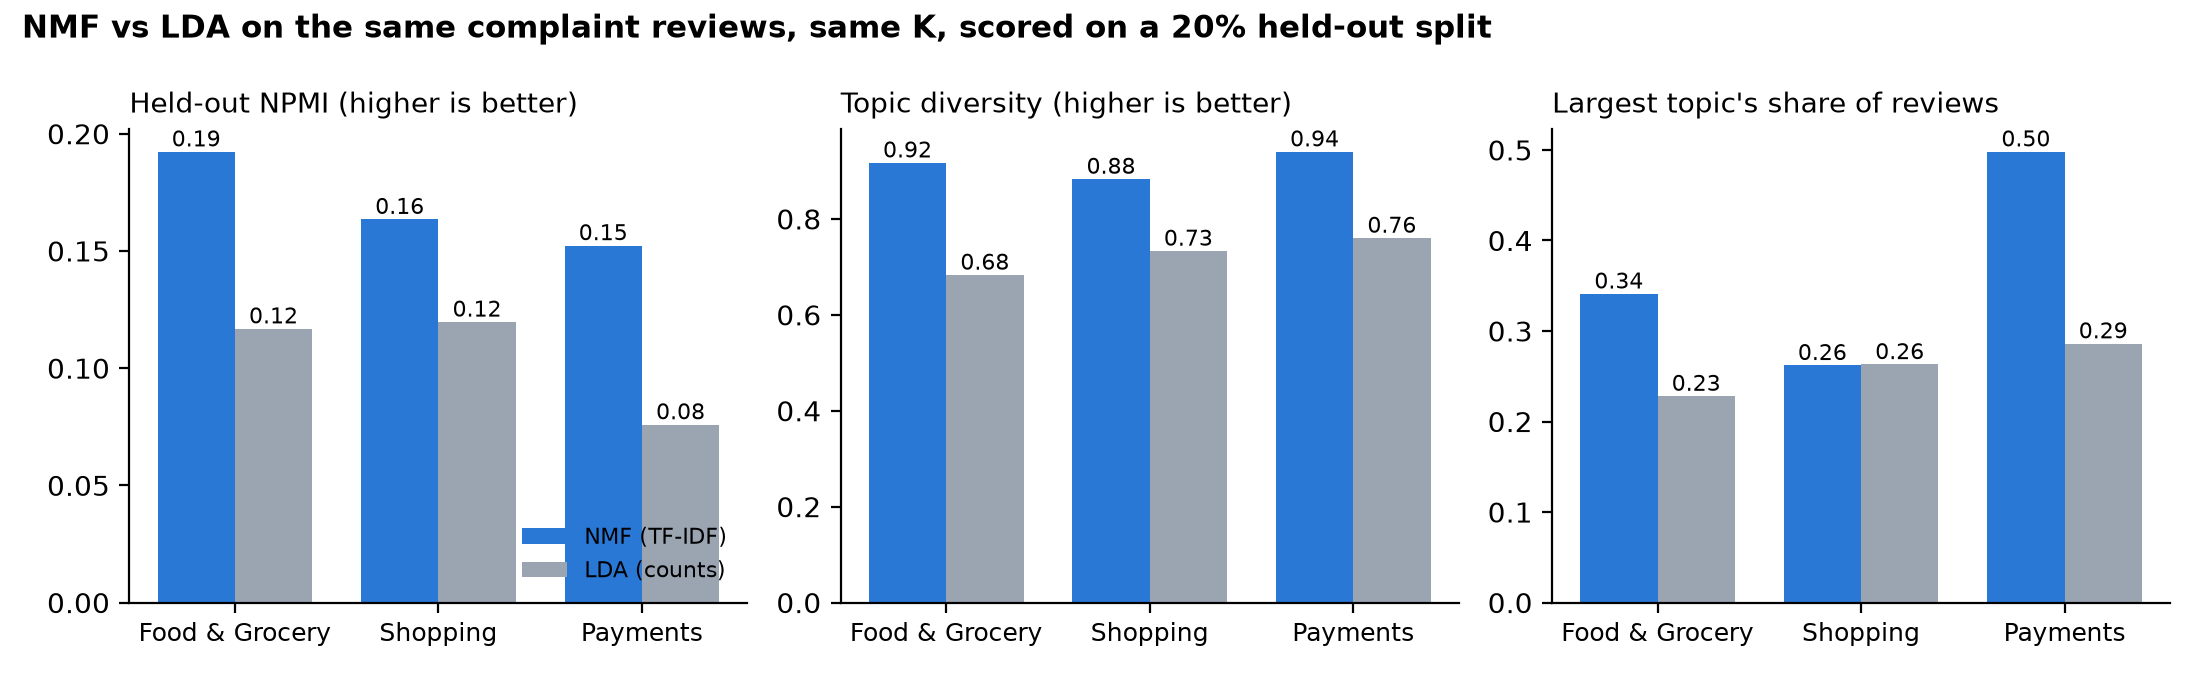

In [16]:
cmp = pd.read_csv(TM / "topic_model_comparison.csv")
display(cmp[["domain", "model", "k", "train_reviews", "test_reviews", "heldout_npmi", "topic_diversity",
             "largest_topic_share", "fit_seconds"]])
wins = (cmp.pivot(index="domain", columns="model", values="heldout_npmi")
        .pipe(lambda p: (p["NMF (TF-IDF)"] > p["LDA (counts)"]).sum()))
print(f"NMF has the higher held-out NPMI in {wins} of {cmp.domain.nunique()} domains.")
show("textmining/tm_10_nmf_vs_lda.png", 850)

**Text-mining findings.** In every domain one operational theme dominates — order cancellation and refunds in Food & Grocery, return rejection and defective products in Shopping, failed transfers with money debited in Payments — but the **angriest** reviews come from smaller themes (poor food quality, scam allegations, unresponsive support). Volume and severity rank topics differently, which is why the recommendations in Section 5 name both a "fix first" and a "most damaging" topic. Details: `TEXT_MINING.md`.

## 3. Method 2 — Time-series analysis (Stage 1 #131, Stage 3 #135, Stage 4 #137)

**Question:** how many 1–2★ reviews will each app get in the coming weeks, and which days were unusual?

### 3.1 Patterns (#131)

STL decomposition with a weekly season, ADF/KPSS stationarity tests and weekday effects per app.

In [17]:
pat = pd.read_csv(TS / "patterns_by_app.csv")
pat[["app_name", "domain", "mean_neg_per_day", "trend_strength", "seasonal_strength", "trend_change_pct",
     "peak_weekday", "low_weekday", "suggested_d", "suggested_D"]]

,app_name,domain,mean_neg_per_day,trend_strength,seasonal_strength,trend_change_pct,peak_weekday,low_weekday,suggested_d,suggested_D
0,Swiggy,Food & Grocery,151.40,0.106,0.254,-16.2,Sun,Mon,0,0
1,Zomato,Food & Grocery,164.59,0.472,0.555,-11.1,Sun,Tue,1,0
2,Blinkit,Food & Grocery,251.33,0.493,0.408,13.1,Sun,Tue,1,0
3,Domino's,Food & Grocery,59.53,0.135,0.259,-18.2,Sun,Mon,0,0
4,Myntra,Shopping,50.60,0.601,0.200,21.5,Thu,Fri,0,0
5,Flipkart,Shopping,281.86,0.814,0.251,5.4,Sun,Fri,0,0
6,Amazon,Shopping,102.95,0.485,0.207,14.0,Sat,Fri,0,0
7,Meesho,Shopping,104.29,0.235,0.242,2.2,Sun,Fri,0,0
8,Paytm,Payments,37.80,0.674,0.000,60.1,Sat,Sun,0,0
9,PhonePe,Payments,50.23,0.394,0.102,3.0,Fri,Sun,0,0


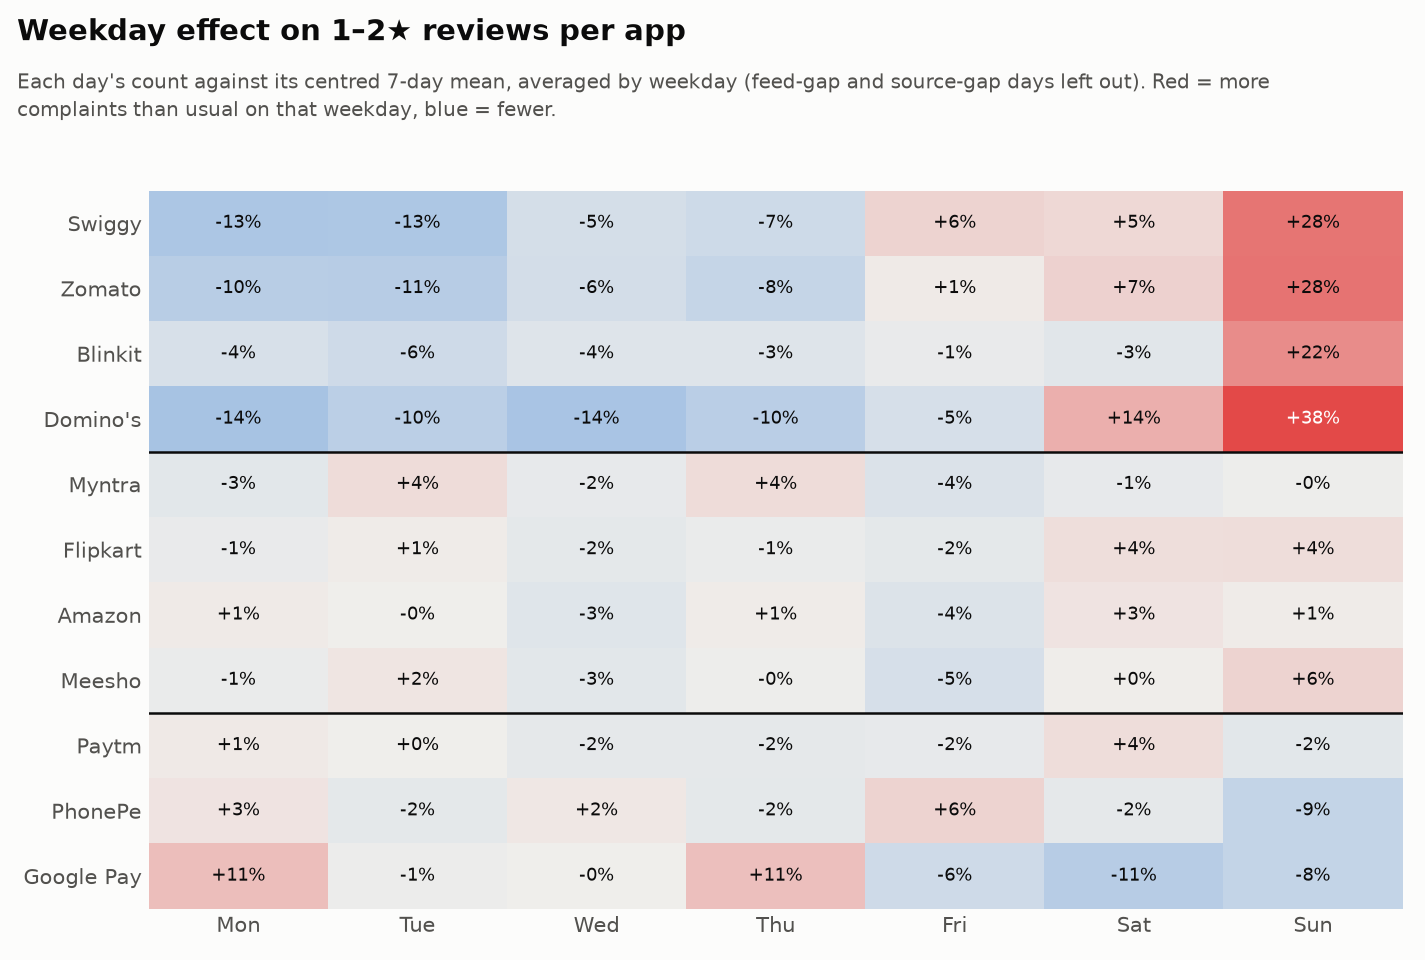

In [18]:
show("timeseries/ts_03_weekday_effect.png", 800)

### 3.2 ARIMA forecasting with a rolling backtest (#135)

ARIMA per app (SARIMA with a lag-7 season for the four food apps, a feed-gap dummy for the five affected apps), orders chosen by AICc. Each model is tested with a **rolling-origin backtest** — 9 origins, 28-day horizon, first origin after 84 days — against a **seasonal-naive** baseline and Holt-Winters.

In [19]:
orders = pd.read_csv(TS / "arima_orders.csv")
orders[orders["stage"] == "final"][["app_name", "p", "d", "q", "P", "D", "Q", "season", "feed_gap_input", "aicc"]] \
    if "final" in set(orders["stage"]) else orders.drop_duplicates("app_name", keep="last")

,app_name,p,d,q,P,D,Q,season,feed_gap_input,aicc
1,Swiggy,0,0,1,1,0,1,7,True,1704.42
3,Zomato,2,1,1,1,0,1,7,False,1605.58
5,Blinkit,1,1,1,1,0,1,7,True,1689.37
7,Domino's,0,0,1,1,0,1,7,True,1533.45
9,Myntra,3,0,2,0,0,0,7,False,1270.69
11,Flipkart,1,0,1,0,0,0,7,True,1648.45
13,Amazon,1,0,1,0,0,0,7,True,1363.59
15,Meesho,0,0,2,0,0,0,7,False,1427.99
17,Paytm,2,0,2,0,0,0,7,False,1209.74
19,PhonePe,1,0,0,0,0,0,7,False,1414.56


### 3.3 Forecast evaluation (#137)

MAE, RMSE and MASE (scaled by the 7-day seasonal-naive error) over all backtest forecasts, prediction-interval coverage, Ljung–Box residual tests, and unusual days (actual count outside the 95% interval). The numbers below are **recomputed here from the raw backtest forecasts** and compared with the saved evaluation table.

In [20]:
bt = pd.read_csv(TS / "backtest_forecasts.csv", parse_dates=["day"])
bt["err"] = (bt["actual"] - bt["forecast"]).abs()
mae = bt.pivot_table(index="app_name", columns="model", values="err", aggfunc="mean").reindex(APP_NAMES)
saved_eval = pd.read_csv(TS / "evaluation_metrics_by_app.csv").pivot(index="app_name", columns="model", values="MAE")
print("Recomputed MAE matches saved evaluation:",
      np.allclose(mae[saved_eval.columns].to_numpy(), saved_eval.reindex(APP_NAMES).to_numpy(), atol=1e-6))
mae["ARIMA beats seasonal naive"] = mae["ARIMA"] < mae["Seasonal naive"]
print(f"ARIMA beats the seasonal-naive baseline on {mae['ARIMA beats seasonal naive'].sum()} of {len(mae)} apps")
mae.round(2)

Recomputed MAE matches saved evaluation: True
ARIMA beats the seasonal-naive baseline on 10 of 11 apps


model,ARIMA,Holt-Winters,Seasonal naive,ARIMA beats seasonal naive
app_name,,,,
Swiggy,27.60,27.36,34.63,True
Zomato,22.78,21.48,23.90,True
Blinkit,28.82,26.82,33.82,True
Domino's,15.78,14.41,18.34,True
Myntra,10.47,12.85,13.91,True
Flipkart,38.13,54.72,56.01,True
Amazon,12.87,14.47,16.94,True
Meesho,13.63,15.07,19.30,True
Paytm,8.56,7.90,8.79,True


In [21]:
ar = bt[bt["model"] == "ARIMA"].dropna(subset=["lower_95"])
cov = pd.DataFrame({
    "80% interval": 100 * ar["actual"].between(ar["lower_80"], ar["upper_80"]).groupby(ar["app_name"]).mean(),
    "95% interval": 100 * ar["actual"].between(ar["lower_95"], ar["upper_95"]).groupby(ar["app_name"]).mean(),
}).reindex(APP_NAMES)
print(f"Pooled coverage: 80% interval {100*ar['actual'].between(ar['lower_80'], ar['upper_80']).mean():.1f}%, "
      f"95% interval {100*ar['actual'].between(ar['lower_95'], ar['upper_95']).mean():.1f}%  ({len(ar):,} forecasts)")
resid = pd.read_csv(TS / "residual_diagnostics.csv").set_index("app_name")
cov["Ljung–Box p (lag 14)"] = resid["ljung_box_pvalue"]
cov.round(2)

Pooled coverage: 80% interval 81.4%, 95% interval 92.7%  (2,772 forecasts)


,80% interval,95% interval,Ljung–Box p (lag 14)
app_name,,,
Swiggy,82.94,90.08,0.71
Zomato,98.02,99.21,0.94
Blinkit,92.86,97.22,0.65
Domino's,80.56,95.24,0.19
Myntra,71.43,87.30,0.13
Flipkart,67.86,84.92,0.29
Amazon,63.89,85.71,0.62
Meesho,66.67,88.49,0.64
Paytm,89.29,94.05,1.00


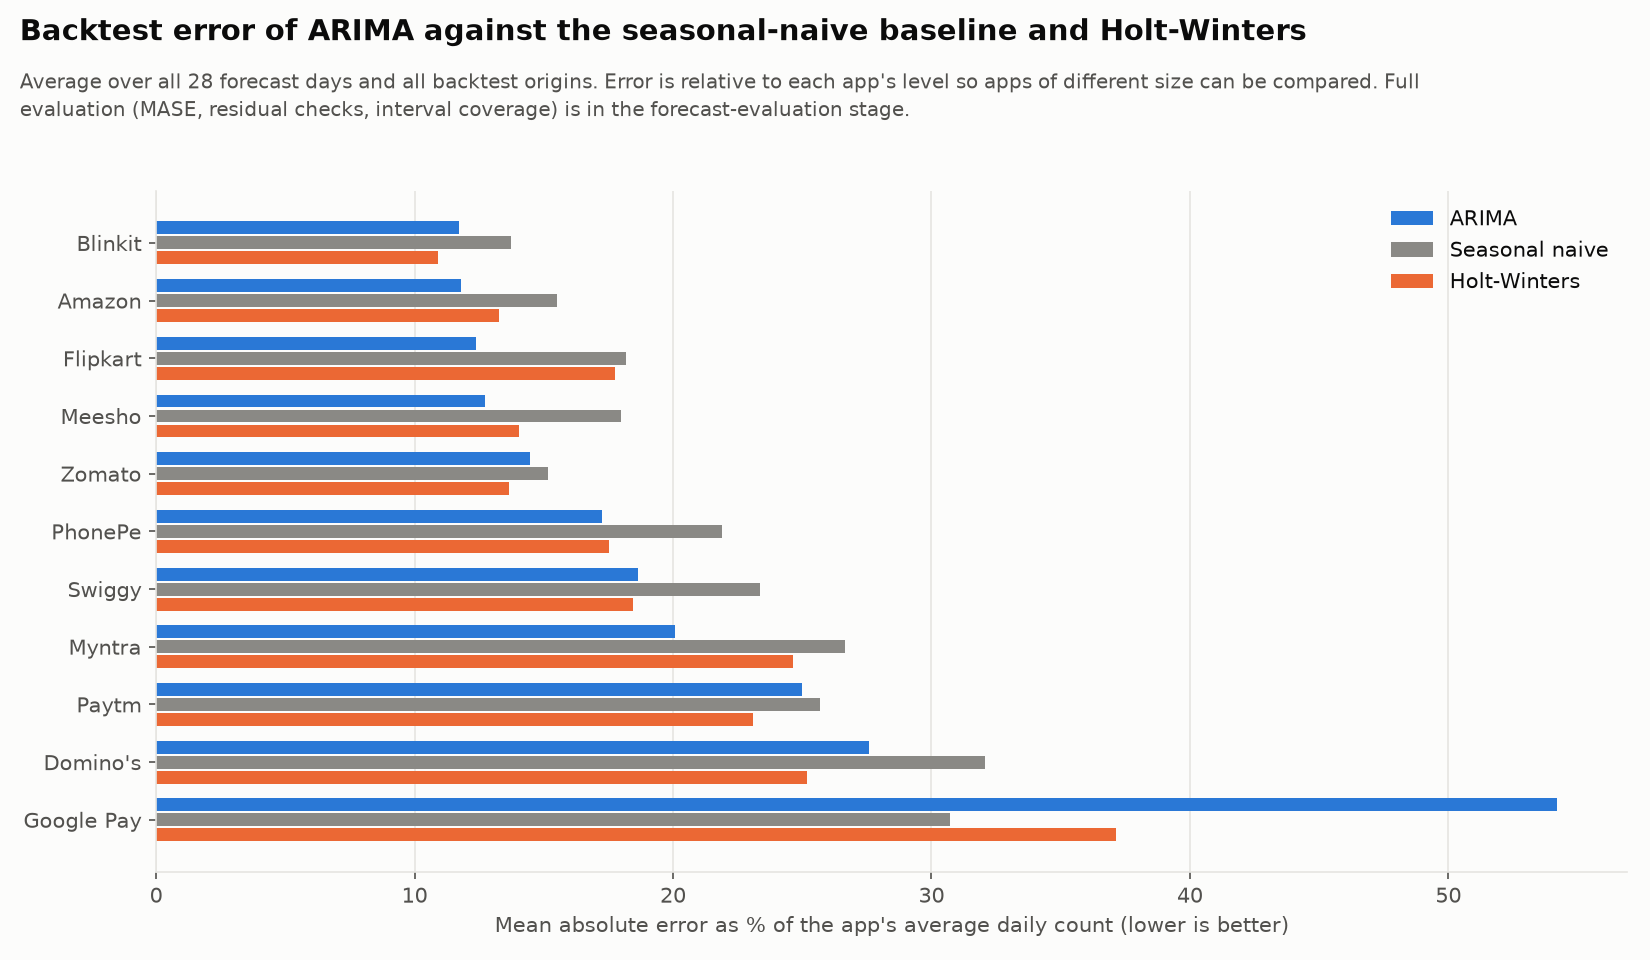

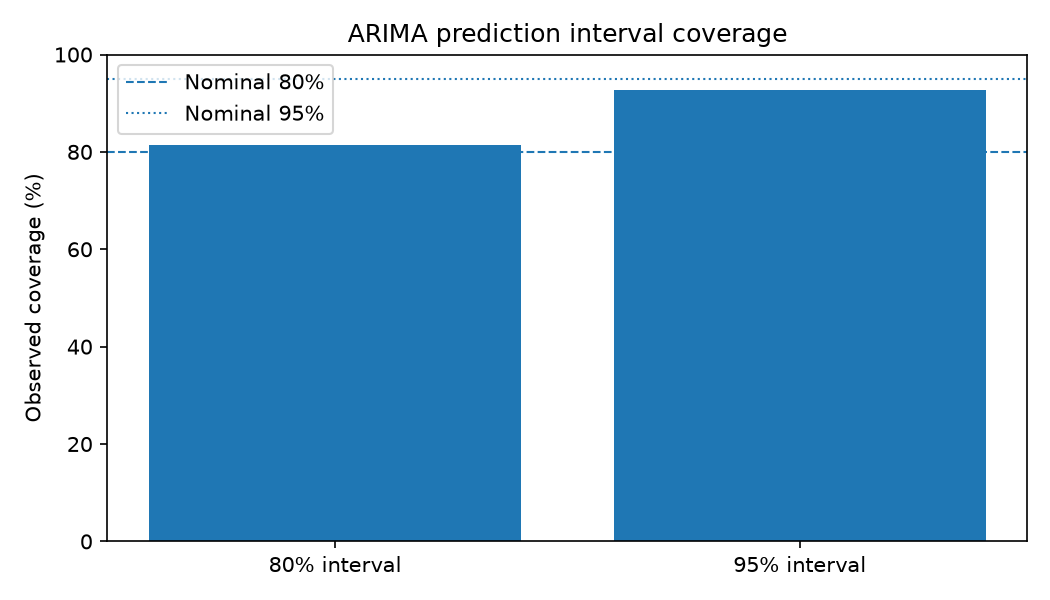

In [22]:
show("timeseries/ts_07_backtest_mae_vs_baseline.png", 800)
show("timeseries/ts_09_interval_coverage.png", 800)

In [23]:
ud = pd.read_csv(TS / "unusual_days_unique.csv", parse_dates=["day"])
print(f"{len(ud)} unique unusual app-days: {(ud.alert_direction.str.startswith('Above')).sum()} above, "
      f"{(ud.alert_direction.str.startswith('Below')).sum()} below the 95% interval")
display(ud.assign(above=ud.alert_direction.str.startswith("Above"))
        .groupby("app_name")["above"].agg(above="sum", total="size").reindex(APP_NAMES).fillna(0).astype(int).T)
ud.sort_values("absolute_error", ascending=False).head(8)[["app_name", "day", "actual", "forecast", "upper_95", "alert_direction"]]

83 unique unusual app-days: 67 above, 16 below the 95% interval


app_name,Swiggy,Zomato,Blinkit,Domino's,Myntra,Flipkart,Amazon,Meesho,Paytm,PhonePe,Google Pay
above,4,0,3,4,9,18,9,9,10,1,0
total,10,1,3,4,13,18,11,11,10,2,0


,app_name,day,actual,forecast,upper_95,alert_direction
33,Swiggy,2026-07-24,469.0,157.03,202.18,Above 95% interval
8,Flipkart,2026-07-04,451.0,263.95,317.94,Above 95% interval
66,Blinkit,2026-08-28,387.0,247.01,328.65,Above 95% interval
49,Domino's,2026-08-15,201.0,61.16,91.77,Above 95% interval
10,Flipkart,2026-07-05,396.0,264.60,319.73,Above 95% interval
5,Blinkit,2026-07-03,329.0,219.10,292.32,Above 95% interval
18,Flipkart,2026-07-11,370.0,267.42,326.14,Above 95% interval
64,Blinkit,2026-08-27,348.0,245.89,325.56,Above 95% interval


### 3.4 Forecast for 21 Sep – 18 Oct 2026

In [24]:
fw = pd.read_csv(TS / "forecast_weekly.csv")
fw[fw["week"] == 1][["app_name", "week_start", "forecast", "lower_80", "upper_80", "last_4_weeks_avg",
                      "change_vs_last_4_weeks_pct"]].reset_index(drop=True)

,app_name,week_start,forecast,lower_80,upper_80,last_4_weeks_avg,change_vs_last_4_weeks_pct
0,Swiggy,2026-09-21,1037.3,888.9,1180.0,973.2,6.6
1,Zomato,2026-09-21,977.1,810.7,1151.0,1054.5,-7.3
2,Blinkit,2026-09-21,1711.1,1488.2,1928.7,1849.2,-7.5
3,Domino's,2026-09-21,412.7,327.3,495.3,386.2,6.9
4,Myntra,2026-09-21,370.9,317.8,423.8,414.2,-10.5
5,Flipkart,2026-09-21,1829.6,1595.5,2055.5,1972.8,-7.3
6,Amazon,2026-09-21,713.6,641.7,785.8,757.8,-5.8
7,Meesho,2026-09-21,737.0,675.6,800.8,711.8,3.5
8,Paytm,2026-09-21,136.0,74.6,204.6,348.2,-61.0
9,PhonePe,2026-09-21,348.3,270.3,430.9,385.2,-9.6


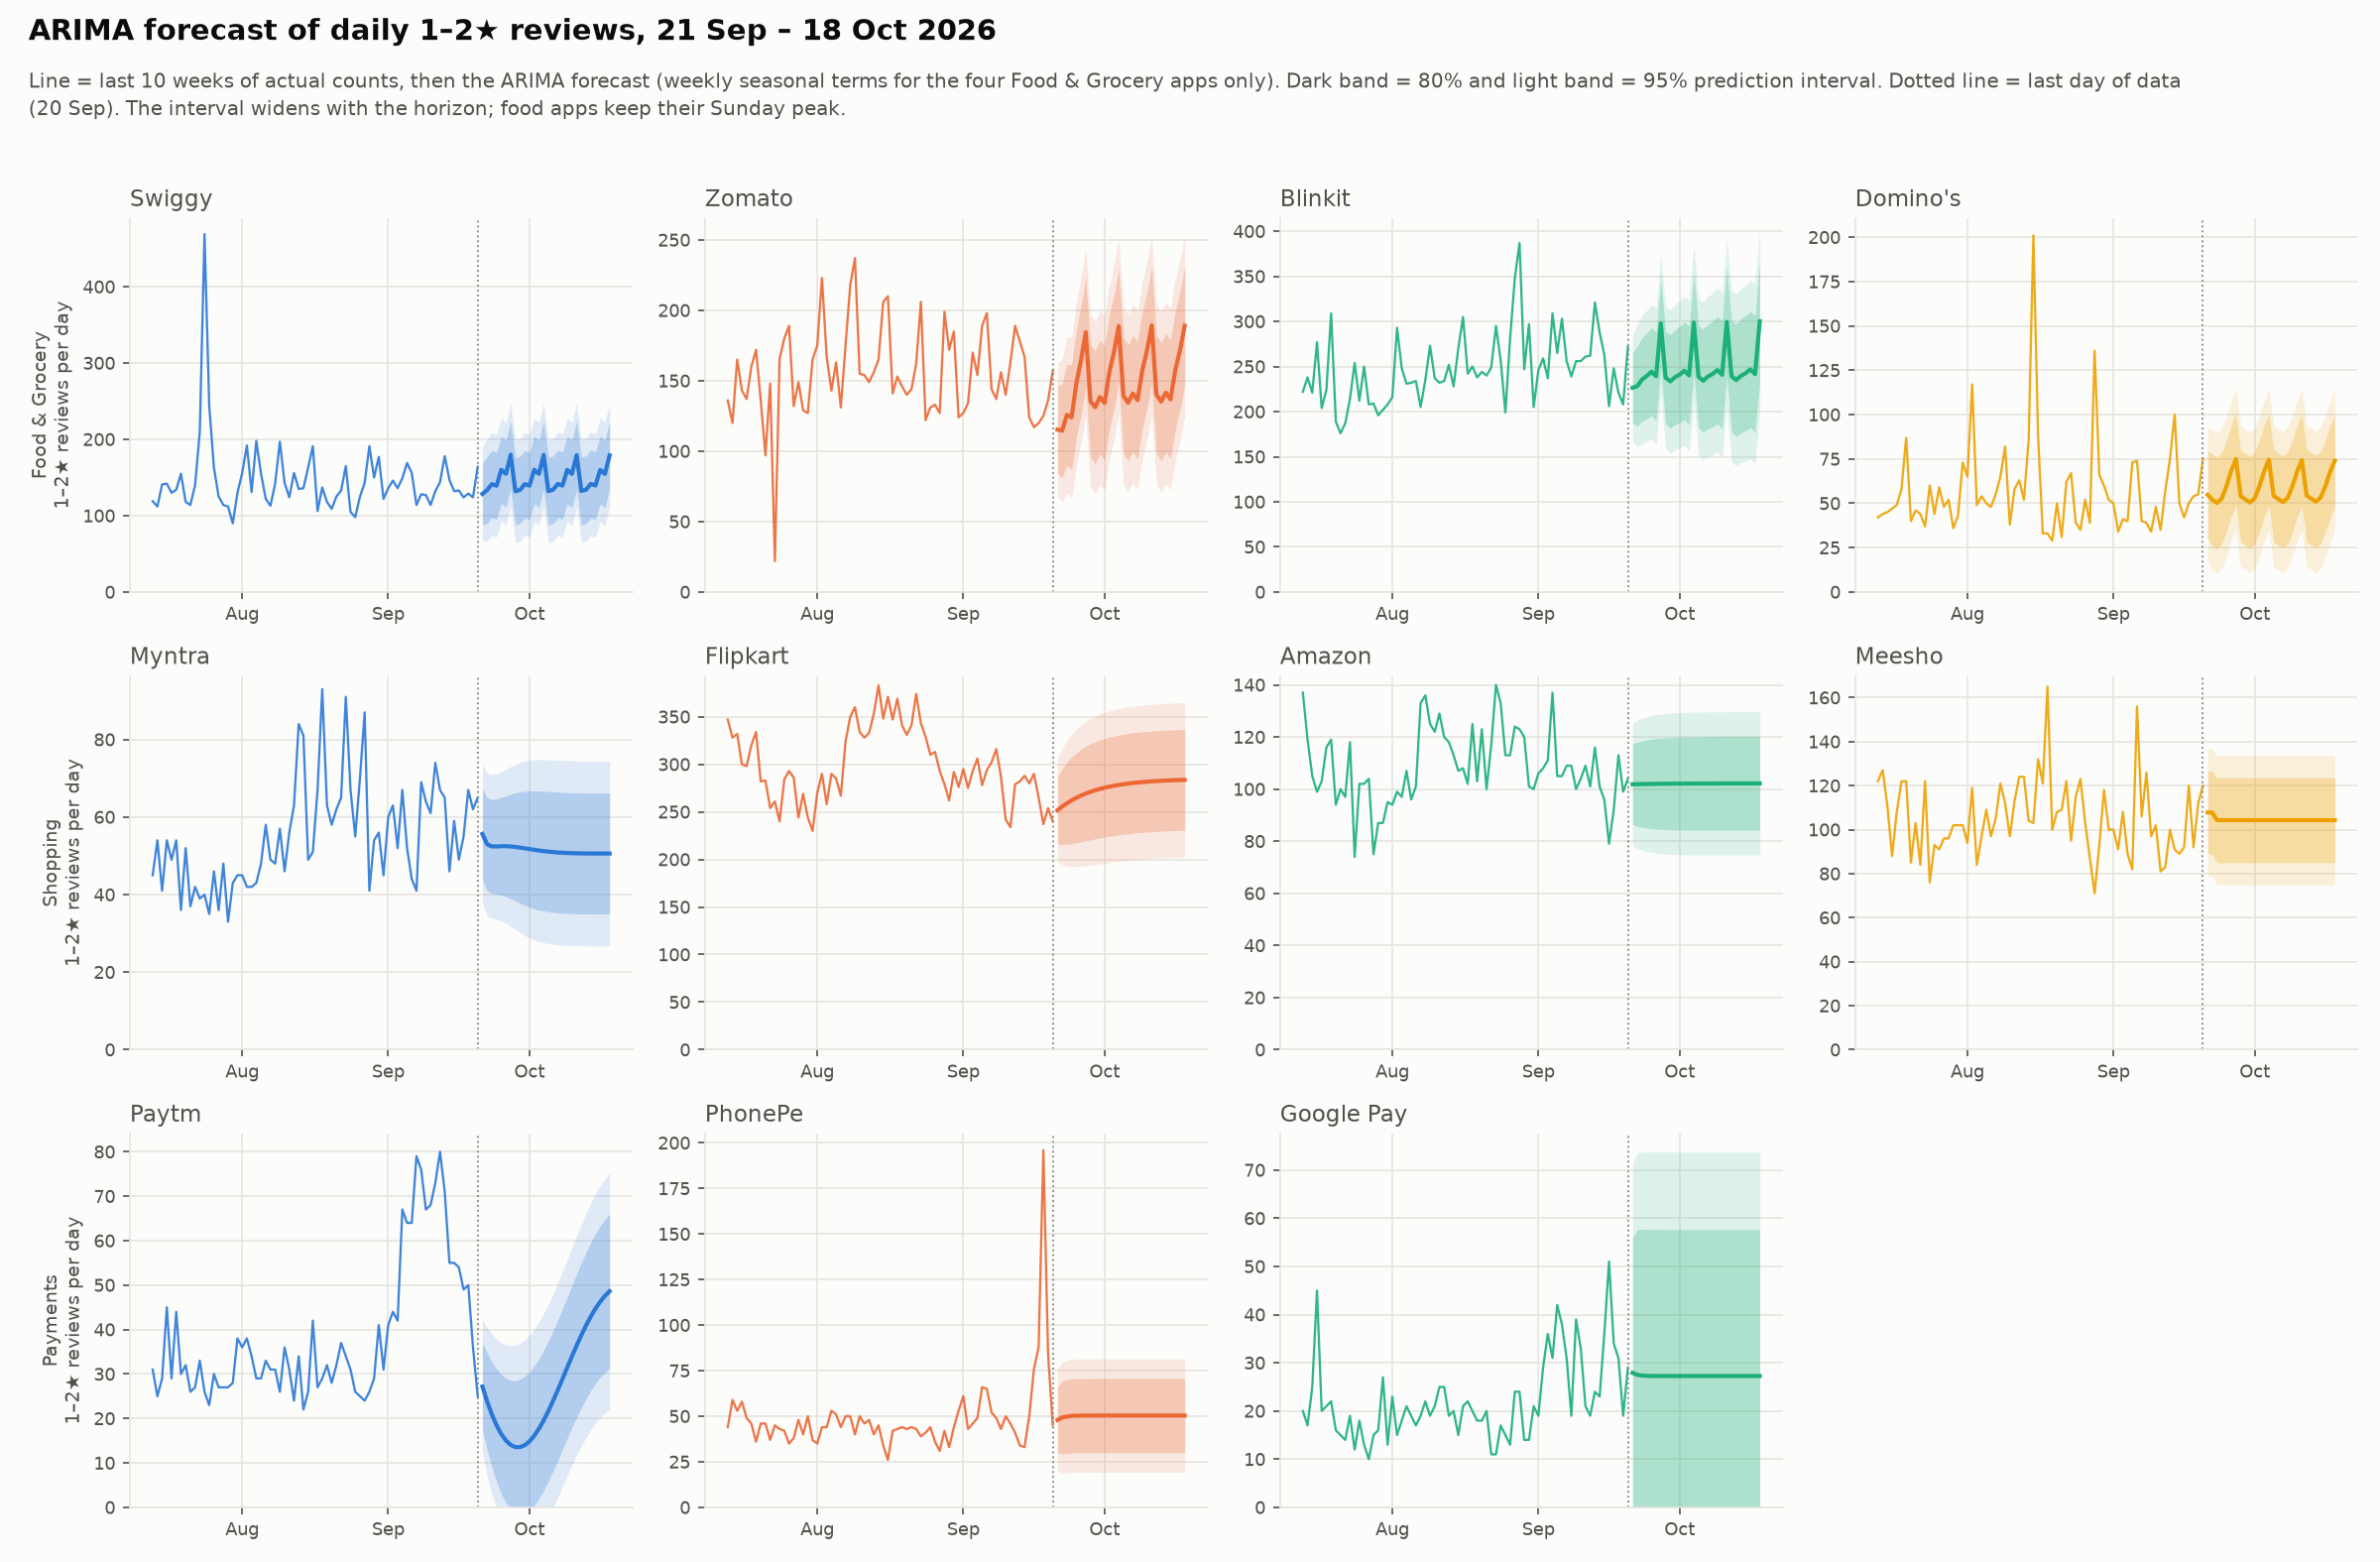

In [25]:
show("timeseries/ts_05_forecast_next_4_weeks.png")

**Time-series findings.** ARIMA beats the seasonal-naive baseline on 10 of 11 apps (Google Pay is the exception); the 80% interval is close to its nominal coverage and the 95% interval under-covers slightly, because of short spikes such as Swiggy on 24 July. Food apps keep a strong Sunday peak; shopping and payment apps are nearly flat. Paytm's forecast is unreliable after its September jump — Section 4 shows that a release explains part of that jump. Details: `TIME_SERIES.md` §1–2.

## 4. Update impact before and after each app version (#138)

**Question:** after a new app version, did 1–2★ reviews, the rating or the issue mix get worse — beyond chance?

For each of the 224 release events (`release_events.csv`; the release day is the day the version reached its 10th review):

* **A. Before vs after (app level):** 7 days before vs 7 days from the release — Welch t-test on 1–2★ reviews per day; z-test on the 1–2★ share; Welch test on the rating.
* **B. New vs older versions, same days (main test):** over the same 7 days, reviews written on the new version vs older versions — two-proportion z-test on the 1–2★ share and on each of the nine issue flags.

Users on the newest version are not a random sample (on Flipkart and Amazon they are always about 6 points more negative), so each release is compared with **its app's usual gap** (leave-one-out median). **Worse** = excess ≥ 5 points with Benjamini–Hochberg q < 0.05 across releases; **confirmed at app level** = view A also shows a significant rise in 1–2★ reviews per day.

The cell below **re-runs the whole analysis** from the tagged reviews (`scripts/21_update_impact.py`, about 10 seconds) without writing any file, and checks it against the saved results.

In [26]:
ui = load_script("21_update_impact.py", "update_impact")
reviews, ts_daily, releases, alerts = ui.load()
res, issues = ui.run(reviews, ts_daily, releases, alerts, day_col="first_seen_10th_review")
saved_res = pd.read_csv(DATA / "update_impact" / "release_impact.csv")
same = (res["verdict"].reset_index(drop=True) == saved_res["verdict"]).all()
print(f"{len(reviews):,} reviews, {len(releases)} releases -> verdicts identical to data/update_impact/release_impact.csv: {same}")
res["verdict"].value_counts().reindex(["Worse (confirmed at app level)", "Worse (new version only)", "No clear change",
                                       "Better", "Not testable"]).to_frame("releases")

1,137,987 reviews, 224 releases -> verdicts identical to data/update_impact/release_impact.csv: True


,releases
verdict,
Worse (confirmed at app level),1
Worse (new version only),3
No clear change,196
Better,5
Not testable,19


In [27]:
usual = res.groupby("app_name")["neg_share_diff_pp"].median().reindex(APP_NAMES)
raw_flag = (res["testable"] & (res["neg_share_diff_pp"] >= ui.MIN_SHARE_DIFF_PP) & (res["q_neg_share_new_vs_older"] < ui.ALPHA)).sum()
print(f"Without the app baseline, a raw 'new minus older' rule would flag {raw_flag} releases; with it, {res['made_worse'].sum()}.")
usual.round(2).to_frame("usual new-vs-older gap (pp)").T

Without the app baseline, a raw 'new minus older' rule would flag 23 releases; with it, 4.


app_name,Swiggy,Zomato,Blinkit,Domino's,Myntra,Flipkart,Amazon,Meesho,Paytm,PhonePe,Google Pay
usual new-vs-older gap (pp),-3.2,-1.83,1.55,-1.28,1.59,6.25,6.7,-1.74,2.71,-0.46,1.4


In [28]:
cols = ["app_name", "app_version", "release_day", "verdict", "neg_share_new", "neg_share_older", "app_usual_gap_pp",
        "excess_gap_pp", "q_excess_gap", "neg_per_day_before", "neg_per_day_after", "q_neg_per_day",
        "alerts_above_in_week_after", "most_elevated_issue", "feed_gap_in_window"]
worse = res[res["made_worse"]][cols].sort_values("excess_gap_pp", ascending=False)
worse.style.format({"neg_share_new": "{:.1%}", "neg_share_older": "{:.1%}", "app_usual_gap_pp": "{:+.1f}",
                    "excess_gap_pp": "{:+.1f}", "q_excess_gap": "{:.4f}", "neg_per_day_before": "{:.0f}",
                    "neg_per_day_after": "{:.0f}", "q_neg_per_day": "{:.3f}"}, na_rep="–")

,app_name,app_version,release_day,verdict,neg_share_new,neg_share_older,app_usual_gap_pp,excess_gap_pp,q_excess_gap,neg_per_day_before,neg_per_day_after,q_neg_per_day,alerts_above_in_week_after,most_elevated_issue,feed_gap_in_window
1,Swiggy,4.107.1,2026-04-19,Worse (new version only),59.9%,42.1%,-3.3,+21.2,0.0000,162,150,0.765,0,Customer Support,True
2,Swiggy,4.107.2,2026-04-23,Worse (new version only),87.9%,82.7%,-3.3,+8.5,0.0152,163,137,0.452,0,,True
186,Paytm,10.84.5,2026-09-03,Worse (confirmed at app level),23.3%,12.8%,+2.4,+8.1,0.0003,34,66,0.027,6,,False
120,Flipkart,9.3,2026-04-16,Worse (new version only),30.1%,16.3%,+6.2,+7.6,0.0152,263,234,0.418,0,Customer Support,True


In [29]:
better = res[res["verdict"] == "Better"][["app_name", "app_version", "release_day", "neg_share_new", "neg_share_older", "excess_gap_pp"]]
display(better.round(3))
sig_issues = issues[issues["significant_increase"]]
print(f"Significant issue-mix increases (q < 0.05, ≥ 2 pp) in any release: {len(sig_issues)}")
sig_issues[["app_name", "app_version", "release_day", "issue", "share_new_pct", "share_older_pct", "diff_pp", "q_value"]].round(3)

,app_name,app_version,release_day,neg_share_new,neg_share_older,excess_gap_pp
4,Swiggy,4.108.0,2026-05-03,0.357,0.504,-11.646
33,Zomato,19.6.3,2026-05-16,0.162,0.233,-5.322
121,Flipkart,9.4,2026-05-03,0.172,0.180,-7.082
182,Paytm,10.83.9,2026-07-27,0.067,0.095,-5.877
201,Google Pay,327.1.1 (arm64-v8a_release_flutter),2026-04-13,0.225,0.347,-13.992


Significant issue-mix increases (q < 0.05, ≥ 2 pp) in any release: 17


,app_name,app_version,release_day,issue,share_new_pct,share_older_pct,diff_pp,q_value
5,Swiggy,4.107.1,2026-04-19,Customer Support,21.008,12.129,8.879,0.003
569,Blinkit,17.99.0,2026-05-29,Delivery Delay,5.153,2.836,2.317,0.046
967,Flipkart,9.3,2026-04-16,Cancellation & Return,5.804,2.588,3.215,0.005
968,Flipkart,9.3,2026-04-16,Customer Support,6.920,2.746,4.174,0.000
986,Flipkart,9.5,2026-05-29,Customer Support,5.243,2.396,2.847,0.004
995,Flipkart,9.6,2026-06-11,Customer Support,4.682,2.360,2.322,0.000
1010,Flipkart,9.8,2026-07-17,Delivery Delay,4.603,2.450,2.153,0.003
1019,Flipkart,9.9,2026-08-04,Delivery Delay,5.369,1.567,3.803,0.016
1058,Flipkart,9.13,2026-09-08,Customer Support,4.925,2.797,2.128,0.000
1103,Amazon,32.10.0.300,2026-05-16,Customer Support,21.543,13.849,7.694,0.031


In [30]:
# Sensitivity: release day = first review on the version instead of the 10th.
sens, _ = ui.run(reviews, ts_daily, releases, alerts, day_col="first_seen")
key = lambda d: set(zip(d.loc[d["made_worse"], "app_name"], d.loc[d["made_worse"], "app_version"]))
print("Flagged with first_seen:", sorted(key(sens)), "| same as main run:", key(sens) == key(res))
del reviews

Flagged with first_seen: [('Flipkart', '9.3'), ('Paytm', '10.84.5'), ('Swiggy', '4.107.1'), ('Swiggy', '4.107.2')] | same as main run: True


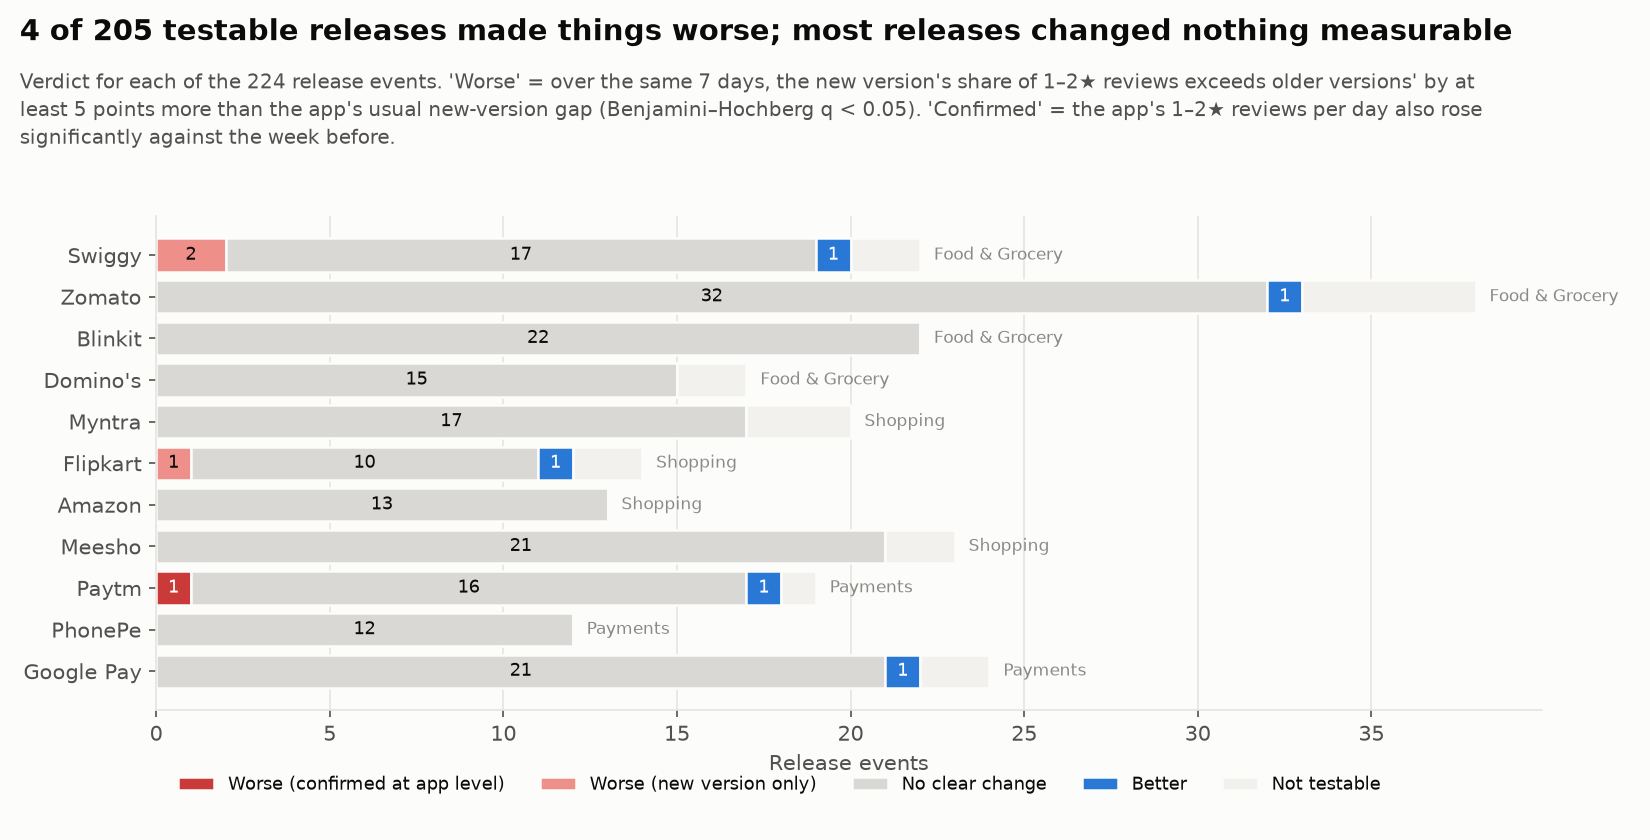

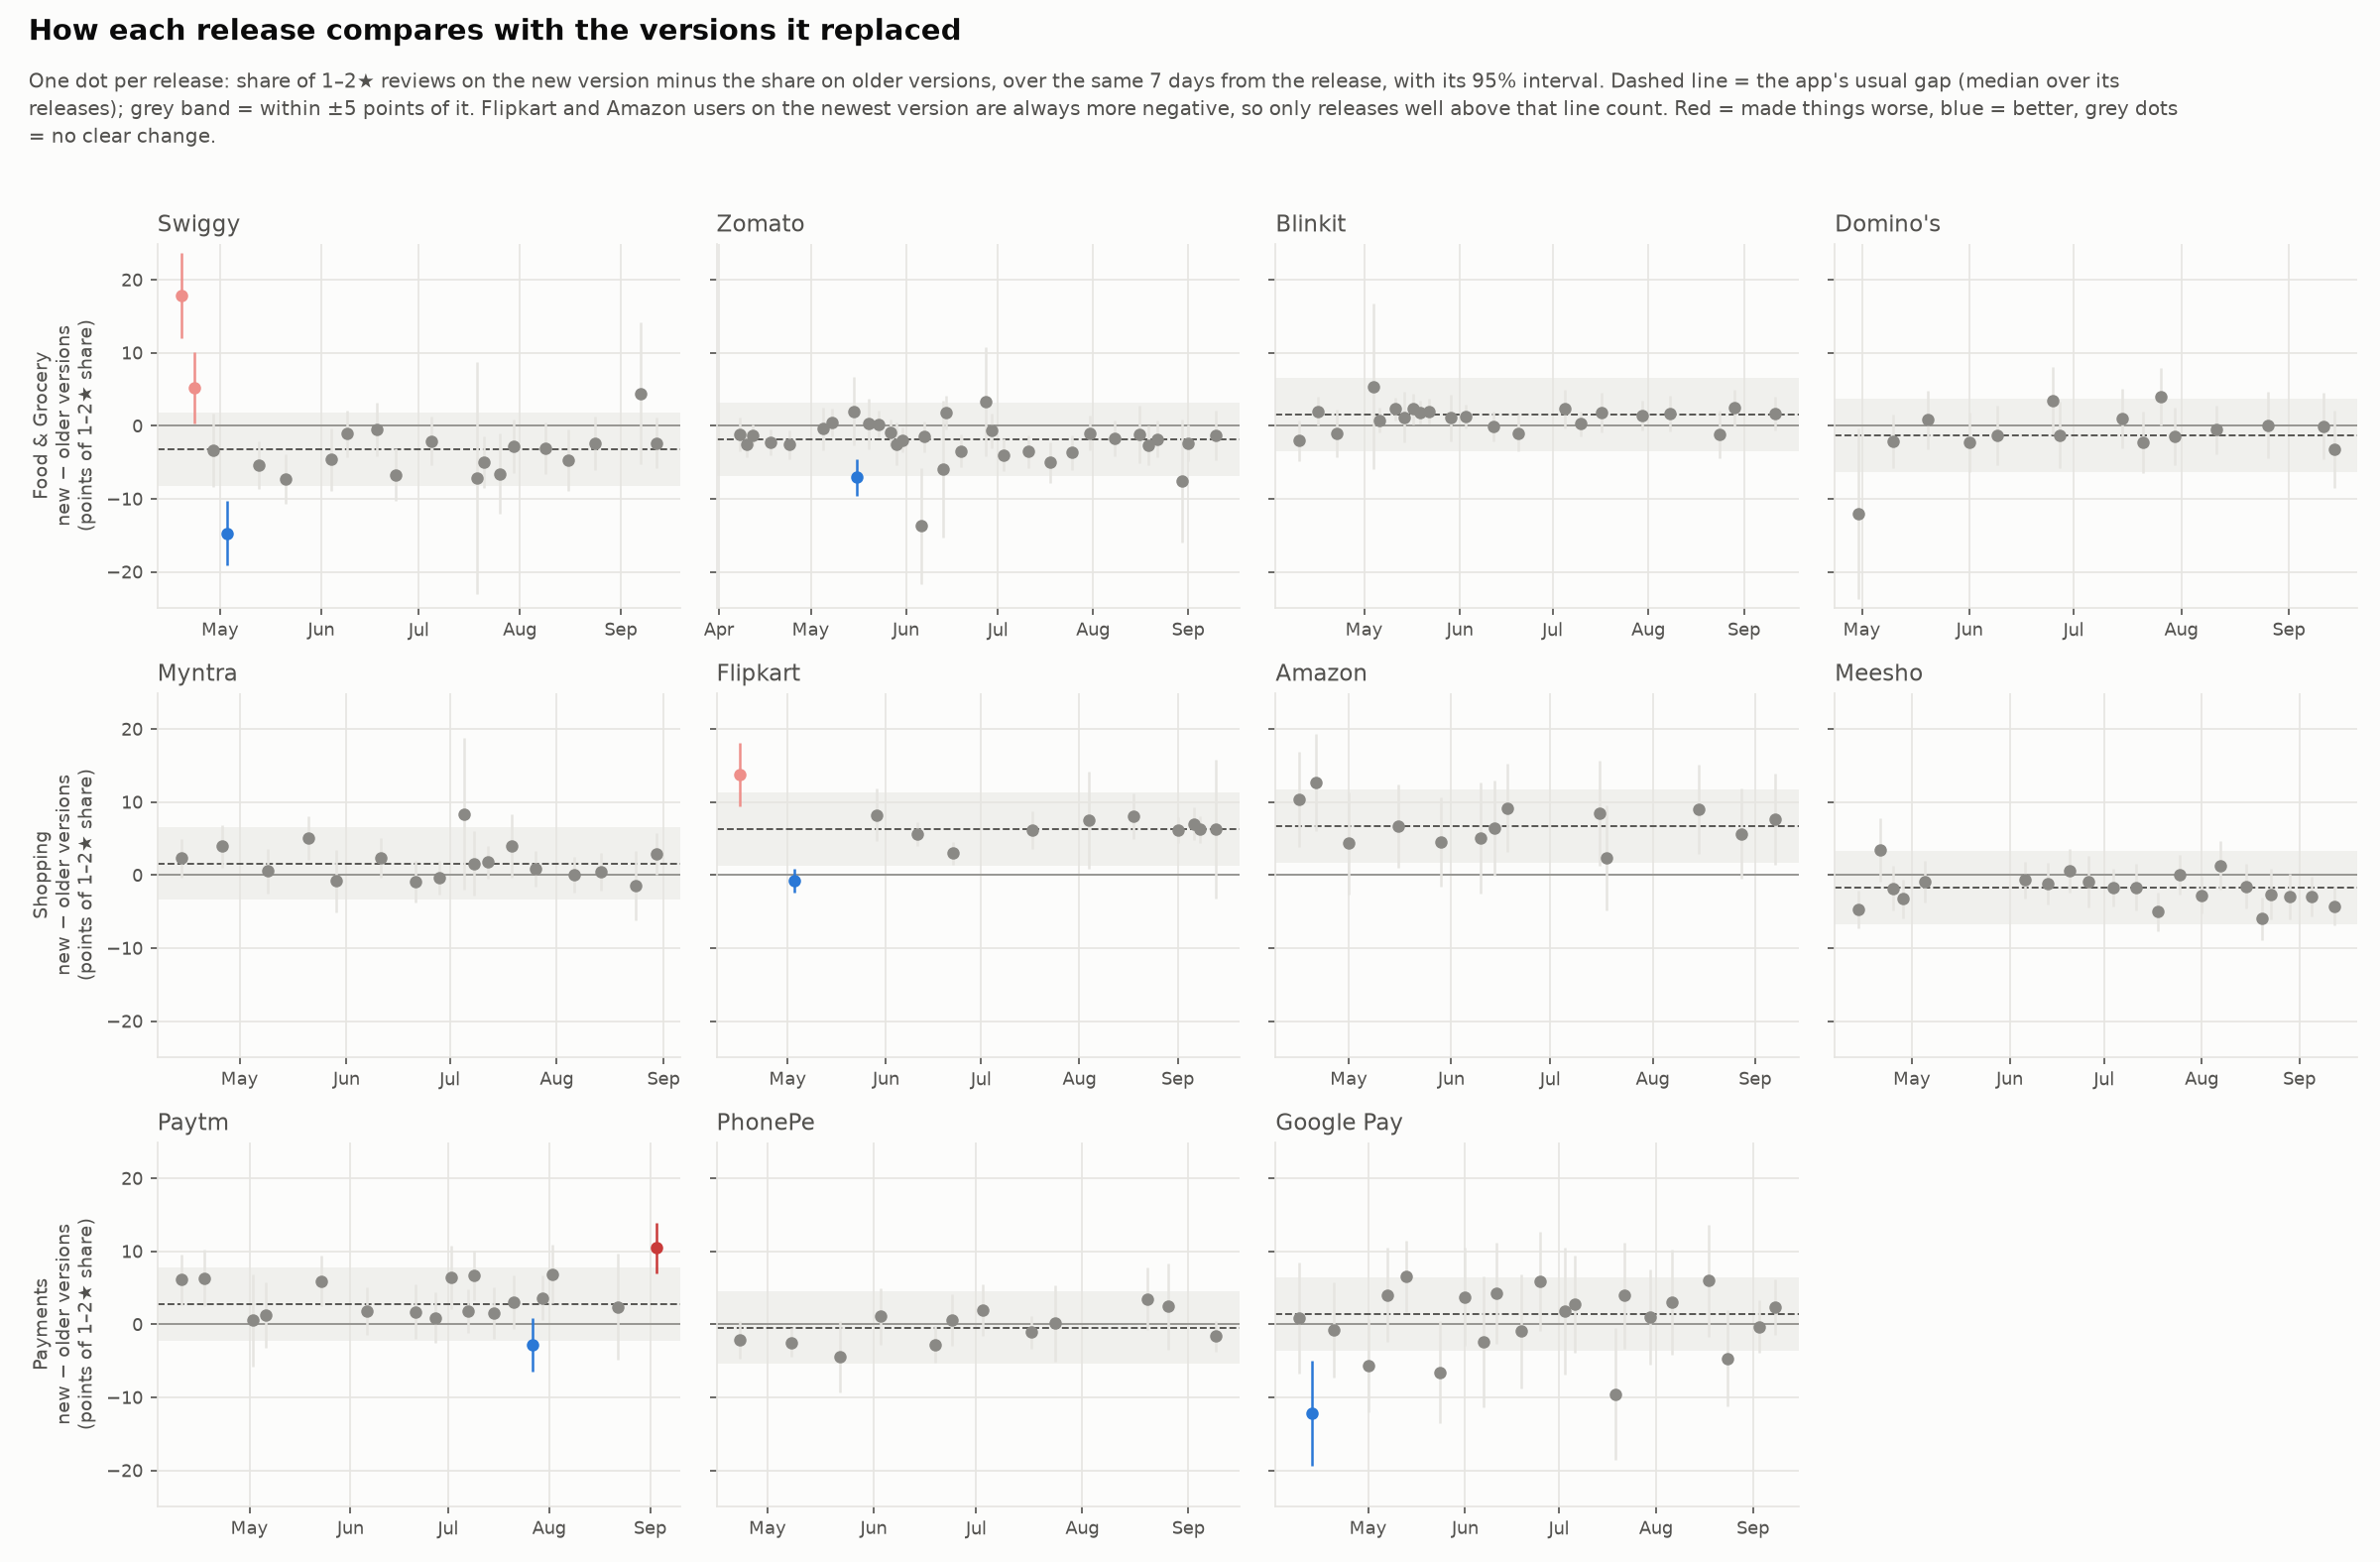

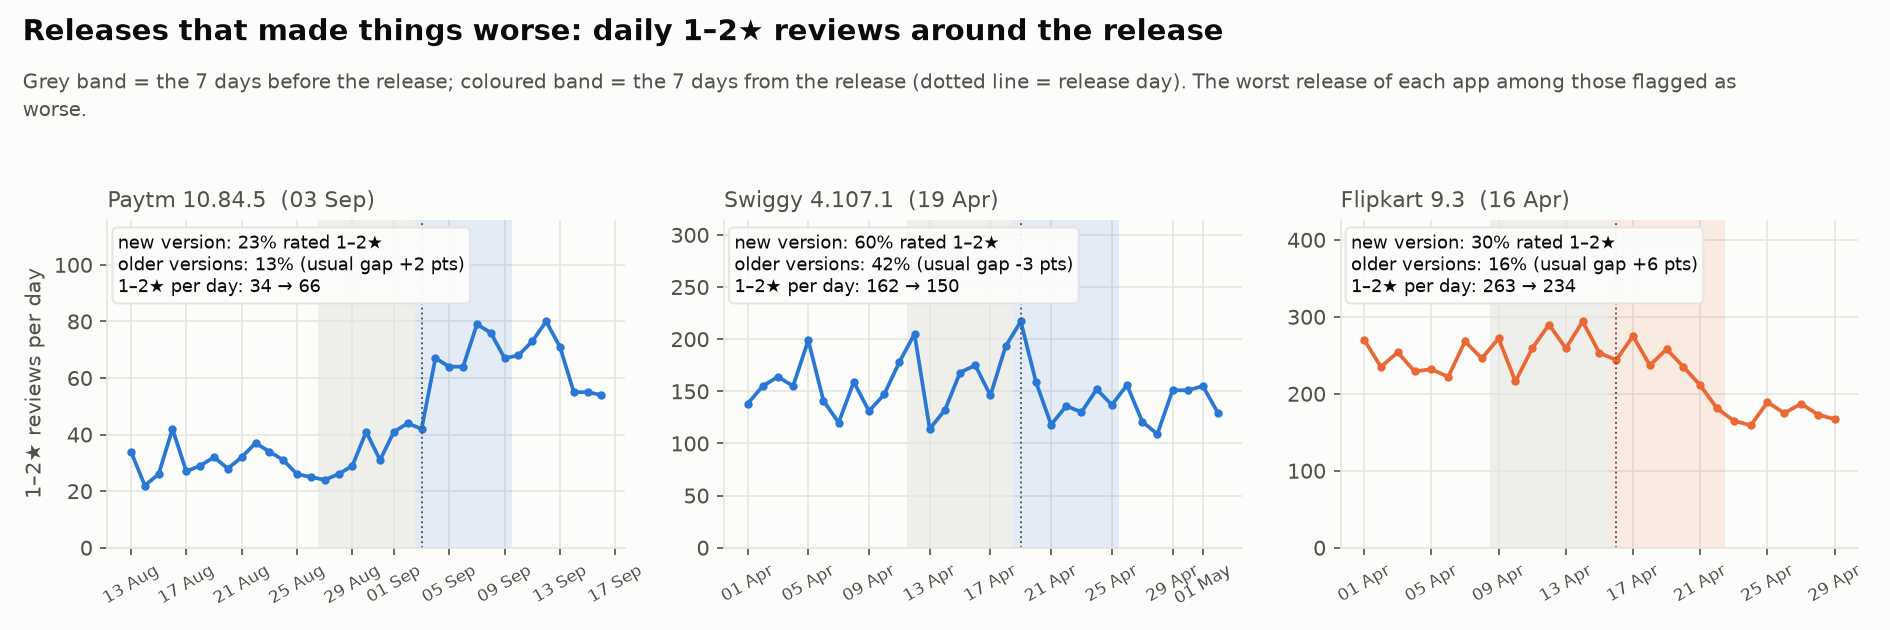

In [31]:
show("update_impact/01_release_verdicts_by_app.png")
show("update_impact/02_release_effects.png")
show("update_impact/03_worst_release_examples.png")

**Update-impact findings.**

* **Most releases change nothing measurable:** 196 of 205 testable releases are within chance of the app's usual gap; the median gap is +0.25 points.
* **4 releases made things worse.** **Paytm 10.84.5 (3 Sep)** is the clearest: 23% vs 13% 1–2★ on the new version, the app's 1–2★ reviews per day nearly doubled (34 → 66, q = 0.027) and the forecast evaluation raised 6 alerts in the following week. **Swiggy 4.107.1 and 4.107.2** and **Flipkart 9.3** were worse on the new version only, with more Customer Support complaints; all three fall in the late-April feed gap, so their size is uncertain.
* **5 releases made things better**, including Swiggy 4.108.0, which replaced the two bad Swiggy versions.
* The app baseline matters: without it 23 releases would be flagged, most of them Flipkart's and Amazon's normal new-version gap. The same 4 releases are flagged with the alternative release day.

Details and limits: `TIME_SERIES.md` §3.

## 5. Combined business insights and recommendations (#141)

All stages are joined into one **priority table per app** (`scripts/22_combined_insights.py`): top complaint topics and their sentiment (text mining), volume and trend (time series), the forecast and its alerts (forecasting), releases that made things worse (update impact) and the Review 1 classifier's flag rate. Each app scores one point per warning sign; **3 or more = High, 2 = Medium, 0–1 = Low**. The cell rebuilds the table in memory and checks it against the saved file.

In [32]:
ci = load_script("22_combined_insights.py", "combined_insights")
table, all_share, med = ci.build_table()
saved_t = pd.read_csv(DATA / "combined" / "priority_table.csv")
print("Priority table identical to data/combined/priority_table.csv:",
      (table.set_index("app_name")["priority"] == saved_t.set_index("app_name")["priority"]).all()
      and (table.set_index("app_name")["priority_score"] == saved_t.set_index("app_name")["priority_score"]).all())
print(f"Thresholds: median 1–2★/day {med:.0f}; all-app 1–2★ share (feed gap excluded) {all_share:.1f}%")
pd.Series(ci.PRIORITY_RULES).to_frame("rule")

Priority table identical to data/combined/priority_table.csv: True
Thresholds: median 1–2★/day 103; all-app 1–2★ share (feed gap excluded) 18.9%


,rule
sig_high_volume,1–2★ reviews per day above the median of the 11 apps
sig_high_share,share of 1–2★ reviews (feed-gap days excluded) above the all-app share
sig_rising,"last 4 weeks at least 10% above the first 4 weeks (STL patterns, Stage 1)"
sig_forecast_up,week-1 forecast at least 5% above the last 4 weeks (Stage 3)
sig_unusual_days,at least 5 days above the 95% forecast interval (Stage 4)
sig_worse_release,"at least one release made things worse (update impact, #138)"


In [33]:
view = table[["app_name", "domain", "priority", "priority_score", "neg_per_day", "neg_share_pct", "trend_change_pct",
              "top_topic", "top_topic_sentiment", "most_severe_topic", "forecast_week1", "forecast_change_pct",
              "forecast_reliable", "unusual_days_above", "releases_worse", "worst_release", "flag_rate_pct",
              "classifier_precision"]]
view.round({"neg_per_day": 0, "neg_share_pct": 1, "top_topic_sentiment": 2, "forecast_week1": 0,
            "forecast_change_pct": 1, "flag_rate_pct": 1, "classifier_precision": 2})

,app_name,domain,priority,priority_score,neg_per_day,neg_share_pct,trend_change_pct,top_topic,top_topic_sentiment,most_severe_topic,forecast_week1,forecast_change_pct,forecast_reliable,unusual_days_above,releases_worse,worst_release,flag_rate_pct,classifier_precision
0,Swiggy,Food & Grocery,High,4,151.0,33.4,-16.2,Order Cancellation & Refund,-0.33,Customer Support & Bot Loop,1037.0,6.6,True,4,2,4.107.1,37.6,0.87
1,Flipkart,Shopping,High,3,282.0,17.7,5.4,Return Rejection & Defective Products,-0.21,Extreme Dissatisfaction & Scam Allegations,1830.0,-7.3,True,18,1,9.3,17.4,0.77
2,Amazon,Shopping,High,3,103.0,53.4,14.0,Customer Service & Escalation Failure,-0.21,Extreme Dissatisfaction & Scam Allegations,714.0,-5.8,True,9,0,NaN,58.1,0.91
3,Paytm,Payments,High,3,38.0,14.6,60.1,Failed Transfers & Debited Amounts,-0.19,Customer Support Unresponsiveness,136.0,-61.0,False,10,1,10.84.5,18.2,0.66
4,Blinkit,Food & Grocery,Medium,2,251.0,18.4,13.1,Order Cancellation & Refund,-0.22,Poor Food Quality & Stale Items,1711.0,-7.5,True,3,0,NaN,25.9,0.66
5,Meesho,Shopping,Medium,2,104.0,17.6,2.2,Return Rejection & Defective Products,-0.26,Poor Shopping Experience & Fabric Quality,737.0,3.5,True,9,0,NaN,24.2,0.69
6,Domino's,Food & Grocery,Medium,2,60.0,22.6,-18.2,Order Cancellation & Refund,-0.28,Poor Food Quality & Stale Items,413.0,6.9,True,4,0,NaN,27.2,0.78
7,Myntra,Shopping,Medium,2,51.0,10.3,21.5,Return Rejection & Defective Products,-0.32,Extreme Dissatisfaction & Scam Allegations,371.0,-10.5,True,9,0,NaN,15.1,0.65
8,Zomato,Food & Grocery,Low,1,164.0,18.8,-11.1,Order Cancellation & Refund,-0.28,Customer Support & Bot Loop,977.0,-7.3,True,0,0,NaN,22.3,0.74
9,Google Pay,Payments,Low,1,27.0,23.2,-19.8,Failed Transfers & Debited Amounts,-0.13,Customer Support Unresponsiveness,192.0,2.9,False,0,0,NaN,29.2,0.68


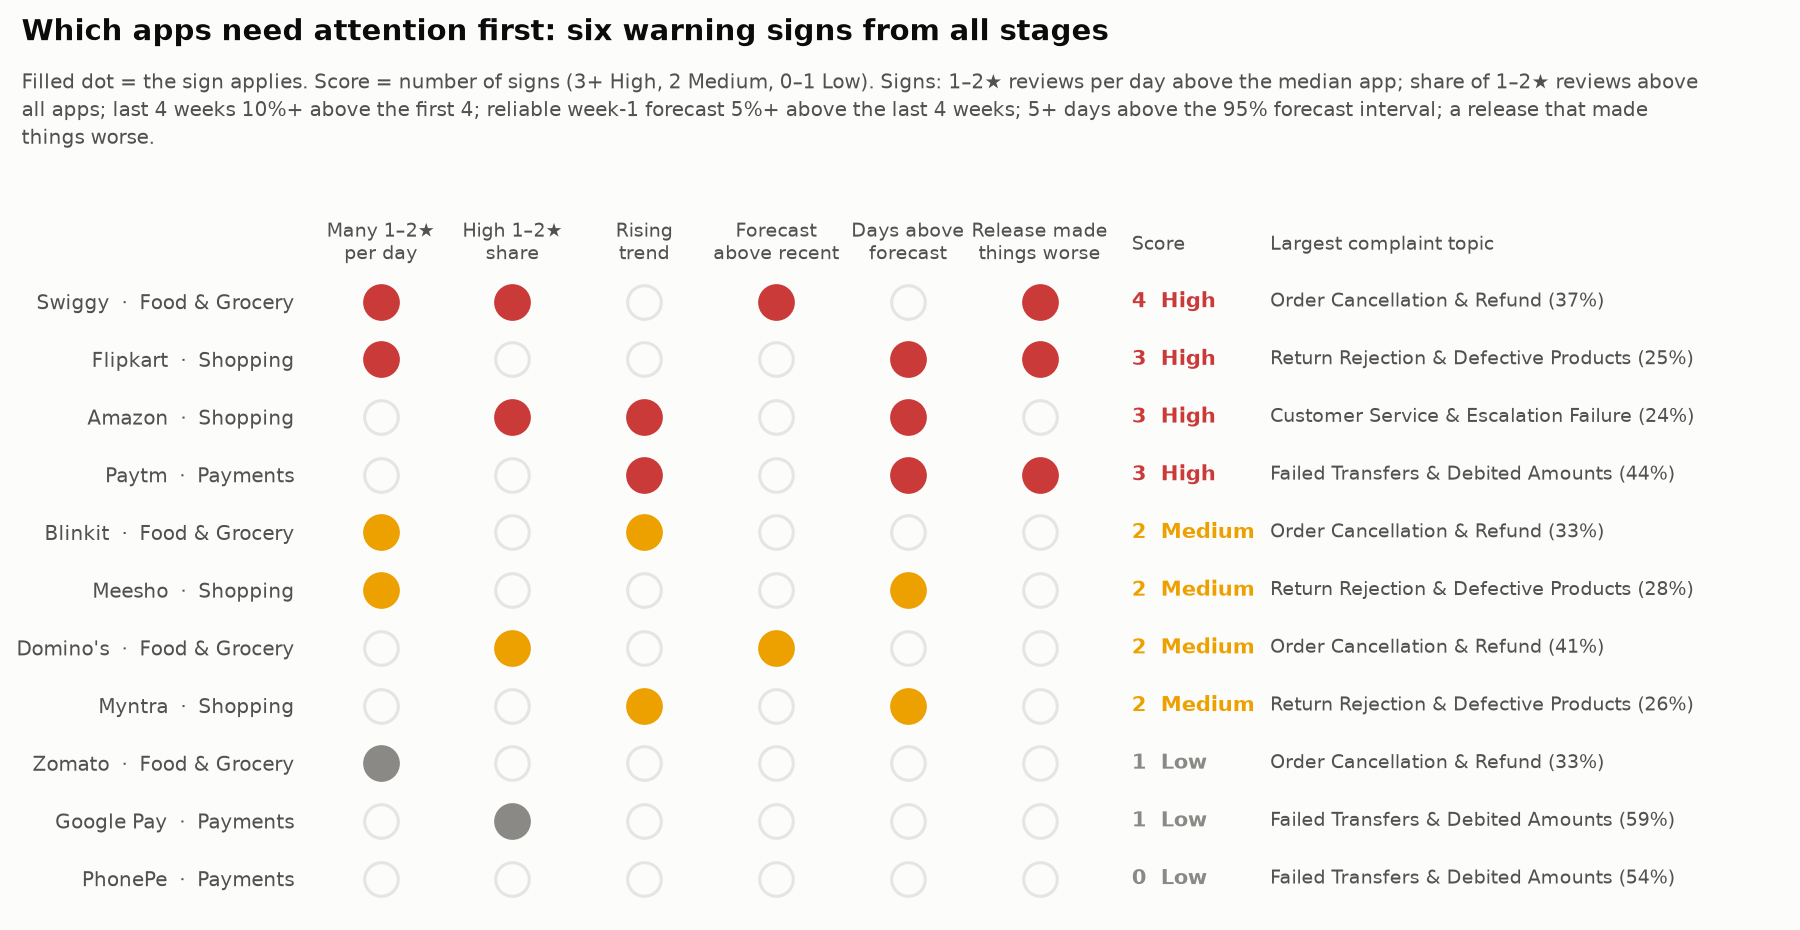

In [34]:
show("combined/ci_01_priority_overview.png")

In [35]:
recs = ci.domain_recommendations(table)
for _, r in table.iterrows():
    recs += ci.app_recommendations(r)
recs = pd.DataFrame(recs)
print(f"{len(recs)} recommendations ({(recs.level == 'Domain').sum()} at domain level, {(recs.level == 'App').sum()} at app level); "
      f"every one carries its evidence: {recs['evidence'].str.contains(r'\d').all()}")
for dom in DOMAINS:
    display(Markdown(f"**{dom}**\n\n" + "\n".join(f"- **{r.type}:** {r.action} — *{r.evidence}*"
                                                  for r in recs[(recs.level == 'Domain') & (recs.domain == dom)].itertuples())))

65 recommendations (9 at domain level, 56 at app level); every one carries its evidence: True


**Food & Grocery**

- **Fix first:** Across Food & Grocery, 'Order Cancellation & Refund' is the most common complaint; fix it in every app. — *35% of the domain's topic-assigned 1–2★ reviews (28,656); sentiment -0.27*
- **Most damaging:** 'Poor Food Quality & Stale Items' produces the angriest reviews in Food & Grocery. — *Mean sentiment -0.44; 59% strongly negative*
- **Focus:** Focus on Swiggy (High priority). Blinkit has the most 1–2★ reviews a day. — *Blinkit: 251 a day, 18.4% of its reviews*

**Shopping**

- **Fix first:** Across Shopping, 'Return Rejection & Defective Products' is the most common complaint; fix it in every app. — *25% of the domain's topic-assigned 1–2★ reviews (18,156); sentiment -0.23*
- **Most damaging:** 'Extreme Dissatisfaction & Scam Allegations' produces the angriest reviews in Shopping. — *Mean sentiment -0.61; 80% strongly negative*
- **Focus:** Focus on Flipkart, Amazon (High priority). Flipkart has the most 1–2★ reviews a day. — *Flipkart: 282 a day, 17.7% of its reviews*

**Payments**

- **Fix first:** Across Payments, 'Failed Transfers & Debited Amounts' is the most common complaint; fix it in every app. — *52% of the domain's topic-assigned 1–2★ reviews (6,909); sentiment -0.15*
- **Most damaging:** 'Customer Support Unresponsiveness' produces the angriest reviews in Payments. — *Mean sentiment -0.23; 40% strongly negative*
- **Focus:** Focus on Paytm (High priority). PhonePe has the most 1–2★ reviews a day. — *PhonePe: 50 a day, 9.8% of its reviews*

In [36]:
for app in table.loc[table["priority"] == "High", "app_name"]:
    a = recs[(recs.level == "App") & (recs.app_name == app)]
    display(Markdown(f"**{app} — High priority**\n\n" + "\n".join(f"- **{r.type}:** {r.action} — *{r.evidence}*"
                                                                for r in a.itertuples())))

**Swiggy — High priority**

- **Fix first:** Fix 'Order Cancellation & Refund' first: it is the largest complaint topic. — *37% of the app's topic-assigned 1–2★ reviews; mean VADER sentiment -0.33*
- **Most damaging:** Treat 'Customer Support & Bot Loop' as the most damaging complaint: smaller but angriest. — *23% of complaints, sentiment -0.43, 59% strongly negative*
- **Release check:** Review release 4.107.1 (2026-04-19) and add a pre-release check for what it broke. — *60% of reviews on the new version rated 1–2★ vs 42% on older versions, +21 points above the app's usual gap (seen on the new version only; released during the late-April feed gap, so the shares are inflated, but both groups cover the same days); most elevated issue: Customer Support*
- **Plan capacity:** Staff the support queue for the forecast volume next week. — *1,037 1–2★ reviews expected 21–27 Sep (80% interval 889–1,180), +7% vs the last 4 weeks*
- **Triage:** Route reviews flagged by the problem-review classifier to support first. — *Flags 38% of reviews; 87% of flags are real 1–2★ reviews and it finds 93% of them (test set)*

**Flipkart — High priority**

- **Fix first:** Fix 'Return Rejection & Defective Products' first: it is the largest complaint topic. — *25% of the app's topic-assigned 1–2★ reviews; mean VADER sentiment -0.21*
- **Most damaging:** Treat 'Extreme Dissatisfaction & Scam Allegations' as the most damaging complaint: smaller but angriest. — *10% of complaints, sentiment -0.61, 81% strongly negative*
- **Release check:** Review release 9.3 (2026-04-16) and add a pre-release check for what it broke. — *30% of reviews on the new version rated 1–2★ vs 16% on older versions, +8 points above the app's usual gap (seen on the new version only; released during the late-April feed gap, so the shares are inflated, but both groups cover the same days); most elevated issue: Customer Support*
- **Plan capacity:** Staff the support queue for the forecast volume next week. — *1,830 1–2★ reviews expected 21–27 Sep (80% interval 1,596–2,056), -7% vs the last 4 weeks*
- **Monitor:** Set a daily alert when 1–2★ reviews leave the forecast interval, and investigate each alert. — *18 days above the 95% interval in the backtest; largest 2026-07-04 (451 vs 264 expected)*
- **Triage:** Route reviews flagged by the problem-review classifier to support first. — *Flags 17% of reviews; 77% of flags are real 1–2★ reviews and it finds 74% of them (test set)*

**Amazon — High priority**

- **Fix first:** Fix 'Customer Service & Escalation Failure' first: it is the largest complaint topic. — *24% of the app's topic-assigned 1–2★ reviews; mean VADER sentiment -0.21*
- **Most damaging:** Treat 'Extreme Dissatisfaction & Scam Allegations' as the most damaging complaint: smaller but angriest. — *10% of complaints, sentiment -0.59, 77% strongly negative*
- **Plan capacity:** Staff the support queue for the forecast volume next week. — *714 1–2★ reviews expected 21–27 Sep (80% interval 642–786), -6% vs the last 4 weeks*
- **Monitor:** Set a daily alert when 1–2★ reviews leave the forecast interval, and investigate each alert. — *9 days above the 95% interval in the backtest; largest 2026-07-04 (142 vs 98 expected)*
- **Trend:** Find what changed: complaints are rising. — *Last 4 weeks +14% vs the first 4 weeks*
- **Triage:** Route reviews flagged by the problem-review classifier to support first. — *Flags 58% of reviews; 91% of flags are real 1–2★ reviews and it finds 96% of them (test set)*

**Paytm — High priority**

- **Fix first:** Fix 'Failed Transfers & Debited Amounts' first: it is the largest complaint topic. — *44% of the app's topic-assigned 1–2★ reviews; mean VADER sentiment -0.19*
- **Most damaging:** Treat 'Customer Support Unresponsiveness' as the most damaging complaint: smaller but angriest. — *20% of complaints, sentiment -0.22, 40% strongly negative*
- **Release check:** Review release 10.84.5 (2026-09-03) and add a pre-release check for what it broke. — *23% of reviews on the new version rated 1–2★ vs 13% on older versions, +8 points above the app's usual gap (confirmed: 1–2★ reviews per day also rose)*
- **Plan capacity:** Do not plan on the ARIMA forecast alone; use last week's level and watch daily counts. — *Forecast flagged as unreliable: week-1 forecast is -61% from the last 4 weeks*
- **Monitor:** Set a daily alert when 1–2★ reviews leave the forecast interval, and investigate each alert. — *10 days above the 95% interval in the backtest; largest 2026-09-12 (80 vs 36 expected)*
- **Trend:** Find what changed: complaints are rising. — *Last 4 weeks +60% vs the first 4 weeks*
- **Triage:** Route reviews flagged by the problem-review classifier to support first. — *Flags 18% of reviews; 66% of flags are real 1–2★ reviews and it finds 84% of them (test set)*

**Combined findings.**

* **High priority: Swiggy (4 signs), Flipkart, Amazon and Paytm (3 each).** Swiggy has a high 1–2★ share, a forecast above its recent level and a bad release; Flipkart has the most 1–2★ reviews of the shopping apps and 18 days above the forecast interval; Amazon has the highest 1–2★ share (53%) and a rising trend; Paytm's complaints rose 60% and its 10.84.5 release is the only one confirmed to have made things worse.
* **Medium:** Blinkit, Meesho, Domino's, Myntra. **Low:** Zomato, Google Pay, PhonePe (PhonePe shows no warning sign).
* **Per domain:** fix the refund/cancellation flow in food apps, returns and defective products in shopping, and failed transfers with money debited in payments; respond fastest to food-quality, scam-allegation and unanswered-support complaints, which are the angriest.

Full table and all recommendations: `COMBINED_INSIGHTS.md`, `data/combined/`.

## 6. Interactive dashboard

The Streamlit dashboard shows every result with shared filters (domain, app, date range, exclude the feed gap):

| Page | Contents |
|---|---|
| Overview (#133) | Headline numbers, trends per domain, 1–2★ share, top issues |
| Text mining (#139) | Topic explorer with example reviews, topics by app, topic trends, distinctive terms |
| **Forecasting (#140)** | ARIMA forecast per app with 80% and 95% prediction intervals, seasonal-naive / Holt-Winters comparison, unusual days, release markers (red = made things worse), backtest MASE |
| **Update impact (#140)** | Verdict per release, new-vs-older gap against the app's usual gap, before/after detail and issue mix for any release |
| **Recommendations (#140)** | Priority table and recommendations, filterable by domain and app, with downloads |
| Check a review (#146) | Classify a new review with the saved models |

**Run locally** (from the repository root):

```bash
pip install -r requirements.txt
streamlit run dashboard/app.py
```

**Public link:** deployed on Streamlit Community Cloud from the `master` branch, main file `dashboard/app.py` (steps in `dashboard/README.md`). Live link: **https://team10-app-reviews.streamlit.app/** (if it shows a sleep screen, press *Yes, get this app back up!* and wait about a minute).

**Overview page**

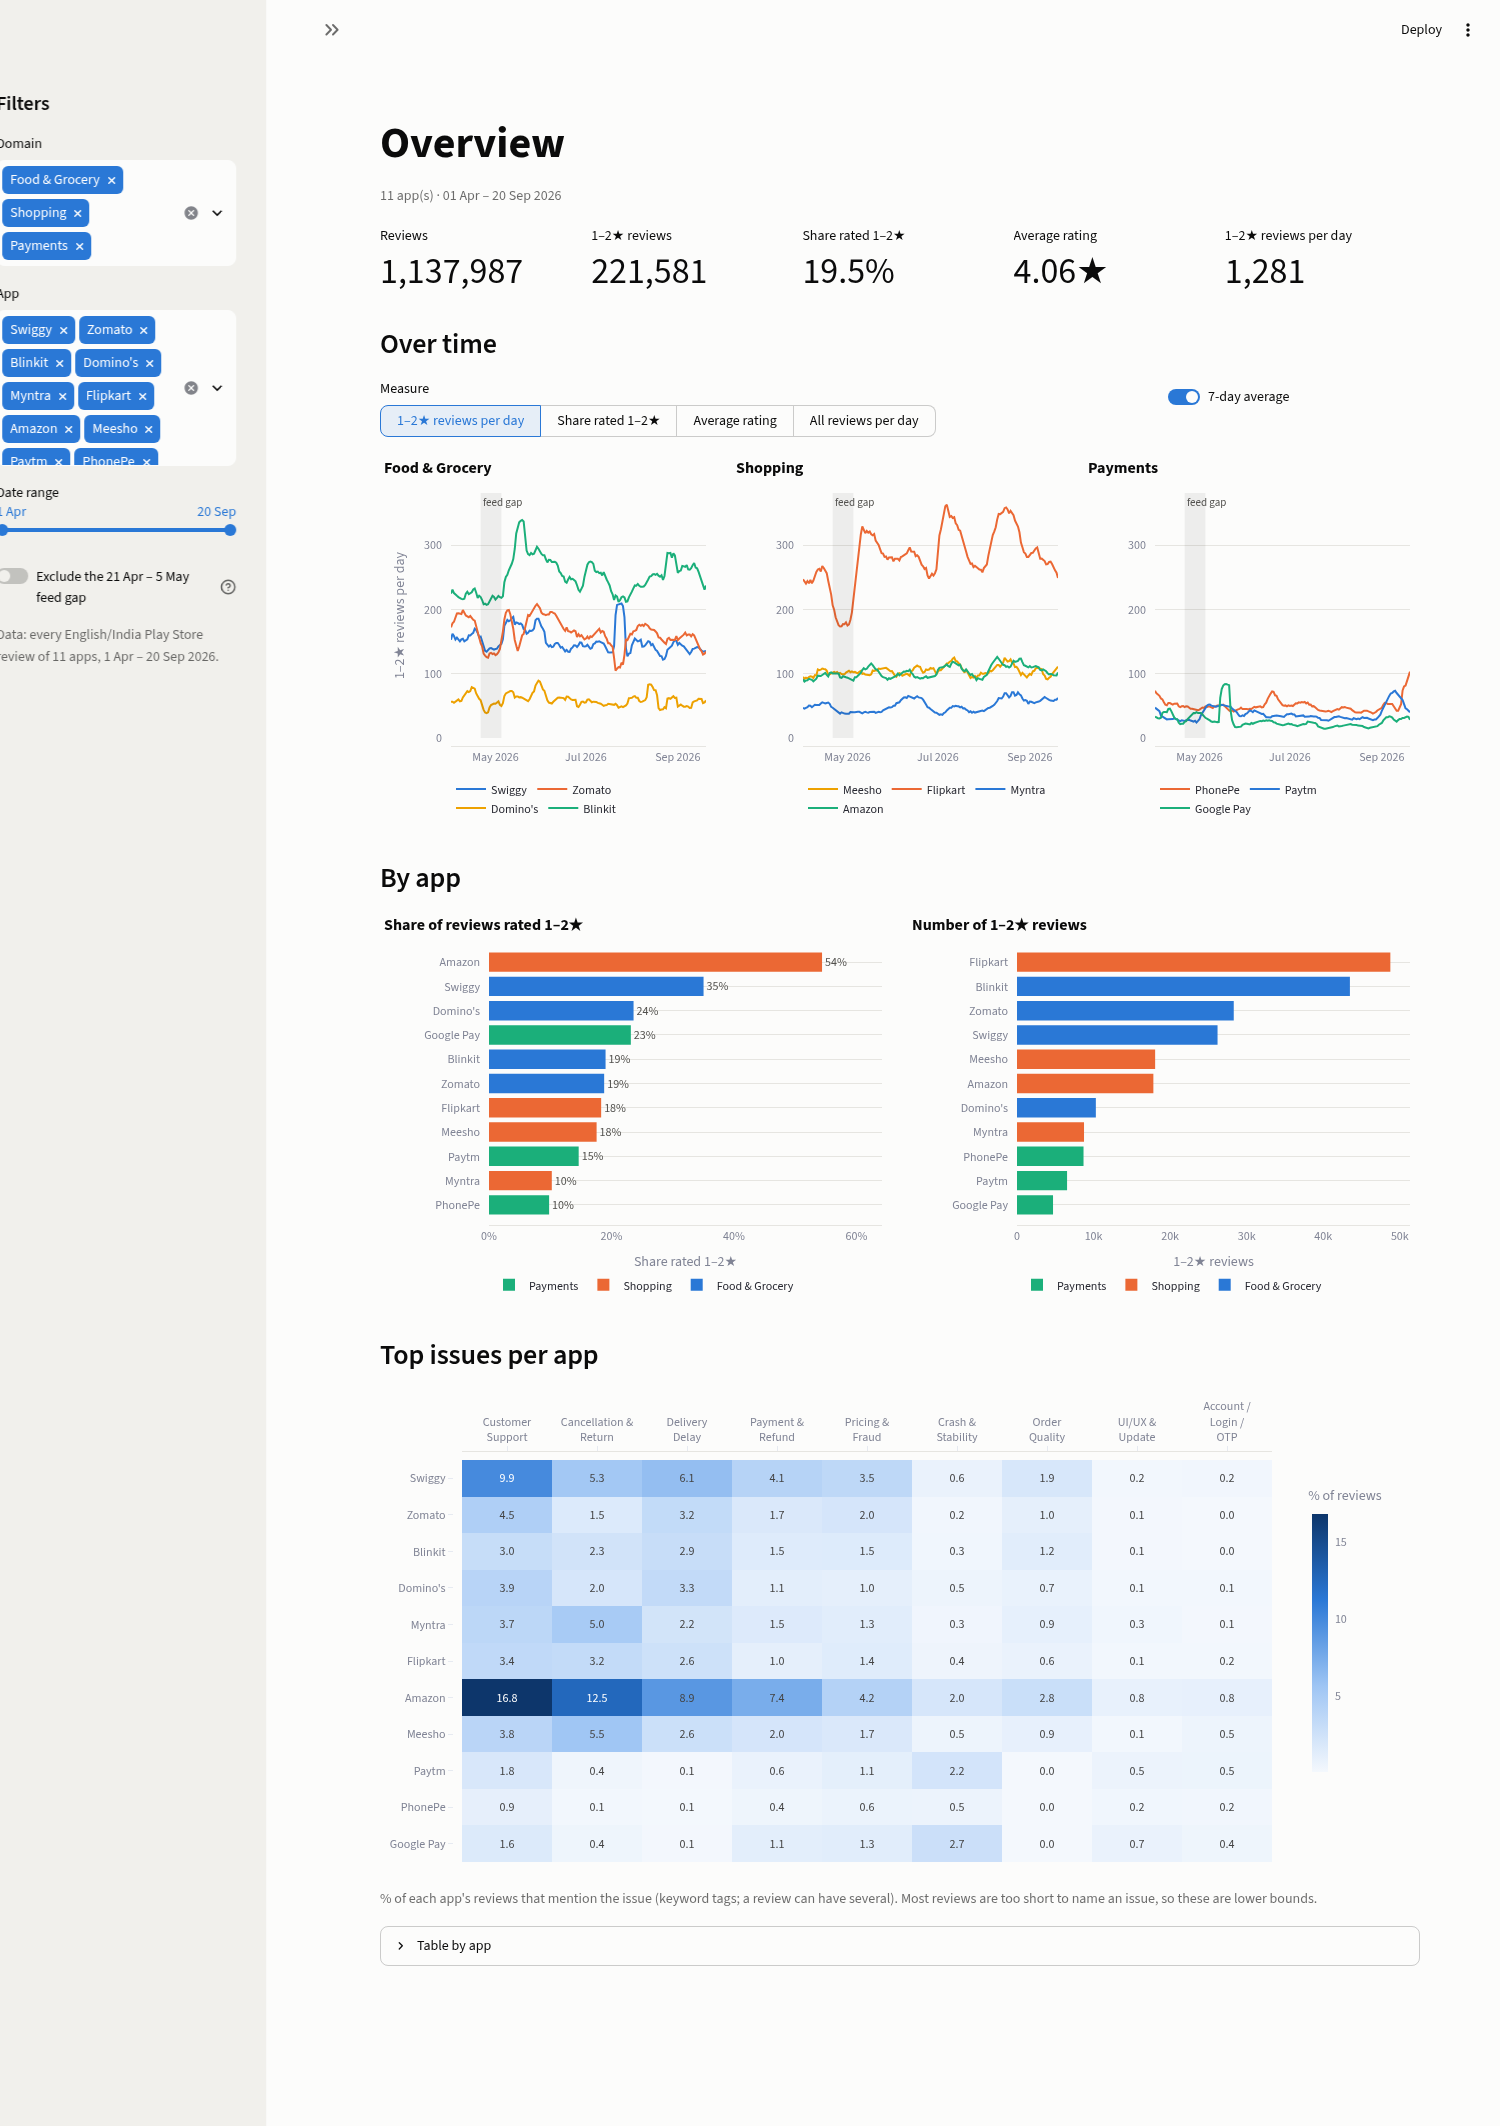

**Text Mining page**

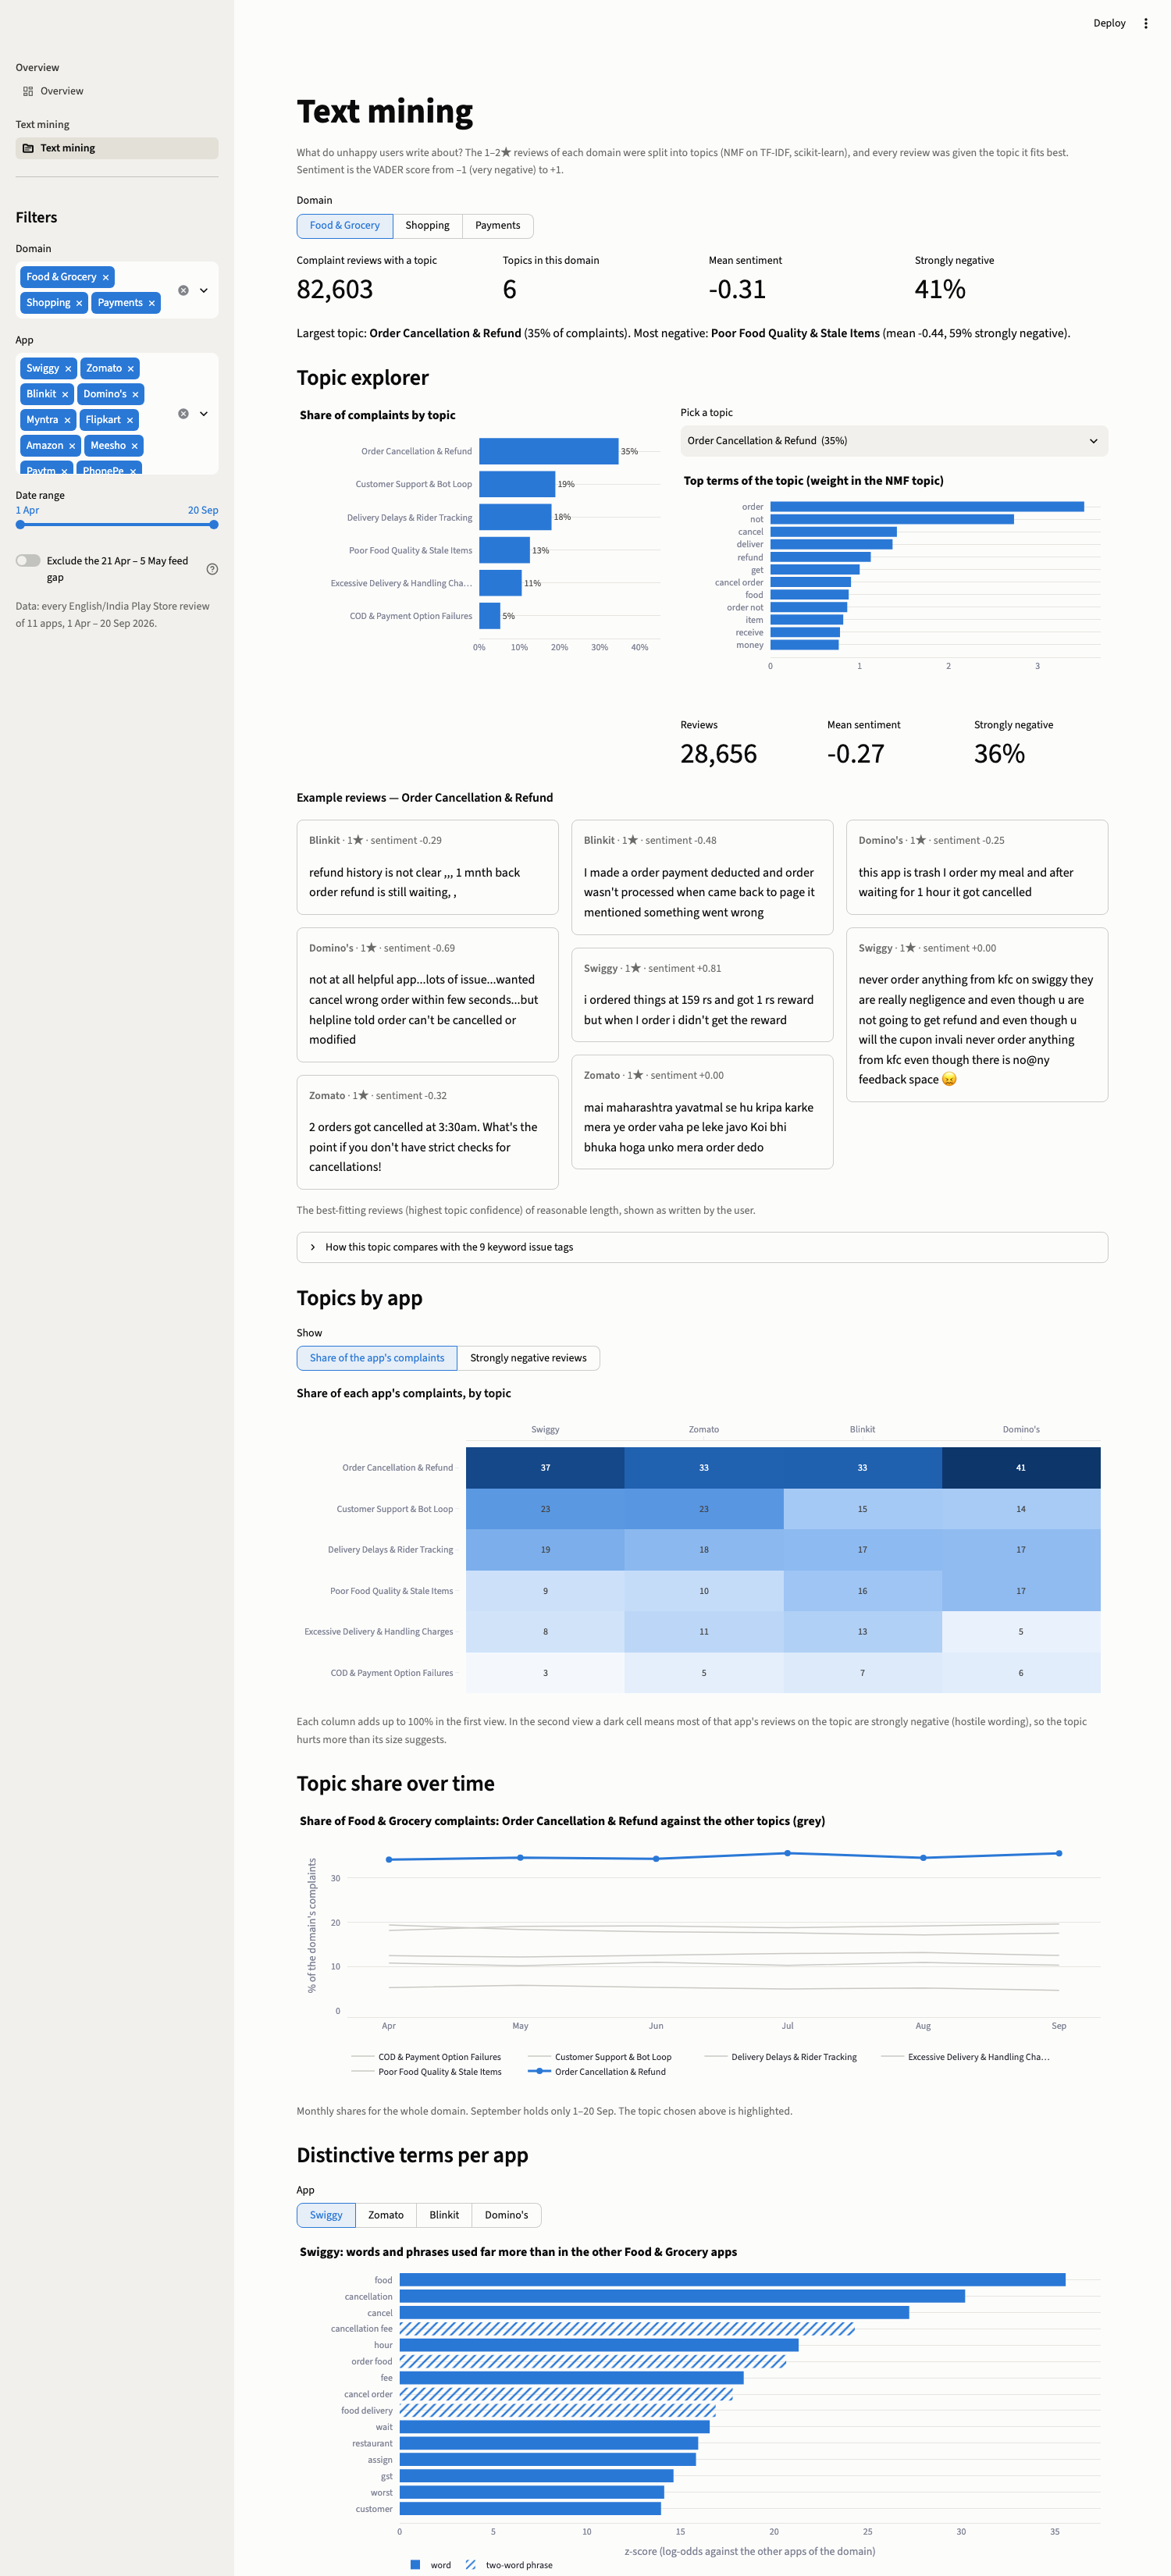

**Forecasting page**

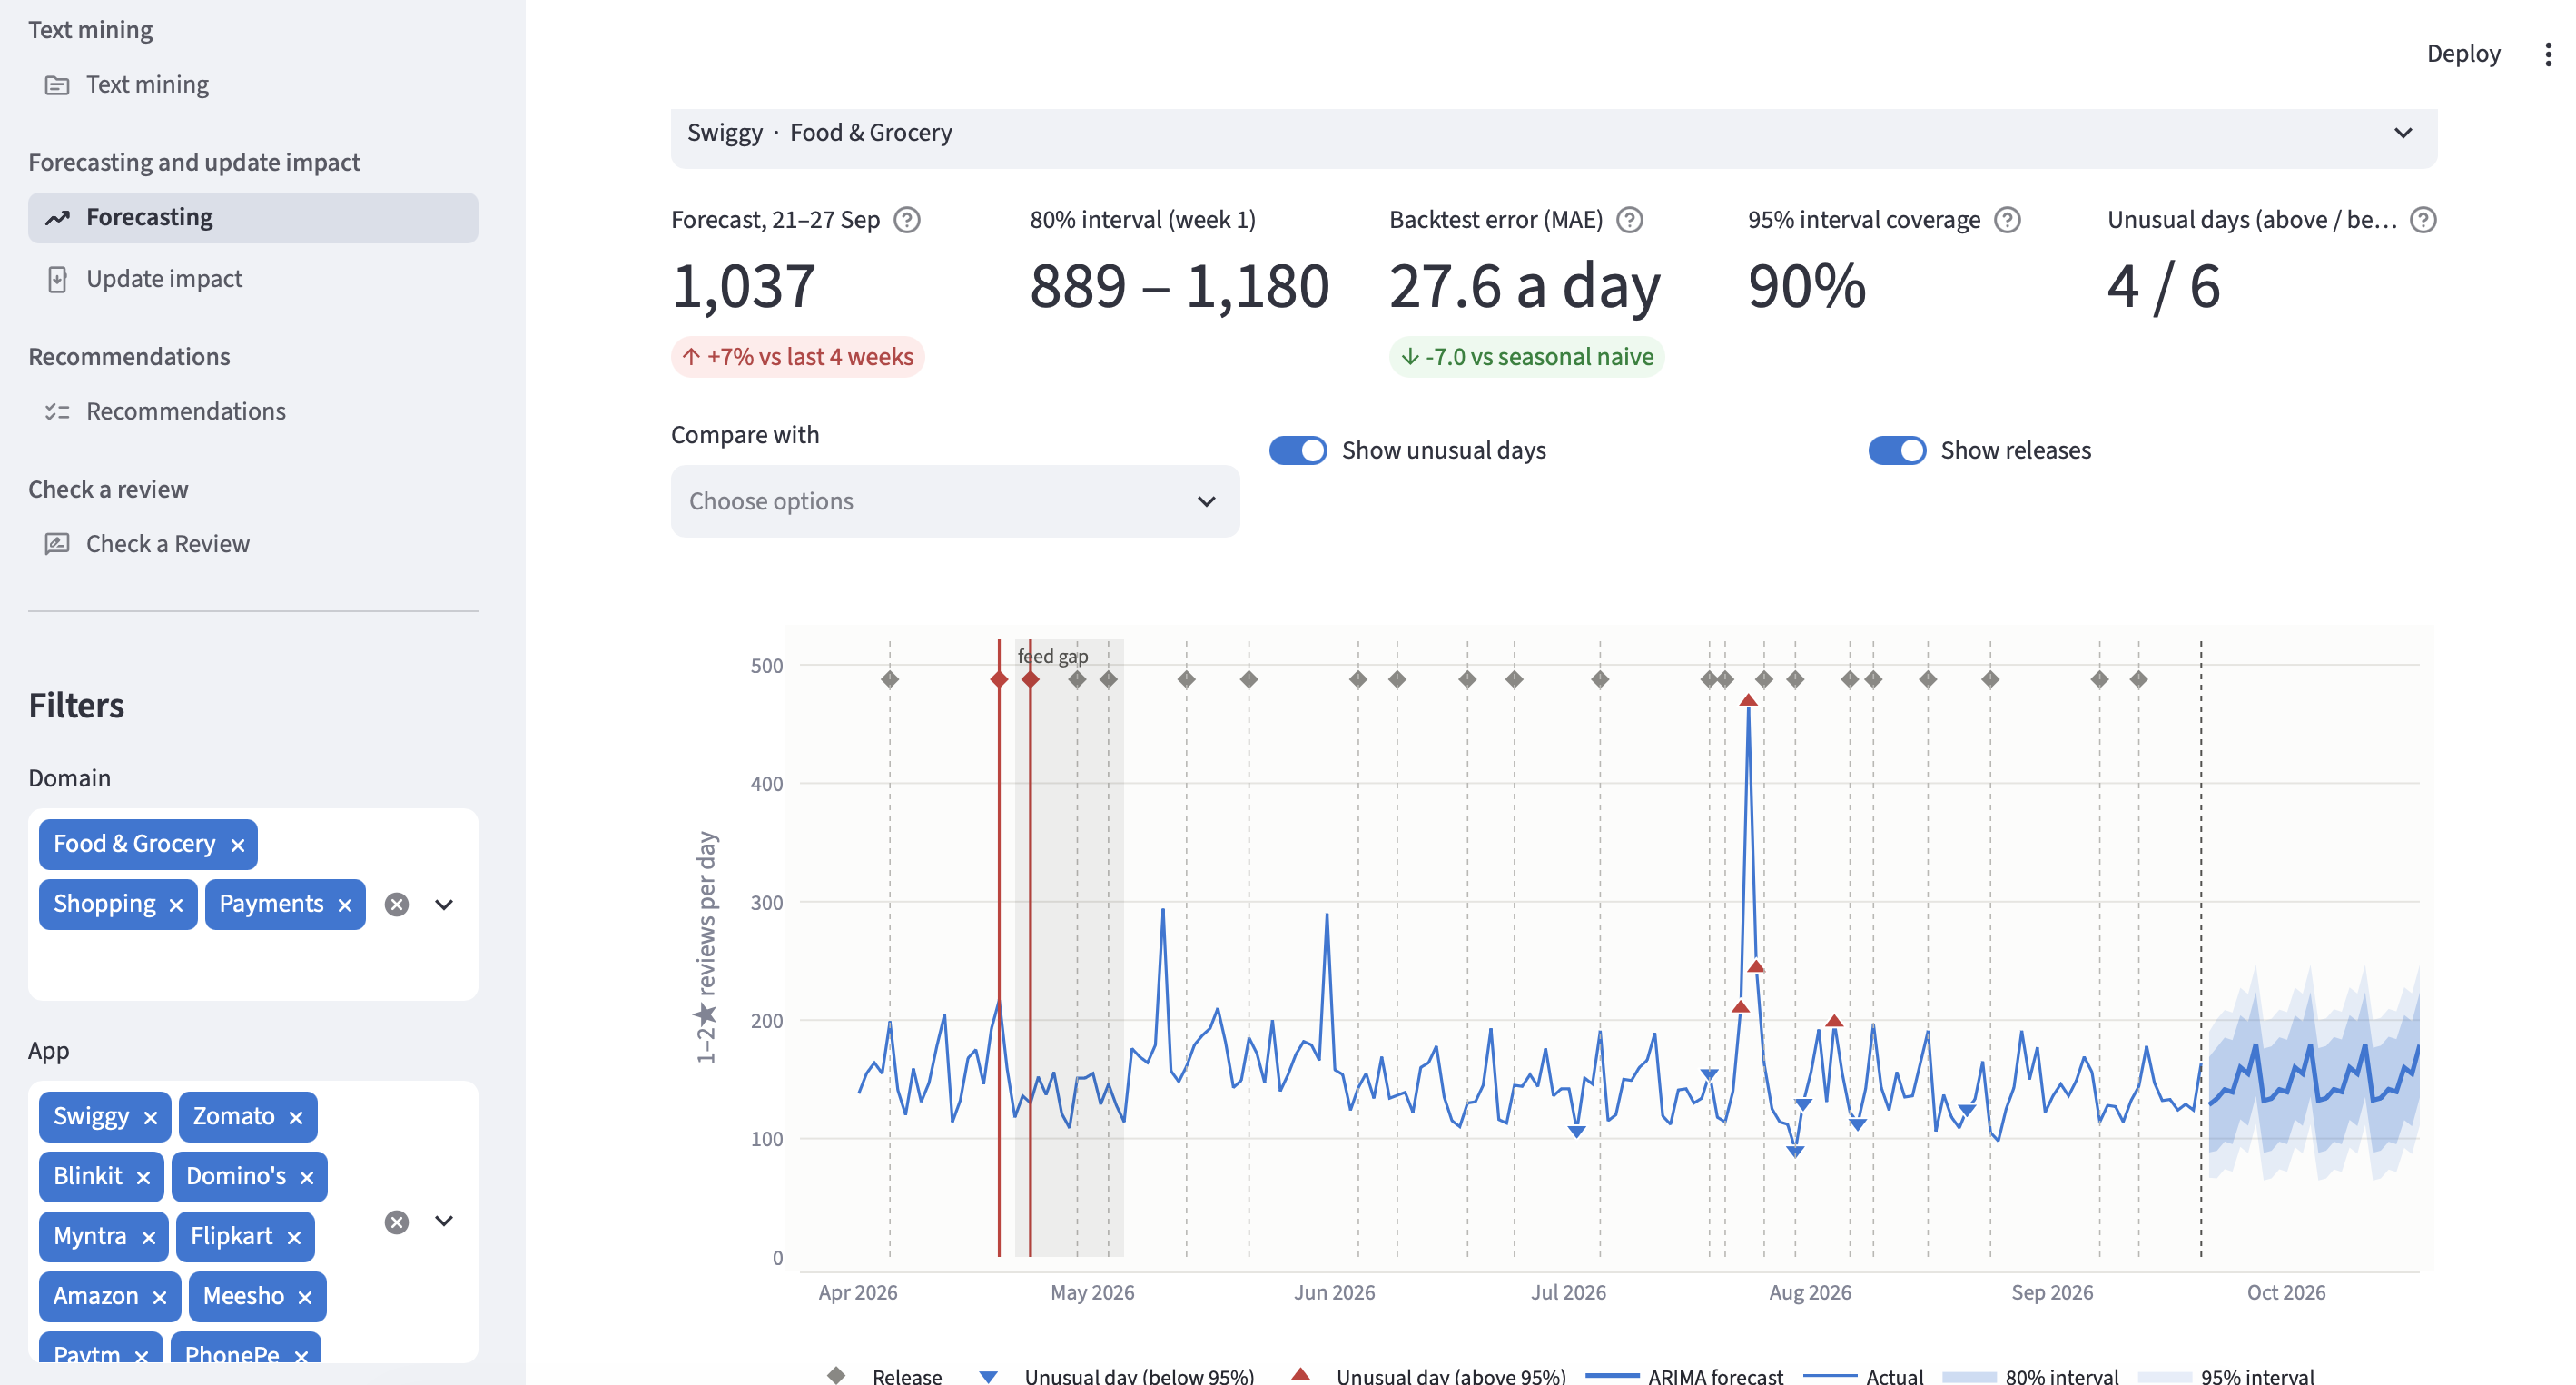

**Update Impact page**

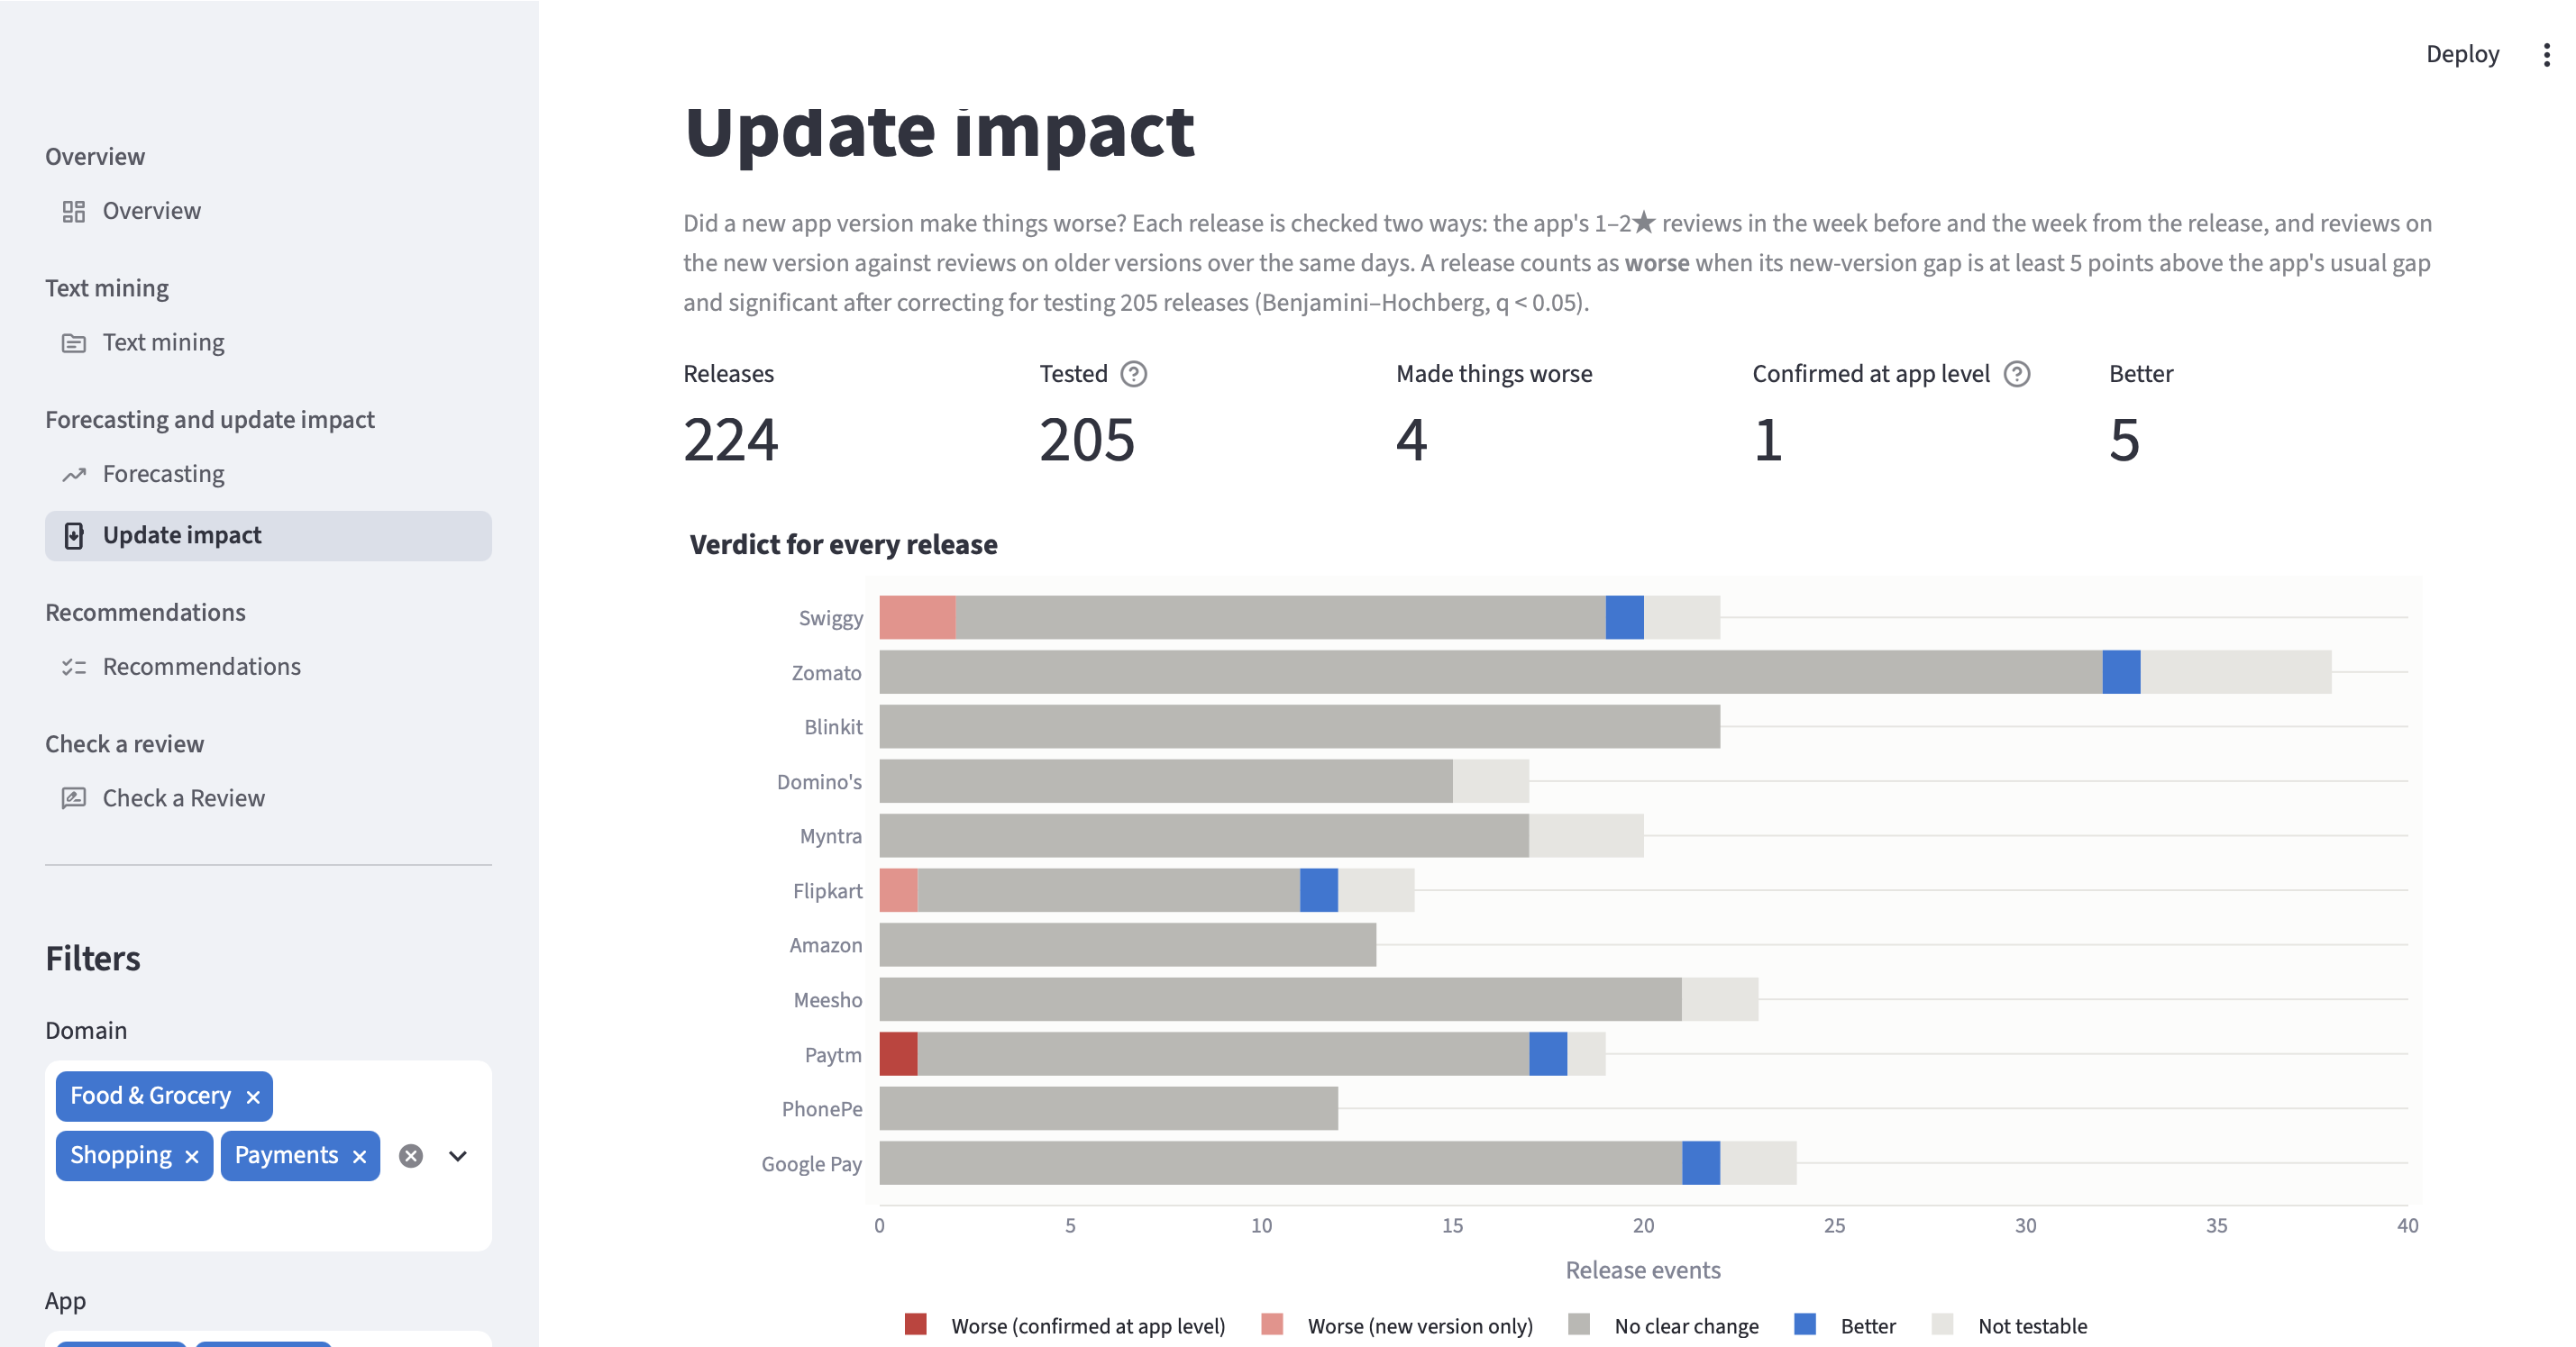

**Recommendations page**

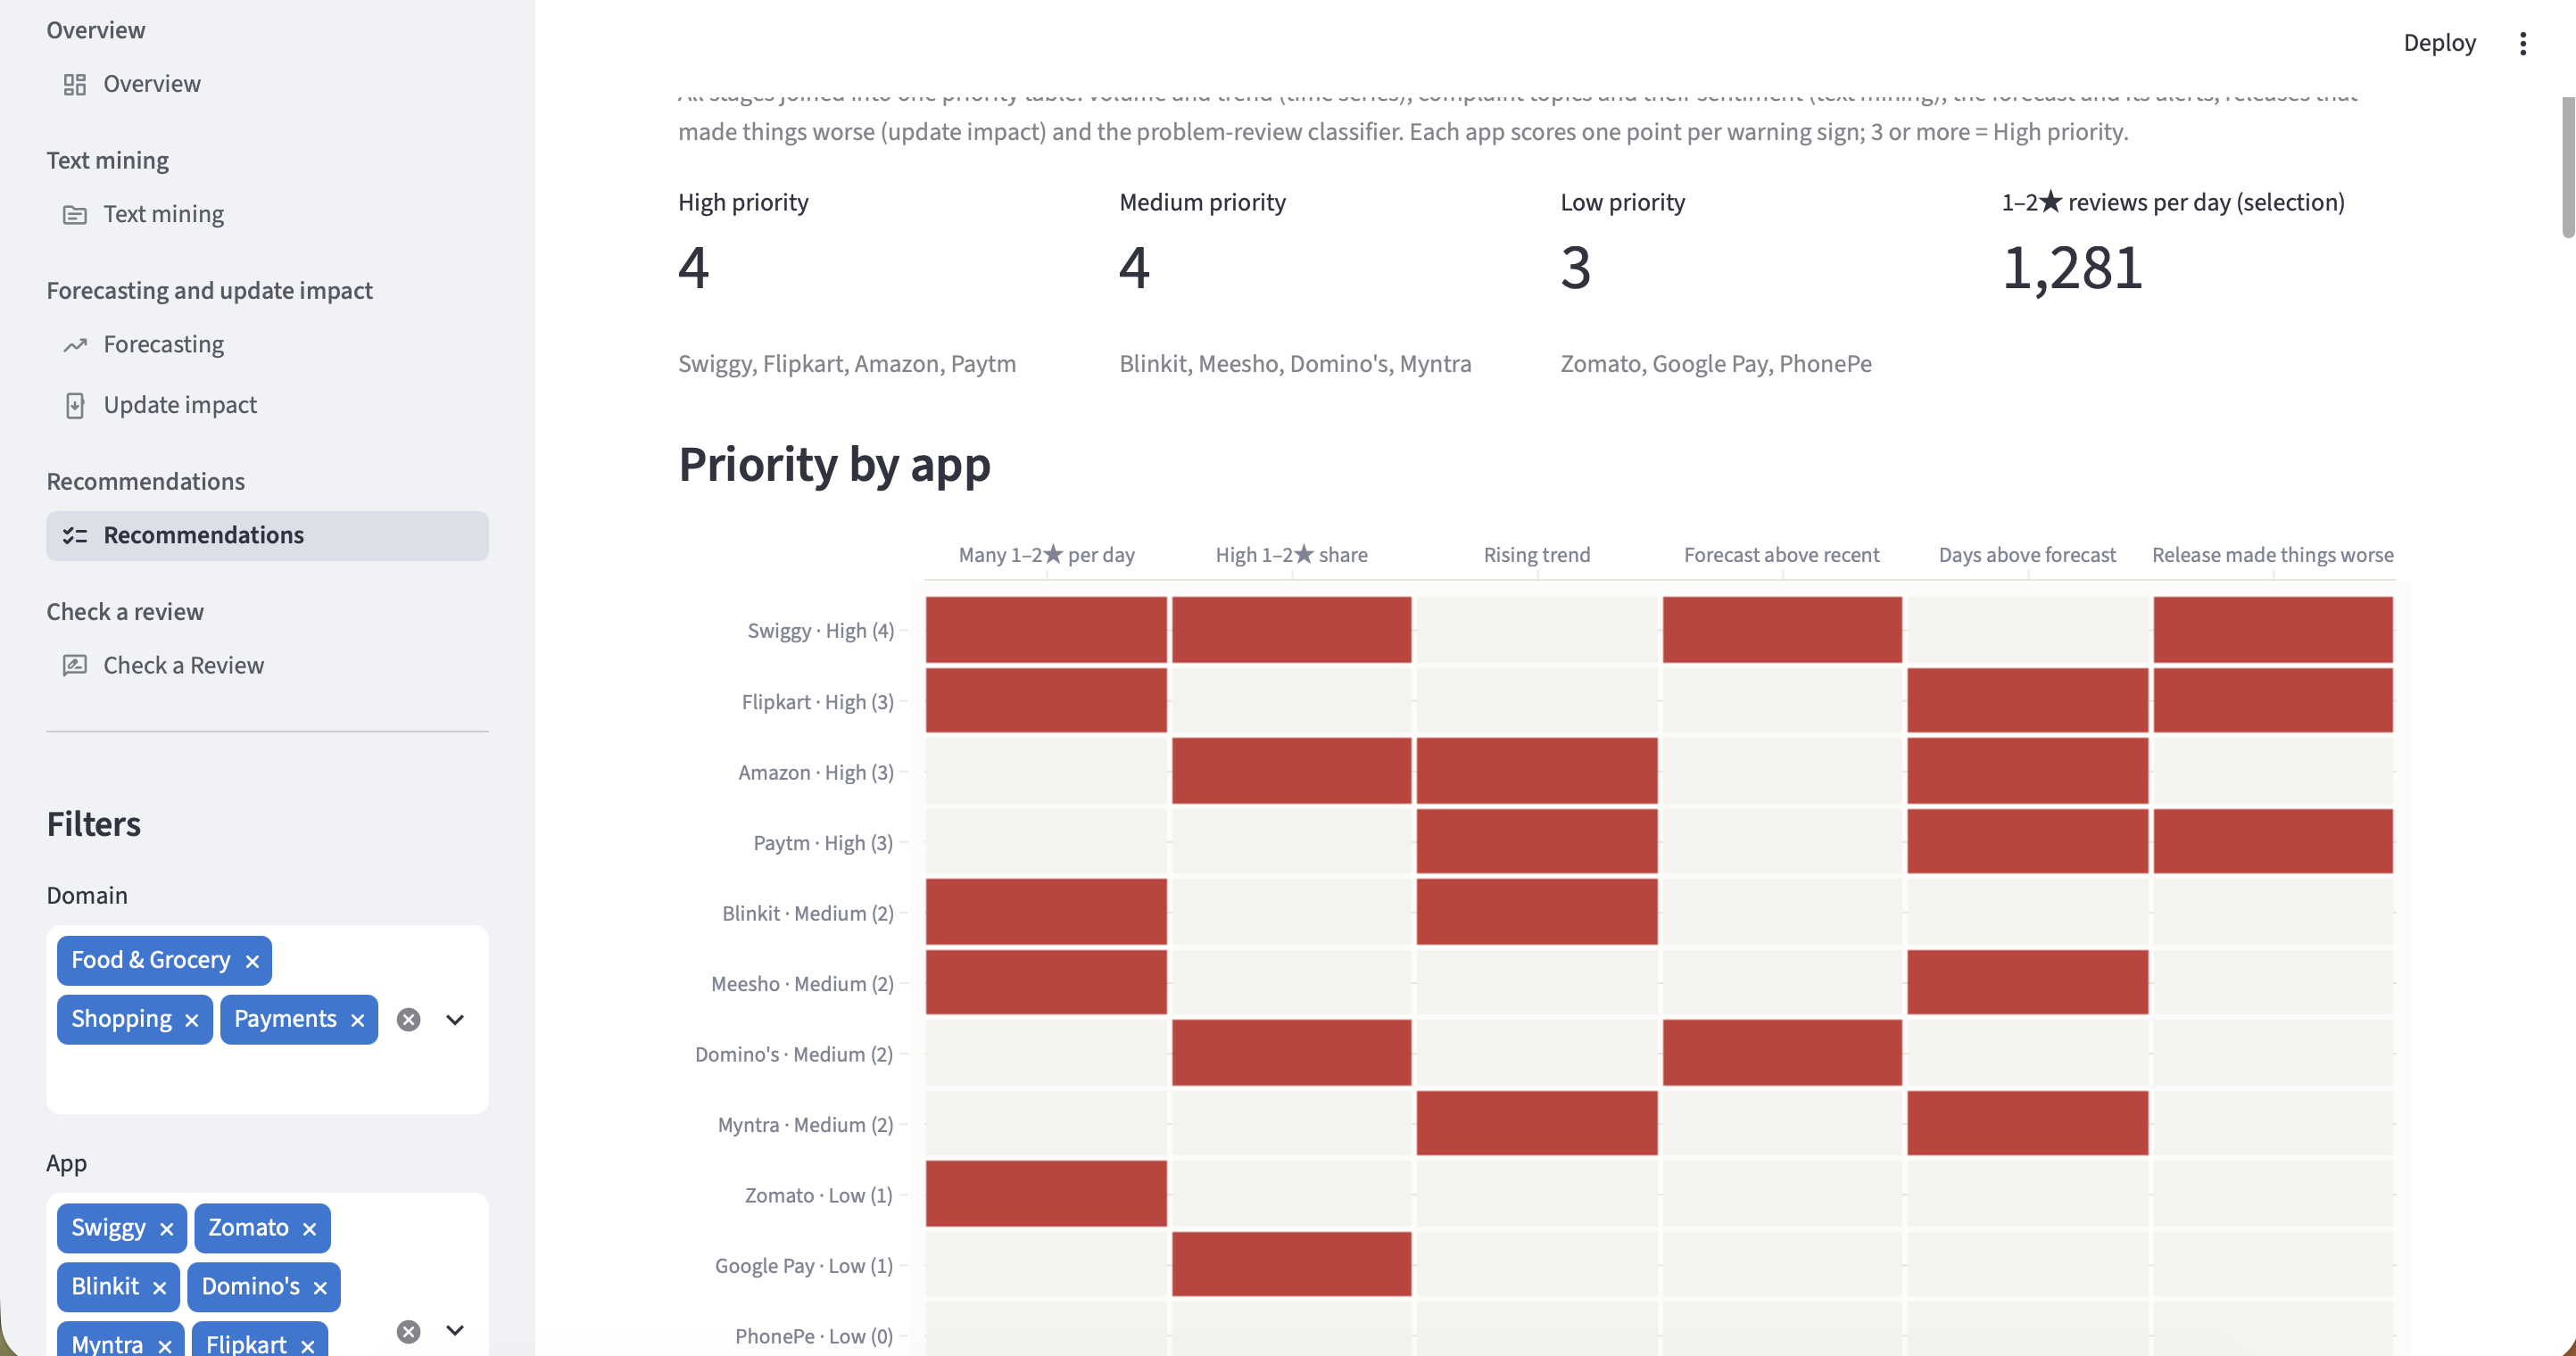

**Check Review page**

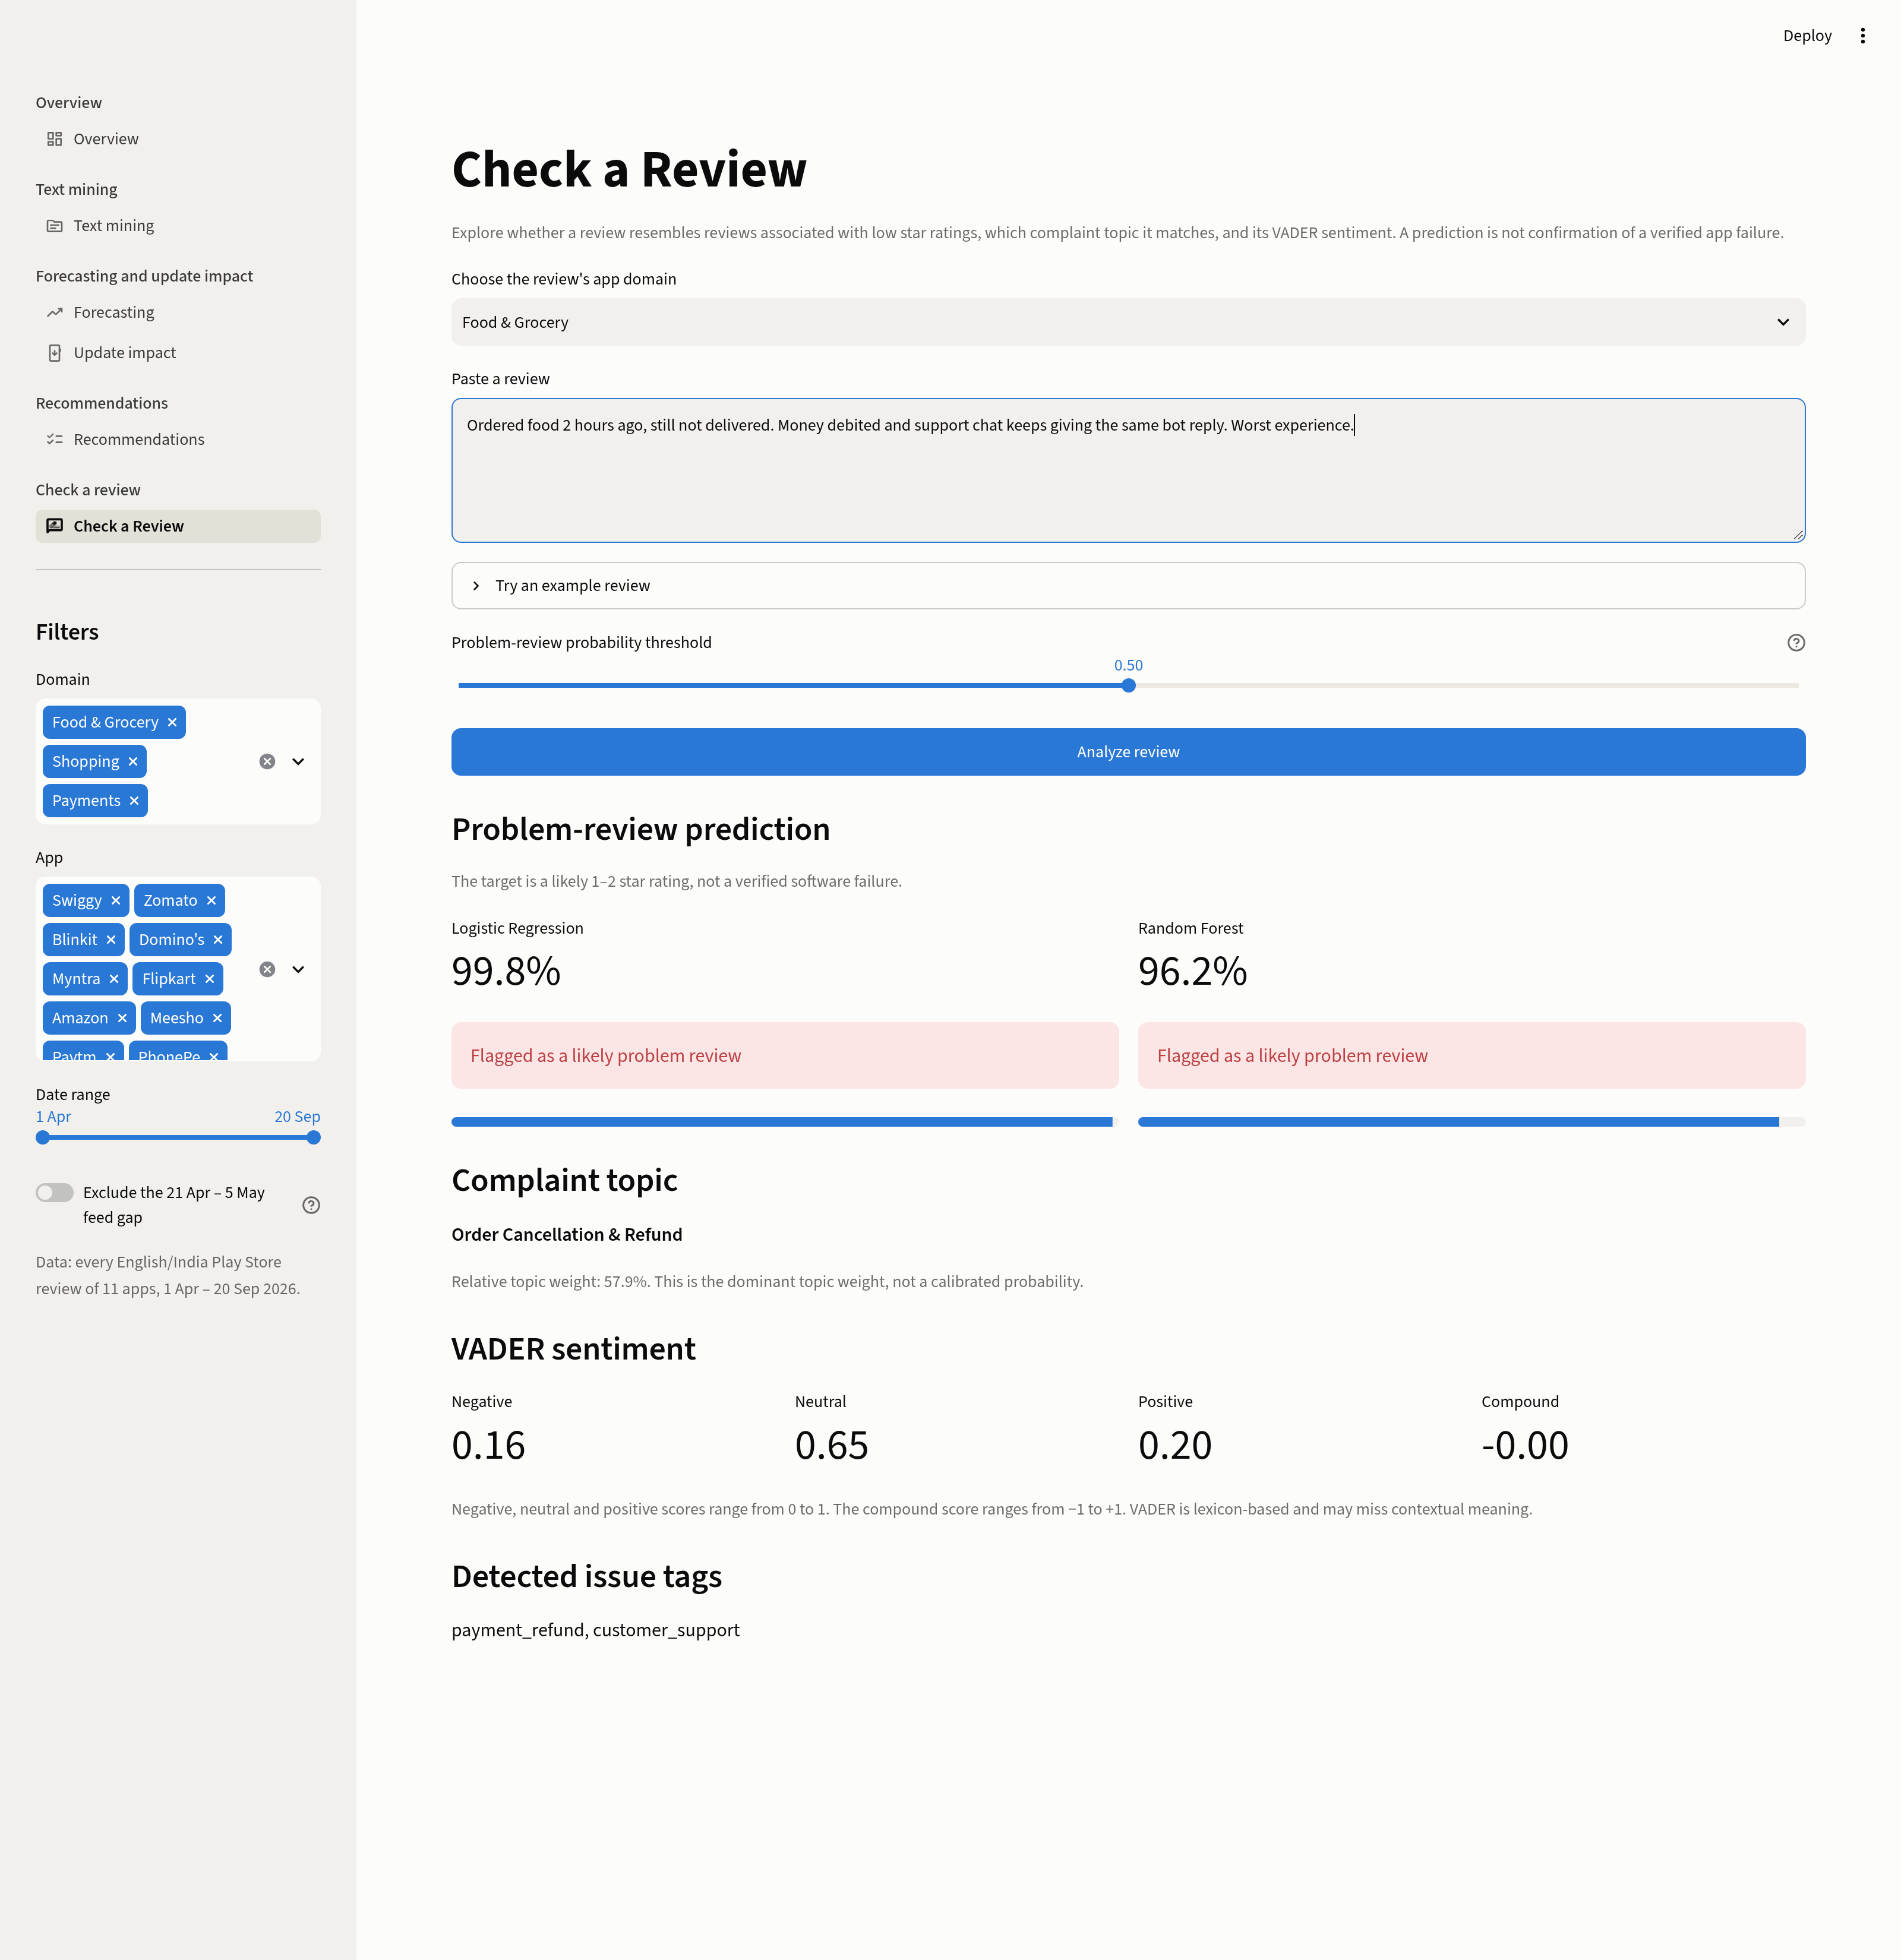

In [37]:
for page in ["overview", "text_mining", "forecasting", "update_impact", "recommendations", "check_review"]:
    display(Markdown(f"**{page.replace('_', ' ').title()} page**"))
    display(Image(filename=str(REPO / "dashboard" / "screenshots" / f"{page}.png"), width=800))

## 7. Conclusions

1. **Text mining** turns 167,000 complaint reviews into 17 interpretable themes. Volume and anger rank them differently: the biggest themes are operational (refunds, returns, failed transfers), the angriest are quality, scam allegations and unanswered support.
2. **Time-series forecasting** gives each app a usable 4-week forecast: ARIMA beats the seasonal-naive baseline on 10 of 11 apps with near-nominal 80% interval coverage, and its 95% interval turns into a daily alert for unusual days.
3. **Update impact** shows that most releases are harmless; the one clearly bad release (Paytm 10.84.5) is visible in three independent ways — new-version share, app-level counts and forecast alerts.
4. **Combined**, the stages give one priority list: Swiggy, Flipkart, Amazon and Paytm first, each with a specific topic to fix, a release to review where relevant, a forecast for staffing and a classifier to triage reviews.

**Limits.** Reviews are a self-selected sample from the Play Store's "newest" feed; a 1–2★ review is a user's judgement, not a confirmed defect; the late-April feed gap inflates negativity for five apps; 173 days allow no yearly pattern; users choose when to update, so version comparisons can carry a residual bias even after the app baseline.

### Where to find everything

| Need | Where |
|---|---|
| Final dataset, data dictionary, sample, validation | `data/tagged/`, `DATA_SOURCES.md`, `DATA_DICTIONARY.md`, `data/sample/final_dataset_sample.csv`, `DATA_VALIDATION.md`, `scripts/24_dataset_documentation.py` |
| Units 1 and 2 (EDA, classifier) | `EDA.md`, `MODEL_EVALUATION.md`, `notebooks/Review_1_Analysis.ipynb`, `scripts/25_train_only_preprocessing_check.py` |
| Full report | `FINAL_REPORT.md` (PDF: `docs/Final_Report.pdf`) |
| Text mining method and results | `TEXT_MINING.md`, `scripts/16`–`18`, `23` (NMF vs LDA), `data/textmining/`, `data/charts/textmining/` |
| Time-series preparation, forecasting and evaluation | `TIME_SERIES.md` §1–2, `scripts/15`, `19`, `20`, `data/timeseries/`, `data/charts/timeseries/` |
| Update impact | `TIME_SERIES.md` §3, `scripts/21_update_impact.py`, `data/update_impact/`, `data/charts/update_impact/` |
| Combined insights and recommendations | `COMBINED_INSIGHTS.md`, `scripts/22_combined_insights.py`, `data/combined/` |
| Dashboard | `dashboard/`, `dashboard/README.md` |